# Footprint: страты, энергия, радиус и окно

Продолжение `wwlln_reader_dose.ipynb`. В основном ноутбуке доза может считаться у footprint, а страты — широта, долгота, сезон и ночь — остаются у точки под спутником. У экватора это разные места, расхождение доходит до 900–1200 км. Здесь `strata_by_geometry=True`: координаты подменяются на footprint до биннинга, поэтому страты, ночь и доза считаются в одной геометрии. Сопряжённая точка в коде закомментирована.

Null не считается (`NULL_LAGS=()`). На кривых — рост Мантеля–Хензеля относительно бина «доза = 0». Сетка времени 1 минута, пространственные бины 2°×2°, страты 12×12 (15° по широте и 30° по долготе). Ночь — зенитный угол Солнца больше 98° на поверхности.

**Сохранённые прогоны сняты на разных наборах суток.** Загрузка печатает 363 суток оценки, 2025-01-01…2025-12-31: день берётся, если есть хотя бы один из ka1 и ka2 (файлов ka1 — 345, ka2 — 363). Baseline и медиана энергии строили сетки на 366 суток, экспозиция 58 149 991 с. Sweep по R/Δt — на 347 суток, экспозиция 56 986 414 с. Повторный прогон сверху вниз перезапишет рисунки и посчитает sweep на сутках текущей загрузки.

**Крупные блоки**

1. **Baseline, R = 1000 км, Δt = 30 мин.** Накопитель `accum_fp_consistent` и локальный отчётный бин. `dp.report_bin` по умолчанию молчит, пока `rr_n` равен NaN; с `require_null=False` отбирает так же, как локальная функция. Сохранённый отчётный бин — «≥3000»: ka1 рост MH 2.858 (2.55–3.24), ka2 2.632 (2.37–3.00). В §4.8 основного ноутбука при подспутниковых стратах было ka1 = 2.84, ka2 = 2.33.
2. **Разбор этого baseline.** Прирост между соседними бинами, абсолютный уровень, forest plot против дозы 0, расхождение ka1/ka2 на «≥3000», карты покрытия, дыра AACGM у экватора, ночь и день, сезоны, месяцы внутри локального сезона.
3. **Медиана энергии при фиксированной дозе**, тоже на footprint. Гистограмма из 16 тонких бинов, поэтому этот прогон на сетке 5 минут; окно дозы по-прежнему 30 минут. Терцили 0.6 и 1.9 кДж.
4. **Суточный ход энергии WWLLN** отдельно над сушей и океаном, без привязки к свисту.
5. **Радиус и окно.** Пороги дозы те же, что калибровались на 30 минут. Считаются 10 пар: пять радиусов при Δt = 30 мин и шесть окон при R = 1000 км. Рисунок — P(сегмент) − P(доза=0), день и ночь. Следом бинарный срез «хотя бы одна молния» против нуля, на том же прогоне.
6. **Камчатка.** Рамка полуострова на 1° карте внутри грубой страты 45…60°N / 150…180°E и сырое сравнение этой рамки с остальной полосой той же широты.


## 1. Загрузка

Схема страт «долгота», без блока энергии в этом проходе. Baseline: R = 1000 км, Δt = 30 мин, сетка 1 мин × 2° × 2°, 12×12 страт, footprint на высоте 827 км. День входит в оценку, если есть хотя бы один из ka1 и ka2.

Сохранённый прогон этой ячейки: 363 суток, 2025-01-01…2025-12-31.


In [1]:
%%time
import importlib

import numpy as np
import pandas as pd

import wwlln_common as wc
import dose_pipeline as dp
import mag_coords
importlib.reload(wc)
importlib.reload(mag_coords)
importlib.reload(dp)

# baseline — тот же, что в основном ноутбуке; без энергии (do_energy не нужен здесь)
DOSE_R_KM = 1000.0
DOSE_DT_MIN = 30
GLAT, GLON, GDT_MIN = 2.0, 2.0, 1  # 1 мин: окна Δt=2 и Δt=5 попадают на границы сетки.
                                    # Без null кэш держит 1–2 суток, мелкая сетка по времени дешёвая
STRATA_SCHEME = 'lon'
N_LATB = 12
N_LONB = 12
NULL_LAGS = ()                   # null-модель убрана целиком (не только не смотрим —
NULL_SYMMETRIC = False           # не считаем вообще: null_lags=() отключает лаги в
NULL_SEASON_SAFE = True          # run_accumulation, кэш сеток держит только 1-2 суток,
                                  # а не окно в несколько недель вперёд/назад)
MAX_LAG = max(NULL_LAGS) if NULL_LAGS else 0
LOOKAHEAD = MAX_LAG if NULL_SYMMETRIC else 0
DOSE_MAX_DAYS = None             # число — для быстрого пилота перед полным прогоном
DOSE_SC = ('ka1', 'ka2')
NIGHT_SZA_DEG = wc.NIGHT_SZA_DEG
SAT_HEIGHT_KM = 827.0

MIN_STRAT_EXP = 300
MIN_REPORT_EXP = 15000
N_BOOT = 200
REF_BIN = 0

DOSE_EDGES = dp.DEFAULT_DOSE_EDGES
DOSE_LABELS = dp.DEFAULT_DOSE_LABELS

_paths_d = wc.resolve_paths()
DOSE_DAYS = wc.analysis_days(_paths_d['pred'], _paths_d['ae'], DOSE_SC, require_all_sc=False)
if DOSE_MAX_DAYS is not None:
    DOSE_DAYS = DOSE_DAYS[:DOSE_MAX_DAYS]
_dc = wc.day_codes(DOSE_DAYS)
DOSE_DAYCODES = set(int(c) for c in _dc)
AE_DAYS = [str(np.datetime64(int(c), 'D')).replace('-', '')
           for c in range(int(_dc.min()) - MAX_LAG - 1, int(_dc.max()) + LOOKAHEAD + 1)]
print(f'Период оценки: {len(DOSE_DAYS)} суток ({DOSE_DAYS[0]} … {DOSE_DAYS[-1]})')

df, df_pred = wc.ensure_data(globals(), days=DOSE_DAYS, ae_days=AE_DAYS)

_pts_all = df_pred['timestamp'].values
pred_days_present = set(_pts_all.astype('datetime64[D]').astype(np.int64).tolist())
ae_t_all = df['datetime'].values
ae_day0 = ae_t_all[0].astype('datetime64[D]').astype(np.int64)
ae_day1 = ae_t_all[-1].astype('datetime64[D]').astype(np.int64)
acc_days = sorted(d for d in DOSE_DAYCODES if d in pred_days_present and ae_day0 <= d <= ae_day1)
if not acc_days:
    raise ValueError('Нет суток, где есть и предсказания всех КА, и AE')
print(f'Дней с оценкой: {len(acc_days)} ({np.datetime64(acc_days[0], "D")} … {np.datetime64(acc_days[-1], "D")})')


Период оценки: 363 суток (20250101 … 20251231)
df не найден — загружаю молнии
AE из кэша: /Users/user/Downloads/wwlln/cache/AE_20250101_20251231.parquet
AE: в кэше нет 1 из запрошенных дней (20241231…20241231) — дочитываю из .loc.gz
AE: читаю 0 файлов из /Users/user/Downloads/wwlln/WWLLN/AEfiles
df_pred не найден — загружаю предсказания
ka1: 345 файлов из /Users/user/Downloads/wwlln/predictions/whistler_binary/ka1
ka2: 363 файлов из /Users/user/Downloads/wwlln/predictions/whistler_binary/ka2
Дней с оценкой: 363 (2025-01-01 … 2025-12-31)
CPU times: user 1min 12s, sys: 35.8 s, total: 1min 48s
Wall time: 1min 36s


## 2. Baseline: footprint-страты, R = 1000 км, Δt = 30 мин

`strata_by_geometry=True`: широта, долгота, сезон, ночь и сама доза считаются в точке footprint. `null_lags=()` — лаги null не строятся, кэш сеток держит текущие и предыдущие сутки. Сетка 1 минута, чтобы окна 2 и 5 минут попадали на границы временных бинов.

Сохранённый прогон: 366 суток сетки, экспозиция 58 149 991 с, доля `verdict=1` 8.41%. Сводка — в локальном отчётном бине ниже. Для сравнения, §4.8 основного ноутбука (страты у подспутниковой точки, доза у footprint, сетка 5 мин): ka1 = 2.84, ka2 = 2.33.


In [2]:
%%time
import traceback

accum_fp_consistent = None
try:
    accum_fp_consistent = dp.run_accumulation(
        df, df_pred, sc_list=DOSE_SC, acc_days=acc_days,
        dose_r_km=DOSE_R_KM, dose_dt_min=DOSE_DT_MIN,
        glat=GLAT, glon=GLON, gdt_min=GDT_MIN,
        null_lags=NULL_LAGS, null_symmetric=NULL_SYMMETRIC, null_season_safe=NULL_SEASON_SAFE,
        do_energy=False, night_sza_deg=NIGHT_SZA_DEG, strata_scheme=STRATA_SCHEME, n_lonb=N_LONB, n_latb=N_LATB,
        geometry="footprint", sat_height_km=SAT_HEIGHT_KM, strata_by_geometry=True,
        dose_edges=DOSE_EDGES,
    )
    print(f"accum_fp_consistent готов ({accum_fp_consistent['exp_true_d'].sum():,.0f} "
          "сэмплов). Сводку и график см. в следующих ячейках (report_bin() из dose_pipeline "
          "здесь не подходит — требует null, а мы его не считаем; ниже локальный вариант).")
except Exception:
    print("!!! ОШИБКА в accum_fp_consistent:")
    traceback.print_exc()

# --- conjugate (согласованные страты) --- закомментировано, раньше уже показал
# слабый/незначимый эффект даже с подспутниковыми стратами; включить при желании перепроверить
# accum_cj_consistent = dp.run_accumulation(
#     df, df_pred, sc_list=DOSE_SC, acc_days=acc_days,
#     dose_r_km=DOSE_R_KM, dose_dt_min=DOSE_DT_MIN,
#     glat=GLAT, glon=GLON, gdt_min=GDT_MIN,
#     null_lags=NULL_LAGS, null_symmetric=NULL_SYMMETRIC, null_season_safe=NULL_SEASON_SAFE,
#     do_energy=False, night_sza_deg=NIGHT_SZA_DEG, strata_scheme=STRATA_SCHEME, n_lonb=N_LONB, n_latb=N_LATB,
#     geometry="conjugate", sat_height_km=SAT_HEIGHT_KM, strata_by_geometry=True,
#     dose_edges=DOSE_EDGES,
# )


Накопители: 172 МБ; сетки строим для 366 дней (схема страт='lon', лаги=() назад, сезонный фильтр=вкл)
  ... 20/366 дней
  ... 40/366 дней
  ... 60/366 дней
  ... 80/366 дней
  ... 100/366 дней
  ... 120/366 дней
  ... 140/366 дней
  ... 160/366 дней
  ... 180/366 дней
  ... 200/366 дней
  ... 220/366 дней
  ... 240/366 дней
  ... 260/366 дней
  ... 280/366 дней
  ... 300/366 дней
  ... 320/366 дней
  ... 340/366 дней
  ... 360/366 дней
Готово. Экспозиция: 58,149,991 сэмплов, verdict=1: 4,890,665 (8.41%); экспозиция null: 0 (в среднем 0.00 лага/сутки использовано из 0 возможных)
accum_fp_consistent готов (58,149,992 сэмплов). Сводку и график см. в следующих ячейках (report_bin() из dose_pipeline здесь не подходит — требует null, а мы его не считаем; ниже локальный вариант).
CPU times: user 8min 40s, sys: 6min 7s, total: 14min 47s
Wall time: 17min 10s


### Отчётный бин без требования null

`dp.report_bin()` по умолчанию берёт бин только если конечны и `rr_t`, и `rr_n`. При пустых лагах `rr_n` равен NaN, и функция ничего не возвращает. Ниже тот же отбор по экспозиции и числу страт, только по `rr_t`, на уже готовом `accum_fp_consistent`; в модуле это `dp.report_bin(..., require_null=False)`.

Сохранённая таблица: отчётный бин «≥3000», ka1 рост MH 2.858 (2.55–3.24, 35 страт, 71 059 с), ka2 2.632 (2.37–3.00, 37 страт, 77 261 с).


In [3]:
import numpy as np
import pandas as pd

def report_bin_no_null(r, min_exp, min_strata, ref_bin):
    ok = np.isfinite(r['rr_t']) & (r['expo'] >= min_exp) & (r['nst'] >= min_strata)
    ok[ref_bin] = False
    idx = np.flatnonzero(ok)
    return int(idx[-1]) if idx.size else None

rows = []
for si, sc in enumerate(DOSE_SC):
    r = dp.analyze(accum_fp_consistent, sc=si, n_boot=N_BOOT, ref_bin=REF_BIN, min_strat_exp=MIN_STRAT_EXP)
    k = report_bin_no_null(r, min_exp=MIN_REPORT_EXP, min_strata=5, ref_bin=REF_BIN)
    if k is None:
        rows.append({'КА': sc, 'бин': 'нет носителя'})
        continue
    rows.append({
        'КА': sc, 'бин': DOSE_LABELS[k],
        'рост MH': r['rr_t'][k], 'CI': f"{r['ci_t'][0,k]:.2f}\u2013{r['ci_t'][1,k]:.2f}",
        'страт': int(r['nst'][k]), 'экспозиция': int(r['expo'][k]),
    })
fp_consistent_summary_fixed = pd.DataFrame(rows)
display(fp_consistent_summary_fixed.round(3))
print('Для сравнения, §4.8 основного ноутбука (страты подспутниковые, доза footprint, '
      '5-мин сетка, рост MH на отчётном бине): ka1=2.84, ka2=2.33.')


,КА,бин,рост MH,CI,страт,экспозиция
0,ka1,≥3000,2.858,2.55–3.24,35,71059
1,ka2,≥3000,2.632,2.37–3.00,37,77261


Для сравнения, §4.8 основного ноутбука (страты подспутниковые, доза footprint, 5-мин сетка, рост MH на отчётном бине): ka1=2.84, ka2=2.33.


### Прирост уровня между соседними бинами

На baseline. Бин «0» оставлен абсолютным P(`verdict=1`). Остальные точки — прирост excess[k] − excess[k−1], где excess[k] = P(бин k) − P(доза=0) на общем носителе этого бина. Интервал — парная разность на одних и тех же бутстрап-репликах. Горизонтальная полоса — уровень при дозе 0.


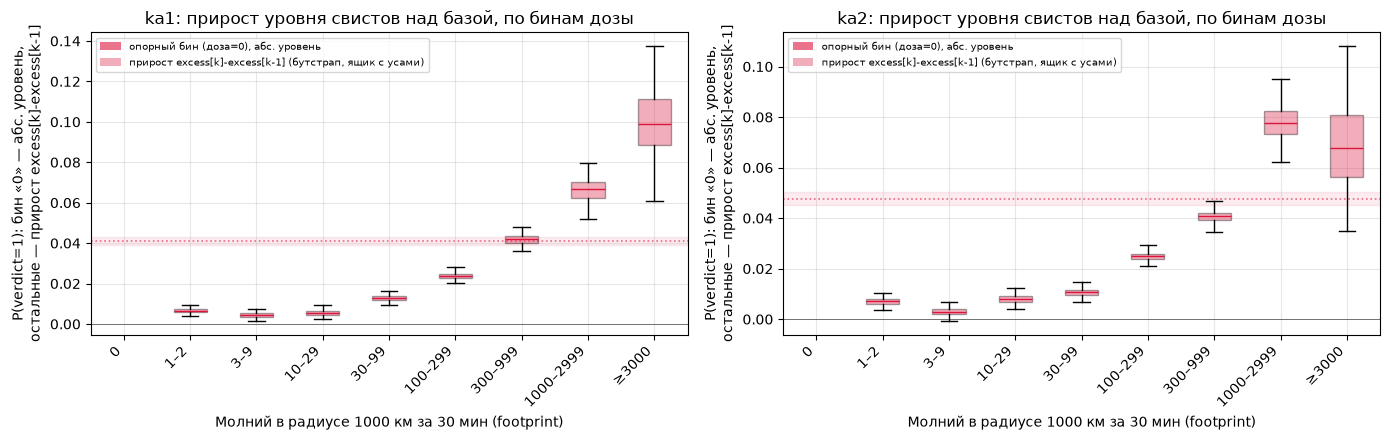

excess[k] = pk_t[k] - p0_t[k] (сплошная минус пунктирная линия старой версии графика, но по-бинно — p0_t не константа). Ящик — разность excess[k]-excess[k-1] на ОДНИХ И ТЕХ ЖЕ бутстрап-репликах (парная разность): убирает и то, что бин «300-999» «содержит» диапазон «100-299», и дрейф самой базы между бинами (разный общий носитель на каждый k).


In [17]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

SHOW_BIN_3000 = True  # False — не рисовать последний (открытый, ненадёжный) бин «≥3000»
dose_sl = slice(None) if SHOW_BIN_3000 else slice(None, -1)
n_bins_show = len(DOSE_LABELS[dose_sl])
x = np.arange(n_bins_show)

fig, axes = plt.subplots(1, len(DOSE_SC), figsize=(7 * len(DOSE_SC), 4.5), squeeze=False)
for si, sc in enumerate(DOSE_SC):
    r = dp.analyze(accum_fp_consistent, sc=si, n_boot=N_BOOT, ref_bin=REF_BIN, min_strat_exp=MIN_STRAT_EXP)
    ax = axes[0, si]

    # базовый уровень (доза=0) — как раньше, вычитать не из чего, оставляем абсолютным уровнем
    ax.axhline(r["p0_t"][0], color="crimson", alpha=0.6, ls=":", lw=1.2)
    ax.axhspan(r["ci_p0_t"][0, 0], r["ci_p0_t"][1, 0], color="crimson", alpha=0.08)

    # excess[k] = pk_t[k] - p0_t[k] — превышение НАД СВОЕЙ базой (p0_t не константа,
    # пересчитывается на общем носителе для каждого k отдельно, см. bp0_t). Бины 1..N —
    # разница excess[k]-excess[k-1] = (pk_t[k]-pk_t[k-1]) - (p0_t[k]-p0_t[k-1]):
    # убираем и кумулятивный эффект предыдущего бина, и дрейф самой базы между бинами.
    # Всё на ОДНИХ И ТЕХ ЖЕ бутстрап-репликах (парная разность) — честный CI.
    excess_boot = r["bpk_t"] - r["bp0_t"]  # (n_boot, n_dose)
    box_data, box_pos = [], []
    for k in range(1, n_bins_show):
        diff_boot = excess_boot[:, k] - excess_boot[:, k - 1]
        diff_boot = diff_boot[np.isfinite(diff_boot)]
        if diff_boot.size:
            box_data.append(diff_boot)
            box_pos.append(k)
    if box_data:
        bp = ax.boxplot(box_data, positions=box_pos, widths=0.5, patch_artist=True, showfliers=False)
        for patch in bp["boxes"]:
            patch.set_facecolor("crimson")
            patch.set_alpha(0.35)
        for med in bp["medians"]:
            med.set_color("crimson")
    ax.axhline(0, color="black", lw=0.7, alpha=0.5)

    ax.set_xticks(x)
    ax.set_xticklabels(DOSE_LABELS[dose_sl], rotation=45, ha="right")
    ax.set_xlim(-0.5, n_bins_show - 0.5)
    ax.set_xlabel(f"Молний в радиусе {DOSE_R_KM:.0f} км за {DOSE_DT_MIN} мин (footprint)")
    ax.set_ylabel("P(verdict=1): бин «0» — абс. уровень,\nостальные — прирост excess[k]-excess[k-1]")
    ax.set_title(f"{sc}: прирост уровня свистов над базой, по бинам дозы")
    ax.grid(alpha=0.3)
    ax.legend(handles=[
        Patch(facecolor="crimson", alpha=0.6, label="опорный бин (доза=0), абс. уровень"),
        Patch(facecolor="crimson", alpha=0.35, label="прирост excess[k]-excess[k-1] (бутстрап, ящик с усами)"),
    ], fontsize=7.5, loc="upper left")
fig.tight_layout()
plt.show()
plt.close(fig)

print('excess[k] = pk_t[k] - p0_t[k] (сплошная минус пунктирная линия старой версии графика, '
      'но по-бинно — p0_t не константа). Ящик — разность excess[k]-excess[k-1] на ОДНИХ И ТЕХ ЖЕ '
      'бутстрап-репликах (парная разность): убирает и то, что бин «300-999» «содержит» диапазон '
      '«100-299», и дрейф самой базы между бинами (разный общий носитель на каждый k).')

### Тот же прирост, без полосы уровня при дозе 0

Те же ящики. Опорная линия и полоса бина «0» сняты.


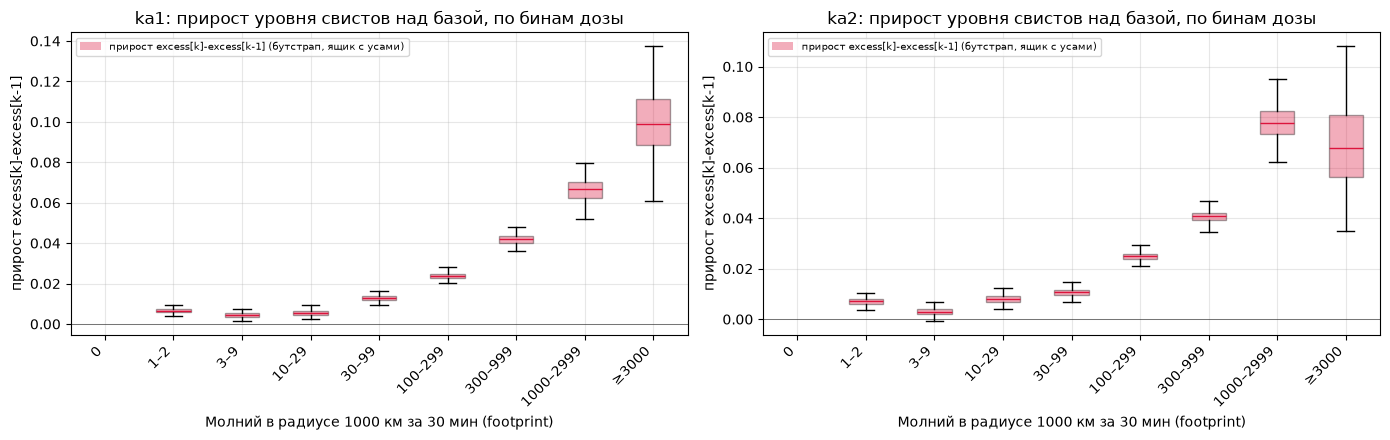

In [19]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

SHOW_BIN_3000 = True  # False — не рисовать последний (открытый, ненадёжный) бин «≥3000»
dose_sl = slice(None) if SHOW_BIN_3000 else slice(None, -1)
n_bins_show = len(DOSE_LABELS[dose_sl])
x = np.arange(n_bins_show)

fig, axes = plt.subplots(1, len(DOSE_SC), figsize=(7 * len(DOSE_SC), 4.5), squeeze=False)
for si, sc in enumerate(DOSE_SC):
    r = dp.analyze(accum_fp_consistent, sc=si, n_boot=N_BOOT, ref_bin=REF_BIN, min_strat_exp=MIN_STRAT_EXP)
    ax = axes[0, si]

    # excess[k] = pk_t[k] - p0_t[k] — превышение НАД СВОЕЙ базой (p0_t не константа,
    # пересчитывается на общем носителе для каждого k отдельно, см. bp0_t). Бины 1..N —
    # разница excess[k]-excess[k-1] = (pk_t[k]-pk_t[k-1]) - (p0_t[k]-p0_t[k-1]):
    # убираем и кумулятивный эффект предыдущего бина, и дрейф самой базы между бинами.
    # Всё на ОДНИХ И ТЕХ ЖЕ бутстрап-репликах (парная разность) — честный CI.
    excess_boot = r["bpk_t"] - r["bp0_t"]  # (n_boot, n_dose)
    box_data, box_pos = [], []
    for k in range(1, n_bins_show):
        diff_boot = excess_boot[:, k] - excess_boot[:, k - 1]
        diff_boot = diff_boot[np.isfinite(diff_boot)]
        if diff_boot.size:
            box_data.append(diff_boot)
            box_pos.append(k)
    if box_data:
        bp = ax.boxplot(box_data, positions=box_pos, widths=0.5, patch_artist=True, showfliers=False)
        for patch in bp["boxes"]:
            patch.set_facecolor("crimson")
            patch.set_alpha(0.35)
        for med in bp["medians"]:
            med.set_color("crimson")
    ax.axhline(0, color="black", lw=0.7, alpha=0.5)

    ax.set_xticks(x)
    ax.set_xticklabels(DOSE_LABELS[dose_sl], rotation=45, ha="right")
    ax.set_xlim(-0.5, n_bins_show - 0.5)
    ax.set_xlabel(f"Молний в радиусе {DOSE_R_KM:.0f} км за {DOSE_DT_MIN} мин (footprint)")
    ax.set_ylabel("прирост excess[k]-excess[k-1]")
    ax.set_title(f"{sc}: прирост уровня свистов над базой, по бинам дозы")
    ax.grid(alpha=0.3)
    ax.legend(handles=[
        Patch(facecolor="crimson", alpha=0.35, label="прирост excess[k]-excess[k-1] (бутстрап, ящик с усами)"),
    ], fontsize=7.5, loc="upper left")
fig.tight_layout()
plt.show()
plt.close(fig)

### Абсолютный уровень P(verdict=1)

Сплошная линия — уровень Мантеля–Хензеля на бине, пунктир — P(доза=0) на тех же стратах. Ящики выше показывают прирост между соседними бинами; здесь на оси сам P(verdict=1).


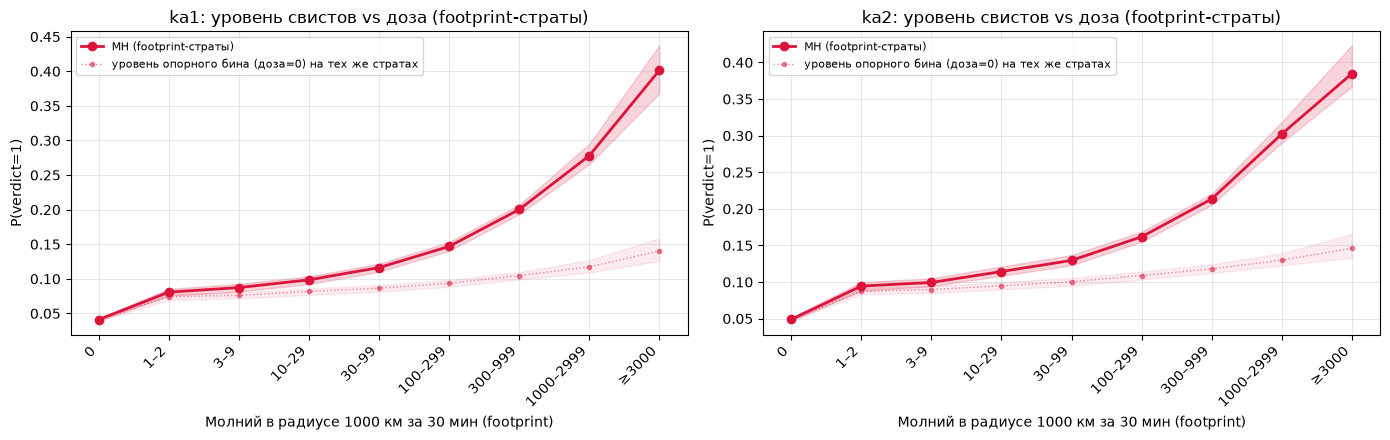

In [4]:
import numpy as np
import matplotlib.pyplot as plt

SHOW_BIN_3000 = True  # False — не рисовать последний (открытый, ненадёжный) бин «≥3000»
dose_sl = slice(None) if SHOW_BIN_3000 else slice(None, -1)

x = np.arange(len(DOSE_LABELS[dose_sl]))
fig, axes = plt.subplots(1, len(DOSE_SC), figsize=(7 * len(DOSE_SC), 4.5), squeeze=False)
for si, sc in enumerate(DOSE_SC):
    r = dp.analyze(accum_fp_consistent, sc=si, n_boot=N_BOOT, ref_bin=REF_BIN, min_strat_exp=MIN_STRAT_EXP)
    ax = axes[0, si]
    pk = np.asarray(r["pk_t"][dose_sl], dtype=float)
    p0 = np.asarray(r["p0_t"][dose_sl], dtype=float)
    ok_k, ok_0 = np.isfinite(pk), np.isfinite(p0)
    ax.plot(x, np.where(ok_k, pk, np.nan), "o-", color="crimson", lw=2, label="MH (footprint-страты)")
    ax.fill_between(x, np.where(ok_k, r["ci_pk_t"][0, dose_sl], np.nan),
                    np.where(ok_k, r["ci_pk_t"][1, dose_sl], np.nan), color="crimson", alpha=0.18)
    ax.plot(x, np.where(ok_0, p0, np.nan), ".:", color="crimson", alpha=0.5, lw=1,
            label="уровень опорного бина (доза=0) на тех же стратах")
    ax.fill_between(x, np.where(ok_0, r["ci_p0_t"][0, dose_sl], np.nan),
                    np.where(ok_0, r["ci_p0_t"][1, dose_sl], np.nan), color="crimson", alpha=0.08)
    ax.set_xticks(x)
    ax.set_xticklabels(DOSE_LABELS[dose_sl], rotation=45, ha="right")
    ax.set_xlabel(f"Молний в радиусе {DOSE_R_KM:.0f} км за {DOSE_DT_MIN} мин (footprint)")
    ax.set_ylabel("P(verdict=1)")
    ax.set_title(f"{sc}: уровень свистов vs доза (footprint-страты)")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)
fig.tight_layout()
plt.show()
plt.close(fig)

### Forest plot: каждый бин только против дозы 0

Точки не соединены: у каждого бина свой набор страт общего носителя, и линия между ними читалась бы как переход, которого эта оценка не измеряет. Переход между соседними бинами — на ящиках прироста выше, там парный бутстрап. Вертикальная линия — уровень 1, то есть равенство с дозой 0.


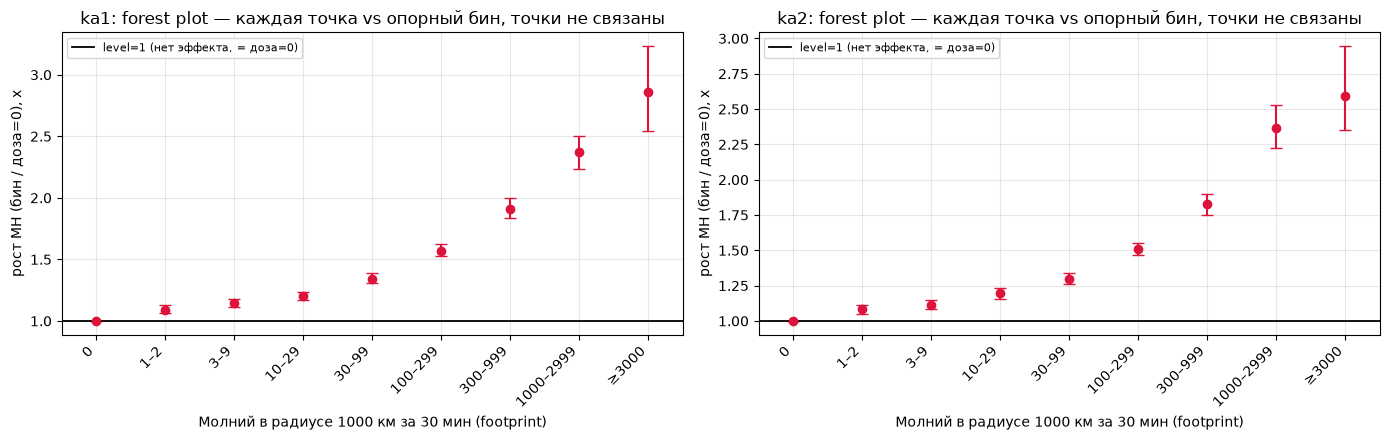

Намеренно без соединяющей линии между точками — визуально видно только то, что статистически гарантировано (каждая точка vs level=1/доза=0), а не воображаемый плавный тренд между бинами, у которого разный набор страт общего носителя за каждой точкой.


In [27]:
import numpy as np
import matplotlib.pyplot as plt

SHOW_BIN_3000 = True  # False — не рисовать последний (открытый, ненадёжный) бин «≥3000»
dose_sl = slice(None) if SHOW_BIN_3000 else slice(None, -1)
n_bins_show = len(DOSE_LABELS[dose_sl])
x = np.arange(n_bins_show)

fig, axes = plt.subplots(1, len(DOSE_SC), figsize=(7 * len(DOSE_SC), 4.5), squeeze=False)
for si, sc in enumerate(DOSE_SC):
    r = dp.analyze(accum_fp_consistent, sc=si, n_boot=N_BOOT, ref_bin=REF_BIN, min_strat_exp=MIN_STRAT_EXP)
    ax = axes[0, si]

    y = r["rr_t"][dose_sl]
    yerr_lo = y - r["ci_t"][0, dose_sl]
    yerr_hi = r["ci_t"][1, dose_sl] - y
    ax.errorbar(x, y, yerr=[yerr_lo, yerr_hi], fmt="o", color="crimson",
               markersize=6, capsize=4, elinewidth=1.5, linestyle="none")  # linestyle="none" — принципиально
    ax.axhline(1.0, color="black", lw=1.3, label="level=1 (нет эффекта, = доза=0)")

    ax.set_xticks(x)
    ax.set_xticklabels(DOSE_LABELS[dose_sl], rotation=45, ha="right")
    ax.set_xlim(-0.5, n_bins_show - 0.5)
    ax.set_xlabel(f"Молний в радиусе {DOSE_R_KM:.0f} км за {DOSE_DT_MIN} мин (footprint)")
    ax.set_ylabel("рост MH (бин / доза=0), x")
    ax.set_title(f"{sc}: forest plot — каждая точка vs опорный бин, точки не связаны")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)
fig.tight_layout()
plt.show()
plt.close(fig)

print('Намеренно без соединяющей линии между точками — визуально видно только то, что '
      'статистически гарантировано (каждая точка vs level=1/доза=0), а не воображаемый '
      'плавный тренд между бинами, у которого разный набор страт общего носителя за '
      'каждой точкой.')

### Почему ka1 и ka2 расходятся на бине «≥3000»

Гипотеза: один спутник чаще оказывался над грозовым регионом именно на этом бине. Для каждого КА смотрим, какая доля носителя «≥3000» сидит в одной широтной полосе, одной долготной, одном сезоне и в ночи или дне.

Сохранённая таблица: у обоих максимум на широте 15…30° (около 52%) и долготе −120…−90° (69% у ka1, 73% у ka2). Полосы совпадают.


In [9]:
import numpy as np
import pandas as pd

def _axis_concentration_bin(accum, sc_i, k, ref, min_exp):
    n_latb, n_lonb = accum['n_latb'], accum['n_axis4']
    w_lat, w_lon = 180.0 / n_latb, 360.0 / n_lonb
    axis_defs = [
        ('широта', [f'{-90 + w_lat * i:.0f}…{-90 + w_lat * (i + 1):.0f}' for i in range(n_latb)]),
        ('долгота', [f'{-180 + w_lon * i:.0f}…{-180 + w_lon * (i + 1):.0f}' for i in range(n_lonb)]),
        ('сезон', list(wc.SEASON_ORDER)),
        ('ночь/день', ['день', 'ночь']),
    ]
    Et_full = accum['exp_true_d'][:, sc_i].sum(axis=0)
    Pt_full = accum['pos_true_d'][:, sc_i].sum(axis=0)
    e0, e1 = Et_full[..., ref].astype(np.float64), Et_full[..., k].astype(np.float64)
    ok = (e0 >= min_exp) & (e1 >= min_exp)
    tot = np.where(e0 + e1 > 0, e0 + e1, 1.0)
    w = np.where(ok, e0 * e1 / tot, 0.0)
    total_w = w.sum()
    rows = []
    for axis_i, (axis_name, labels) in enumerate(axis_defs):
        other = tuple(a for a in range(4) if a != axis_i)
        w_v = w.sum(axis=other)
        share = 100 * w_v / total_w if total_w > 0 else np.full_like(w_v, np.nan)
        order = np.argsort(-share)
        top2 = share[order[:2]].sum()
        rows.append({'ось': axis_name, 'знач. с макс. вкладом': labels[order[0]],
                     'доля макс, %': share[order[0]], 'доля топ-2, %': top2})
    return pd.DataFrame(rows)

k_last = len(DOSE_LABELS) - 1  # «≥3000»
tot_rows = []
for si, sc in enumerate(DOSE_SC):
    r = dp.analyze(accum_fp_consistent, sc=si, n_boot=20, ref_bin=REF_BIN, min_strat_exp=MIN_STRAT_EXP)
    tot_rows.append({
        'КА': sc, 'бин': DOSE_LABELS[k_last],
        'страт с носителем': int(r['nst'][k_last]), 'общий носитель бина': int(r['expo'][k_last]),
        'вся экспозиция КА (все бины/сутки)': int(accum_fp_consistent['exp_true_d'][:, si].sum()),
    })
sc_totals = pd.DataFrame(tot_rows)
display(sc_totals)

all_rows = []
for si, sc in enumerate(DOSE_SC):
    t = _axis_concentration_bin(accum_fp_consistent, si, k_last, REF_BIN, MIN_STRAT_EXP)
    t.insert(0, 'КА', sc)
    all_rows.append(t)
axis_conc_by_sc_last = pd.concat(all_rows, ignore_index=True)
display(axis_conc_by_sc_last.round(2))

print('Если у одного КА «доля макс, %» по широте и/или долготе заметно выше, чем у другого, '
      'и максимум приходится на разные полосы — бин «≥3000» у этого аппарата сильнее '
      'сконцентрирован в одном конкретном регионе (он чаще там пролетал именно на этом '
      'дозовом уровне). Это может объяснять расхождение ka1/ka2 на кривых baseline выше '
      'географией пролётов. Если же «вся экспозиция КА» у спутников сильно разная — '
      'проверьте дни покрытия: require_all_sc=False берёт сутки, где есть хотя бы один из двух КА.')


,КА,бин,страт с носителем,общий носитель бина,вся экспозиция КА (все бины/сутки)
0,ka1,≥3000,35,71059,28367344
1,ka2,≥3000,35,74586,28619122


,КА,ось,знач. с макс. вкладом,"доля макс, %","доля топ-2, %"
0,ka1,широта,15…30,52.41,86.17
1,ka1,долгота,-120…-90,69.30,94.46
2,ka1,сезон,весна,52.71,74.08
3,ka1,ночь/день,ночь,53.09,100.00
4,ka2,широта,15…30,52.65,82.08
5,ka2,долгота,-120…-90,72.75,94.71
6,ka2,сезон,весна,52.47,75.86
7,ka2,ночь/день,ночь,53.81,100.00


Если у одного КА «доля макс, %» по широте и/или долготе заметно выше, чем у другого, и максимум приходится на разные полосы — бин «≥3000» у этого аппарата сильнее сконцентрирован в одном конкретном регионе (он чаще там пролетал именно на этом дозовом уровне). Это может объяснять расхождение на графике в ячейке 10/11 как географию пролётов, а не разницу в физике/чувствительности между ka1 и ka2. Если же «вся экспозиция КА» у спутников сильно разная — проверьте ещё дни/месяцы покрытия (require_all_sc=False допускает несовпадающие сутки, см. предыдущий вопрос).


### Гипотеза «регион» не подтвердилась — проверяем «то же место, разная ставка»

Концентрация по широте/долготе/сезону/ночи у ka1 и ka2 почти одинаковая (см.
предыдущую ячейку) — значит разница на бине «≥3000» не объясняется тем, что
один спутник чаще летал над грозовым регионом. Проверяем следующую гипотезу:
берём именно ту общую "горячую" ячейку (широта×долгота) и смотрим сырые числа
`verdict=1`/экспозиция там напрямую — без MH-усреднения по всем стратам. Если
и тут ставки похожи — дело в шуме разреженного хвоста; если разные — похоже
на разницу в приборе/классификаторе между ka1 и ka2.

In [10]:
import numpy as np
import pandas as pd

n_latb, n_lonb = accum_fp_consistent['n_latb'], accum_fp_consistent['n_axis4']
w_lat, w_lon = 180.0 / n_latb, 360.0 / n_lonb
k_last = len(DOSE_LABELS) - 1

rows = []
for si, sc in enumerate(DOSE_SC):
    r = dp.analyze(accum_fp_consistent, sc=si, n_boot=N_BOOT, ref_bin=REF_BIN, min_strat_exp=MIN_STRAT_EXP)
    Et_full = accum_fp_consistent['exp_true_d'][:, si].sum(axis=0)  # (широта, долгота, сезон, ночь, доза)
    Pt_full = accum_fp_consistent['pos_true_d'][:, si].sum(axis=0)
    e0 = Et_full[..., REF_BIN].astype(np.float64)
    e1 = Et_full[..., k_last].astype(np.float64)
    w = np.where((e0 >= MIN_STRAT_EXP) & (e1 >= MIN_STRAT_EXP), e0 * e1 / (e0 + e1), 0.0)
    top_lat_i = int(np.argmax(w.sum(axis=(1, 2, 3))))
    top_lon_i = int(np.argmax(w.sum(axis=(0, 2, 3))))

    e0_cell = Et_full[top_lat_i, top_lon_i, :, :, REF_BIN].sum()
    e1_cell = Et_full[top_lat_i, top_lon_i, :, :, k_last].sum()
    p0_cell = Pt_full[top_lat_i, top_lon_i, :, :, REF_BIN].sum()
    p1_cell = Pt_full[top_lat_i, top_lon_i, :, :, k_last].sum()
    rate0 = p0_cell / e0_cell if e0_cell > 0 else np.nan
    rate1 = p1_cell / e1_cell if e1_cell > 0 else np.nan

    rows.append({
        'КА': sc,
        'топ-страта': f'широта {-90 + w_lat * top_lat_i:.0f}…{-90 + w_lat * (top_lat_i + 1):.0f}, '
                     f'долгота {-180 + w_lon * top_lon_i:.0f}…{-180 + w_lon * (top_lon_i + 1):.0f}',
        'exp(доза=0)': int(e0_cell), 'pos(доза=0)': int(p0_cell), 'P(доза=0)': round(rate0, 4),
        f'exp({DOSE_LABELS[k_last]})': int(e1_cell), f'pos({DOSE_LABELS[k_last]})': int(p1_cell),
        f'P({DOSE_LABELS[k_last]})': round(rate1, 4),
        'сырой RR (без MH, только эта ячейка)': round(rate1 / rate0, 3) if rate0 > 0 else np.nan,
        'MH pk_t (все страты бина)': round(r['pk_t'][k_last], 4),
        'MH CI': f"{r['ci_pk_t'][0, k_last]:.4f}–{r['ci_pk_t'][1, k_last]:.4f}",
    })

same_cell_compare = pd.DataFrame(rows)
display(same_cell_compare)
print('Сравниваем P(доза=0) и P(бина) между ka1/ka2 в одной и той же физической ячейке. '
      'Если ставки близки у обоих КА — расхождение на кривых baseline выше похоже на шум '
      'разреженного хвоста. Если у одного КА ставка выше и здесь — остаётся разница '
      'прибора или классификатора.')


/var/folders/0n/80kphz1j5ws3wcw9zc_r13f40000gn/T/ipykernel_1816/1682836908.py:15: RuntimeWarning: invalid value encountered in divide
  w = np.where((e0 >= MIN_STRAT_EXP) & (e1 >= MIN_STRAT_EXP), e0 * e1 / (e0 + e1), 0.0)
/var/folders/0n/80kphz1j5ws3wcw9zc_r13f40000gn/T/ipykernel_1816/1682836908.py:15: RuntimeWarning: invalid value encountered in divide
  w = np.where((e0 >= MIN_STRAT_EXP) & (e1 >= MIN_STRAT_EXP), e0 * e1 / (e0 + e1), 0.0)


,КА,топ-страта,exp(доза=0),pos(доза=0),P(доза=0),exp(≥3000),pos(≥3000),P(≥3000),"сырой RR (без MH, только эта ячейка)",MH pk_t (все страты бина),MH CI
0,ka1,"широта 15…30, долгота -120…-90",49208,6949,0.1412,36587,16901,0.4619,3.271,0.4015,0.3682–0.4406
1,ka2,"широта 15…30, долгота -120…-90",53886,7594,0.1409,35787,17111,0.4781,3.393,0.3795,0.3564–0.4218


Сравниваем P(доза=0) и P(бина) между ka1/ka2 в ОДНОЙ И ТОЙ ЖЕ физической ячейке. Если они близки друг к другу у обоих КА — разница на графике в ячейке 10/11, скорее всего, статистический шум (мало сэмплов verdict=1 на самом бедном бине). Если у одного КА ставка систематически выше даже здесь — это уже не география, а разница в приборе/классификаторе между ka1 и ka2.


### Покрытие стратами по дозе

Для каждого из 8 бинов, начиная с «1–2», карта: цвет клетки широта×долгота — доля экспозиции этого бина. Сутки, спутник, сезон и ночь свёрнуты. Данные — `accum_fp_consistent`, нового прогона нет.

Нижние бины размазаны по карте. Верхние собираются в нескольких клетках. На «≥3000» оба спутника держатся на 15…30° / −120…−90°, это таблица диагностики выше.


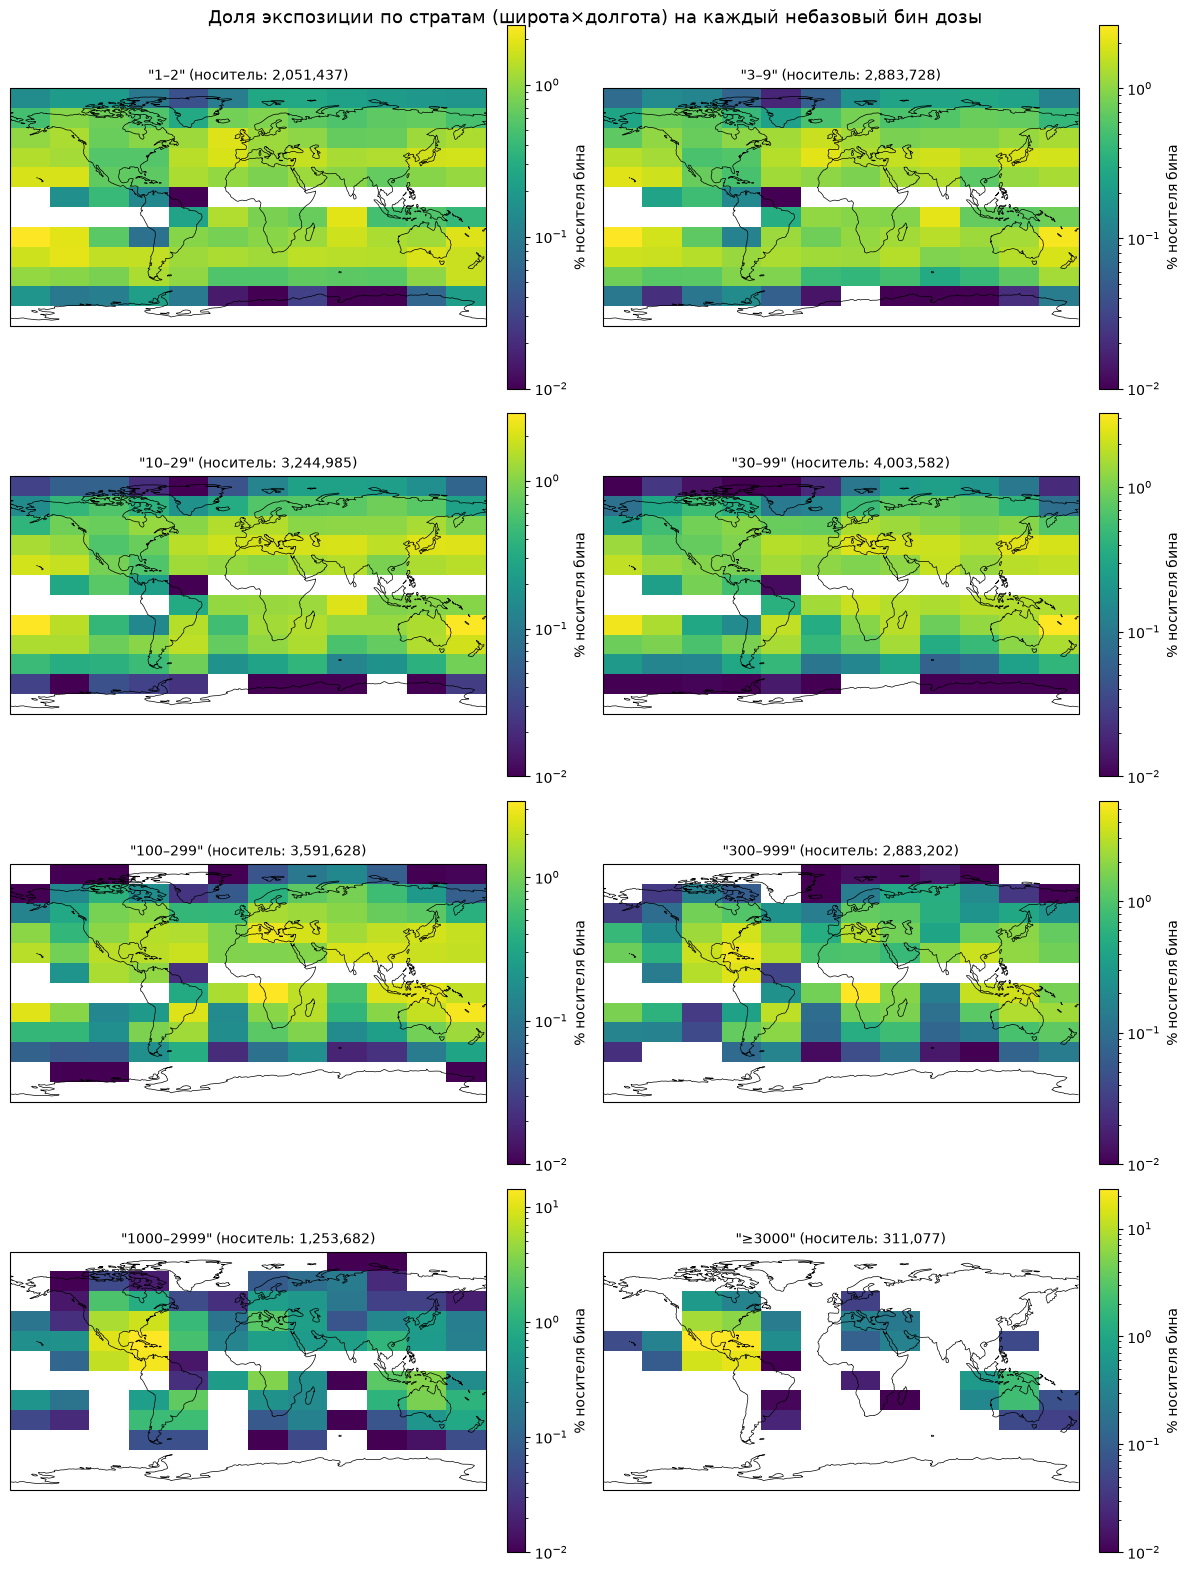

Чем меньше ярких ячеек и чем ближе доля к 100% в одной-двух из них — тем сильнее headline на этом бине держится на конкретном регионе/сезоне, а не на всей планете.

Экспозиция по полосам долготы (все страты/сутки/КА/бины дозы вместе):
     -180…-150: 4,762,426
     -150…-120: 4,779,958
      -120…-90: 4,735,493
       -90…-60: 4,695,811
       -60…-30: 4,499,596
         -30…0: 4,697,337
          0…30: 4,649,900
         30…60: 4,608,953
         60…90: 4,871,438
        90…120: 4,858,688
       120…150: 4,901,970
       150…180: 4,957,145
CPU times: user 602 ms, sys: 23.9 ms, total: 626 ms
Wall time: 639 ms


In [20]:
%%time
import numpy as np
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
from matplotlib.colors import LogNorm

# те же формулы бинов широты/долготы, что в dose_pipeline.py (равномерная сетка
# n_latb×N_LONB, 180°/n_latb по широте, 360°/N_LONB по долготе)
_lat_edges_map = np.linspace(-90.0, 90.0, accum_fp_consistent['n_latb'] + 1)
_lon_edges_map = np.linspace(-180.0, 180.0, N_LONB + 1)

# exp_true_d: (сутки, КА, широта, долгота, сезон, ночь, доза) — сворачиваем всё,
# кроме широты/долготы, для каждого бина дозы отдельно (бин 0 — опорный, пропускаем)
_dose_bins_to_show = list(range(1, len(DOSE_LABELS)))

fig, axes = plt.subplots(4, 2, figsize=(12, 16), subplot_kw={'projection': ccrs.PlateCarree()})
for ax, db in zip(axes.flat, _dose_bins_to_show):
    grid = accum_fp_consistent['exp_true_d'][..., db].sum(axis=(0, 1, 4, 5))
    total = grid.sum()
    share_pct = np.where(grid > 0, grid / total * 100.0, np.nan) if total > 0 else np.full_like(grid, np.nan)
    ax.coastlines(linewidth=0.5, color='black')
    ax.set_global()
    im = ax.pcolormesh(_lon_edges_map, _lat_edges_map, share_pct, transform=ccrs.PlateCarree(),
                       cmap='viridis', norm=LogNorm(vmin=0.01, vmax=np.nanmax(share_pct) if total > 0 else 1))
    ax.set_title(f'"{DOSE_LABELS[db]}" (носитель: {total:,.0f})', fontsize=10)
    plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label='% носителя бина')
fig.suptitle('Доля экспозиции по стратам (широта×долгота) на каждый небазовый бин дозы', fontsize=13)
fig.tight_layout()
plt.show()
plt.close(fig)

print('Чем меньше ярких ячеек и чем ближе доля к 100% в одной-двух из них — тем сильнее '
      'headline на этом бине держится на конкретном регионе/сезоне, а не на всей планете.')

# --- диагностика белых полос: это реальный ноль по ВСЕЙ долготной полосе (на любом
# бине дозы, любой широте) или что-то локальное для отдельных бинов? Суммируем по
# ВООБЩЕ ВСЕМУ (широта, сезон, ночь, КА, сутки, ВСЕ бины дозы включая «0») — если
# полоса пустая и здесь, это структурный пробел в самих footprint-стратах
# (`strata_by_geometry=True` — долгота считается по footprint-точке, не по спутнику),
# а не особенность конкретного бина дозы.
_lon_totals_all = accum_fp_consistent['exp_true_d'].sum(axis=(0, 1, 2, 4, 5, 6))
_lon_labels_map = [f'{_lon_edges_map[j]:.0f}…{_lon_edges_map[j + 1]:.0f}' for j in range(N_LONB)]
print('\nЭкспозиция по полосам долготы (все страты/сутки/КА/бины дозы вместе):')
for lbl, v in zip(_lon_labels_map, _lon_totals_all):
    print(f'  {lbl:>12}: {v:,.0f}')

### Диагностика: footprint на 1°×1° по всему шару (не страты MH)

Только картинка, не накопитель. Страты `N_LATB`×`N_LONB` и MH не трогаем —
молнии и свисты не считаем. Берём подспутниковые ячейки **0.5°×0.5°**
(представительный центр, вес = число сэмплов `df_pred` в ней), гоняем через
`footprint_conjugate_arr` и раскладываем footprint-точки на сетке карты
**1°×1°**, широта **−90…90**. Карта бинарная: заливка там, где есть
хотя бы одно наблюдение, белое — где нет.

Источники намеренно мельче клетки карты: при совпадении сеток отображение
промахивается по отдельным клеткам-приёмникам и появляются ложные белые
крапины (та же причина, по которой дыра ниже считается с шага 0.5°).

Белые клетки — туда AACGM-footprint с 827 км не падает (плюс нет орбитальных
сэмплов). NaN A2G в гистограмму не кладём (без фолбэка на подспутниковую
точку — иначе экватор закрасится ложно).

**Дыра (штриховка)** — не dip±8°. Это множество точек на 100 км, в которые
тот же `footprint_conjugate_arr` не отображает *никакую* подспутниковую
точку с 827 км (плотная сетка 0.5°, одна дата). Это ровно механизм карты,
включая перекос над SAA. Новую библиотеку не подключаем: `apexpy` здесь
нет (Fortran), IGRF-трассировка (`trace_field_line`) на карту слишком
медленная, а `aacgmv2 TRACE` дал бы *другую* дыру, чем коэффициентный
G2A/A2G в пайплайне.

Серая линия — dip-экватор на 100 км (I = 0 по IGRF), только как ориентир,
не как граница дыры.


ячеек-источников 0.5° (с повтором по суткам): 11,250,936
A2G NaN (в гистограмму не шли): 0
носитель (вес = сэмплы df_pred → footprint): 57,018,715
пустых 1° клеток: 17599 / 64800
теоретическая дыра (1° клетки, |lat|<40): 12016 / 28800; A2G NaN на плотной сетке: 0
страт без носителя (структурный ноль): 12
разбираемая страта (EDGE_ANCHOR=(8.0, -45.0)): широта 0…15, долгота -60…-30; носитель по всем бинам = 3,428, доля площади в дыре = 1.00


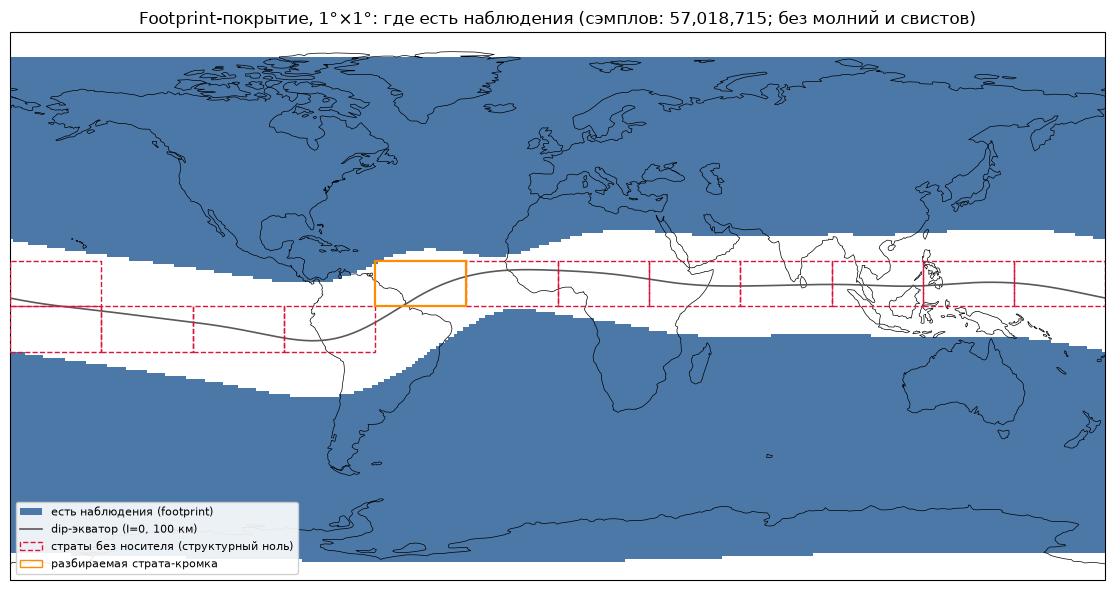


Долготы −76…−28, широты −20…20: покрыто 389 / 1,920 клеток 1°×1° (20.3%)
CPU times: user 58 s, sys: 3.73 s, total: 1min 1s
Wall time: 1min 3s


In [23]:
%%time
import numpy as np
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch, Rectangle
import ppigrf

# диагностическая сетка 1°×1° на весь шар. Не путать с N_LATB/N_LONB
# (страты MH) и не с GLAT×GLON=2° (ячейки накопителя): здесь нужна та же
# независима от GLAT×GLON накопителя и от сетки источников ниже.
EQ_LAT_LO, EQ_LAT_HI = -90.0, 90.0
EQ_DLAT, EQ_DLON = 1.0, 1.0
_eq_lat_edges = np.arange(EQ_LAT_LO, EQ_LAT_HI + 0.5 * EQ_DLAT, EQ_DLAT)
_eq_lon_edges = np.arange(-180.0, 180.0 + 0.5 * EQ_DLON, EQ_DLON)
n_eq_lat, n_eq_lon = len(_eq_lat_edges) - 1, len(_eq_lon_edges) - 1
eq_grid = np.zeros((n_eq_lat, n_eq_lon), dtype=np.float64)
n_cells_used = 0
n_fp_nan = 0

# источники footprint всегда мельче клетки карты (0.5°, независимо от EQ_DLAT): если
# сетки совпадают, отображение промахивается по отдельным клеткам-приёмникам и карта
# покрывается ложными белыми крапинами. Проверено на 116 сутках: с источниками 4° - 31
# пустая клетка вне дыры и вне предела орбиты, с 0.5° - ни одной.
SRC_DEG = 0.5
glat, glon = SRC_DEG, SRC_DEG
nlat = int(round(180.0 / glat))
nlon = int(round(360.0 / glon))
lat_edges_2 = np.linspace(-90.0, 90.0, nlat + 1)
lon_edges_2 = np.linspace(-180.0, 180.0, nlon + 1)
lat_c_2 = 0.5 * (lat_edges_2[:-1] + lat_edges_2[1:])
lon_c_2 = 0.5 * (lon_edges_2[:-1] + lon_edges_2[1:])

_plat = df_pred['geo_lat'].values.astype(np.float64)
_plon = df_pred['geo_lon'].values.astype(np.float64)
_pday = df_pred['timestamp'].values.astype('datetime64[D]').astype(np.int64)

for day in acc_days:
    sl = np.flatnonzero(_pday == day)
    if sl.size == 0:
        continue
    ii = np.clip(((_plat[sl] + 90.0) / glat).astype(np.int64), 0, nlat - 1)
    jj = np.clip(((_plon[sl] + 180.0) / glon).astype(np.int64), 0, nlon - 1)
    flat = ii * nlon + jj
    cells, counts = np.unique(flat, return_counts=True)
    lat_cc = lat_c_2[cells // nlon]
    lon_cc = lon_c_2[cells % nlon]
    day_date = np.datetime64(day, 'D').astype('datetime64[s]').astype(object)
    fp_lat, fp_lon, _, _ = mag_coords.footprint_conjugate_arr(
        lat_cc, lon_cc, SAT_HEIGHT_KM, day_date)
    n_cells_used += cells.size
    valid = np.isfinite(fp_lat) & np.isfinite(fp_lon)
    n_fp_nan += int((~valid).sum())
    fp_lat, fp_lon, w = fp_lat[valid], fp_lon[valid], counts[valid].astype(np.float64)
    fp_lon = np.mod(fp_lon + 180.0, 360.0) - 180.0
    li = np.clip(((fp_lat - EQ_LAT_LO) / EQ_DLAT).astype(np.int64), 0, n_eq_lat - 1)
    lj = np.clip(((fp_lon + 180.0) / EQ_DLON).astype(np.int64), 0, n_eq_lon - 1)
    np.add.at(eq_grid, (li, lj), w)

total_eq = eq_grid.sum()
# карте нужен только факт "есть наблюдения", а не их доля: "% носителя" - это доля времени
# наблюдений (орбитальный эффект: разворот витка на |шир.|~81 плюс мелкие клетки у полюса),
# а не свойство footprint-геометрии, ради которой карта и рисуется
covered_eq = eq_grid > 0
print(f'ячеек-источников {SRC_DEG}° (с повтором по суткам): {n_cells_used:,}')
print(f'A2G NaN (в гистограмму не шли): {n_fp_nan:,}')
print(f'носитель (вес = сэмплы df_pred → footprint): {total_eq:,.0f}')
print(f'пустых 1° клеток: {int(np.sum(eq_grid == 0))} / {eq_grid.size}')

_date_mid = np.datetime64(int(acc_days[len(acc_days) // 2]), 'D').astype('datetime64[s]').astype(object)

# --- теоретическая дыра: все точки на 827 км (сетка 1°) → footprint на 100 км ---
# не dip±N и не орбита: куда AACGM в принципе не умеет попасть с высоты спутника
# шаг 0.5°, не 1°: на 1° отображение промахивается по отдельным клеткам-приёмникам
# и дыра распадается на ~90 ложных одиночных клеток (крапинки на контуре)
_sat_lat = np.arange(-80.0, 80.01, 0.5)
_sat_lon = np.arange(-180.0, 179.51, 0.5)
_sg_lat, _sg_lon = np.meshgrid(_sat_lat, _sat_lon, indexing='ij')
_th_lat, _th_lon, _, _ = mag_coords.footprint_conjugate_arr(
    _sg_lat.ravel(), _sg_lon.ravel(), SAT_HEIGHT_KM, _date_mid)
_th_ok = np.isfinite(_th_lat) & np.isfinite(_th_lon)
_th_lat, _th_lon = _th_lat[_th_ok], np.mod(_th_lon[_th_ok] + 180.0, 360.0) - 180.0
_hole_lat_e = np.arange(-40.0, 40.01, 1.0)
_hole_lon_e = np.arange(-180.0, 180.01, 1.0)
_reach, _, _ = np.histogram2d(_th_lat, _th_lon, bins=[_hole_lat_e, _hole_lon_e])
_hole = _reach == 0
_hole_lat_c = 0.5 * (_hole_lat_e[:-1] + _hole_lat_e[1:])
_hole_lon_c = 0.5 * (_hole_lon_e[:-1] + _hole_lon_e[1:])
print(f'теоретическая дыра (1° клетки, |lat|<40): {_hole.sum()} / {_hole.size}; '
      f'A2G NaN на плотной сетке: {int((~_th_ok).sum()):,}')

# dip-экватор на 100 км — ориентир, не граница дыры
_dip_lon = np.linspace(-180.0, 180.0, 361)
_glats = np.linspace(-25.0, 25.0, 201)
_dip_lat = np.empty_like(_dip_lon)
for k, lon in enumerate(_dip_lon):
    Be, Bn, Bu = ppigrf.igrf(float(lon), _glats, 100.0, _date_mid)
    I = np.degrees(np.arctan2(-np.squeeze(Bu), np.hypot(np.squeeze(Be), np.squeeze(Bn))))
    z = np.where(np.diff(np.sign(I)))[0]
    if len(z) == 0:
        _dip_lat[k] = np.nan
        continue
    i = z[np.argmin(np.abs(_glats[z]))]
    _dip_lat[k] = _glats[i] - I[i] * (_glats[i + 1] - _glats[i]) / (I[i + 1] - I[i])

# --- рамки грубых страт на этой же 1° сетке ---
# Координаты не хардкодим: сетка страт берётся из накопителя (n_latb/n_axis4).
#   малиновый пунктир — носитель = 0 по ВСЕМ бинам дозы: структурный ноль footprint
#                       (страты, пустые лишь на отдельном бине, — например полярные,
#                       где нет умеренных гроз, — не помечаем: дыра тут не при чём);
#   оранжевый         — ОДНА разбираемая страта-кромка, заданная точкой EDGE_ANCHOR
#                       (широта, долгота) где-нибудь внутри неё. Границы подставит
#                       сама сетка страт, поэтому при смене N_LATB/N_LONB рамка
#                       остаётся на том же месте карты.
EDGE_ANCHOR = (8.0, -45.0)
_boxes_struct, _boxes_edge, _edge_cells = [], [], []
if 'accum_fp_consistent' in globals() and accum_fp_consistent is not None:
    _c_all = accum_fp_consistent['exp_true_d'].sum(axis=(0, 1, 4, 5, 6))
    _le = np.linspace(-90.0, 90.0, accum_fp_consistent['n_latb'] + 1)
    _lo = np.linspace(-180.0, 180.0, accum_fp_consistent['n_axis4'] + 1)


    def _hole_frac(i, j):
        m = ((_hole_lat_c[:, None] >= _le[i]) & (_hole_lat_c[:, None] < _le[i + 1])
             & (_hole_lon_c[None, :] >= _lo[j]) & (_hole_lon_c[None, :] < _lo[j + 1]))
        return float(_hole[m].mean()) if m.any() else 0.0


    for _i in range(_c_all.shape[0]):
        for _j in range(_c_all.shape[1]):
            if _c_all[_i, _j] == 0:
                _boxes_struct.append((_lo[_j], _le[_i], _lo[_j + 1] - _lo[_j],
                                      _le[_i + 1] - _le[_i]))
    _ai = int(np.clip(np.searchsorted(_le, EDGE_ANCHOR[0], side='right') - 1,
                      0, _c_all.shape[0] - 1))
    _aj = int(np.clip(np.searchsorted(_lo, EDGE_ANCHOR[1], side='right') - 1,
                      0, _c_all.shape[1] - 1))
    _edge_cells = [(_ai, _aj)]
    _boxes_edge = [(_lo[_aj], _le[_ai], _lo[_aj + 1] - _lo[_aj], _le[_ai + 1] - _le[_ai])]
    print(f'страт без носителя (структурный ноль): {len(_boxes_struct)}')
    print(f'разбираемая страта (EDGE_ANCHOR={EDGE_ANCHOR}): '
          f'широта {_le[_ai]:.0f}…{_le[_ai + 1]:.0f}, долгота {_lo[_aj]:.0f}…{_lo[_aj + 1]:.0f}; '
          f'носитель по всем бинам = {_c_all[_ai, _aj]:,.0f}, '
          f'доля площади в дыре = {_hole_frac(_ai, _aj):.2f}')
else:
    print('accum_fp_consistent не посчитан — рамки страт не рисуем')

COVER_COLOR = '#4c78a8'
fig, ax = plt.subplots(figsize=(12, 6), subplot_kw={'projection': ccrs.PlateCarree()})
ax.coastlines(linewidth=0.5, color='black')
ax.set_global()
# NaN там, где наблюдений нет - остаётся белым фоном карты, без отдельного цвета
_fill = np.where(covered_eq, 1.0, np.nan)
ax.pcolormesh(_eq_lon_edges, _eq_lat_edges, _fill, transform=ccrs.PlateCarree(),
              cmap=ListedColormap([COVER_COLOR]), vmin=0.0, vmax=1.0, shading='flat')
pc = dict(transform=ccrs.PlateCarree(), zorder=5)
ax.plot(_dip_lon, _dip_lat, color='0.35', lw=1.2, label='dip-экватор (I=0, 100 км)', **pc)
for _x, _y, _w, _h in _boxes_struct:
    ax.add_patch(Rectangle((_x, _y), _w, _h, fill=False, edgecolor='crimson',
                           lw=1.0, ls='--', zorder=6, transform=ccrs.PlateCarree()))
for _x, _y, _w, _h in _boxes_edge:
    ax.add_patch(Rectangle((_x, _y), _w, _h, fill=False, edgecolor='darkorange',
                           lw=1.6, zorder=7, transform=ccrs.PlateCarree()))
_handles = [
    Patch(facecolor=COVER_COLOR, edgecolor='none', label='есть наблюдения (footprint)'),
    plt.Line2D([0], [0], color='0.35', lw=1.2, label='dip-экватор (I=0, 100 км)'),
]
if _boxes_struct:
    _handles.append(Patch(facecolor='none', edgecolor='crimson', ls='--',
                          label='страты без носителя (структурный ноль)'))
if _boxes_edge:
    _handles.append(Patch(facecolor='none', edgecolor='darkorange',
                          label='разбираемая страта-кромка'))
ax.legend(handles=_handles, loc='lower left', fontsize=8, framealpha=0.9)
ax.set_title(f'Footprint-покрытие, 1°×1°: где есть наблюдения '
             f'(сэмплов: {total_eq:,.0f}; без молний и свистов)', fontsize=12)
fig.tight_layout()
plt.show()
plt.close(fig)

_sa = (_eq_lon_edges[:-1] >= -76.0) & (_eq_lon_edges[:-1] < -28.0)
_eq_rows = (_eq_lat_edges[:-1] >= -20.0) & (_eq_lat_edges[:-1] < 20.0)
# таблицу 1°×1° по сектору не печатаем целиком — только сводка
_n_cov = int(np.sum(covered_eq[_eq_rows][:, _sa]))
_n_all = int(np.sum(_eq_rows) * np.sum(_sa))
print(f'\nДолготы −76…−28, широты −20…20: покрыто {_n_cov:,} / {_n_all:,} '
      f'клеток 1°×1° ({100.0 * _n_cov / _n_all:.1f}%)')


### Кромка дыры vs белые страты

Белые клетки на 1° карте — структурный ноль: AACGM-footprint с 827 км туда не отображается. Сравнивать носитель кромки с нулём этих клеток как с пуассоновской выборкой нельзя: при λ = 0 любое n > 0 даёт p = 0.

Проверка режет те же грубые страты на клетки 1° (`eq_grid`) и на теоретическую дыру (`_hole`). Кромка — грубая страта, в которую попадает точка `EDGE_ANCHOR = (8°, −45°)` с 1° карты выше. На сохранённом прогоне это широта 0…15°, долгота −60…−30°.

Внутри дыры кромка пустая так же, как белые страты (449/449 клеток). Цвет грубой клетки дают 564 сэмпла снаружи дыры: в клетку входит достижимый край щели.


,роль,широта,долгота,носитель «3–9»,доля площади в дыре,1° в дыре,из них >0,сэмплы в дыре,сэмплы вне дыры,медиана вне дыры (>0),"сэмплов в дыре, %"
0,кромка,0…15,-60…-30,222,1.0,449,0,0,564,564.0,0.0
1,белая (структурный ноль),-15…0,-180…-150,0,1.0,450,0,0,0,NaN,NaN
2,белая (структурный ноль),-15…0,-150…-120,0,1.0,450,0,0,0,NaN,NaN
3,белая (структурный ноль),-15…0,-120…-90,0,1.0,450,0,0,0,NaN,NaN
4,белая (структурный ноль),-15…0,-90…-60,0,1.0,450,0,0,0,NaN,NaN
5,белая (структурный ноль),0…15,-180…-150,0,1.0,450,0,0,0,NaN,NaN
6,белая (структурный ноль),0…15,-30…0,0,1.0,450,0,0,0,NaN,NaN
7,белая (структурный ноль),0…15,0…30,0,1.0,450,0,0,0,NaN,NaN
8,белая (структурный ноль),0…15,30…60,0,1.0,450,0,0,0,NaN,NaN
9,белая (структурный ноль),0…15,60…90,0,1.0,450,0,0,0,NaN,NaN


Пуассон-тест носителя кромки против λ=0 белых страт бессмысленен: при λ=0 любое n>0 даёт p=0. Сравниваем доли ПУСТЫХ 1° клеток внутри дыры.

Белые страты (объединённо): пустых 1° в дыре 5400/5400 = 1.000
  кромка 0…15 / -60…-30: пустых в дыре 449/449 = 1.000, точный биномиальный p (H0: как белые) = nan; вне дыры 564 сэмплов

Внутри дыры кромка не отличается от белых страт. Сумма по всей грубой клетке отличается только потому, что в клетку входит достижимый край щели.


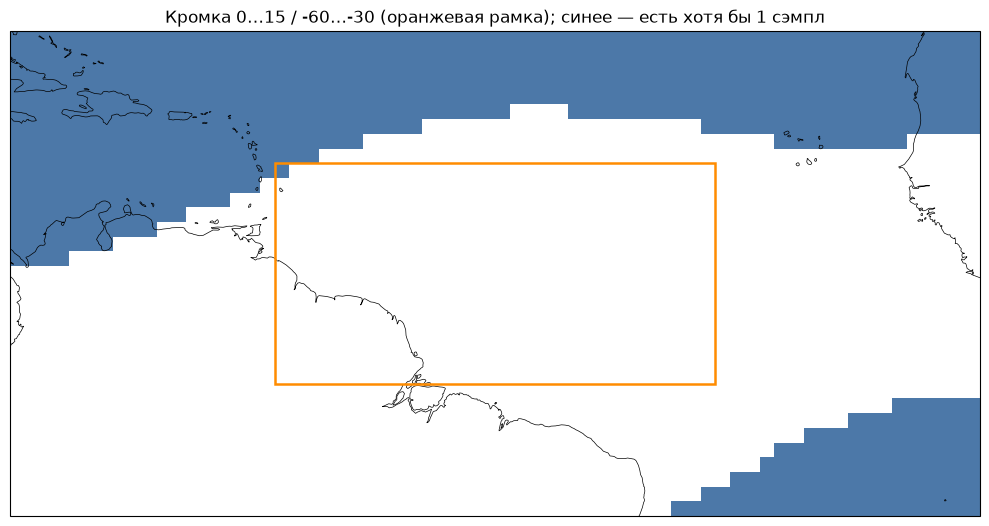

CPU times: user 86.8 ms, sys: 27.4 ms, total: 114 ms
Wall time: 118 ms


In [25]:
%%time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
from matplotlib.patches import Rectangle
from matplotlib.colors import ListedColormap
from math import lgamma

needed = ('eq_grid', '_eq_lat_edges', '_eq_lon_edges', '_hole', '_hole_lat_e', '_hole_lon_e',
          '_hole_lat_c', '_hole_lon_c', 'accum_fp_consistent', 'DOSE_LABELS', '_edge_cells')
missing = [n for n in needed if n not in globals()]
if missing:
    raise RuntimeError('Сначала ячейки загрузки, accum_fp_consistent и 1°-карту (дыра). Нет: '
                       + ', '.join(missing))

# сетка страт и их роли — из накопителя; кромка — та же, что оранжевая рамка 1°-карты
_c_all = accum_fp_consistent['exp_true_d'].sum(axis=(0, 1, 4, 5, 6))
_db = DOSE_LABELS.index('3–9')
_c_bin = accum_fp_consistent['exp_true_d'][..., _db].sum(axis=(0, 1, 4, 5))
_le = np.linspace(-90.0, 90.0, accum_fp_consistent['n_latb'] + 1)
_lo = np.linspace(-180.0, 180.0, accum_fp_consistent['n_axis4'] + 1)


def _hole_frac(i, j):
    m = ((_hole_lat_c[:, None] >= _le[i]) & (_hole_lat_c[:, None] < _le[i + 1])
         & (_hole_lon_c[None, :] >= _lo[j]) & (_hole_lon_c[None, :] < _lo[j + 1]))
    return (float(_hole[m].mean()) if m.any() else 0.0)


frac = np.array([[_hole_frac(i, j) for j in range(_c_all.shape[1])]
                 for i in range(_c_all.shape[0])])
# разбираемая страта — та же, что оранжевая рамка на 1°-карте (EDGE_ANCHOR)
edge = list(_edge_cells)
white = [(i, j) for i in range(_c_all.shape[0]) for j in range(_c_all.shape[1])
         if _c_all[i, j] == 0 and frac[i, j] > 0]
if not edge:
    raise RuntimeError('_edge_cells пуст — сначала 1°-карта, там задаётся EDGE_ANCHOR')
# контроль: та же долгота, ближайшая широтная страта полностью вне дыры и с носителем
ctrl = []
for i, j in edge:
    cand = [(k, j) for k in range(_c_all.shape[0])
            if frac[k, j] == 0 and _c_all[k, j] > 0]
    if cand:
        ctrl.append(min(cand, key=lambda kj: abs(kj[0] - i)))
ctrl = sorted(set(ctrl))

# дыра 1° (−40…40) → маска на eq_grid (−90…90)
hole_on_eq = np.zeros(eq_grid.shape, dtype=bool)
i0 = int(np.round(_hole_lat_e[0] - _eq_lat_edges[0]))
j0 = int(np.round(_hole_lon_e[0] - _eq_lon_edges[0]))
hole_on_eq[i0:i0 + _hole.shape[0], j0:j0 + _hole.shape[1]] = _hole
_eq_lat_c = 0.5 * (_eq_lat_edges[:-1] + _eq_lat_edges[1:])
_eq_lon_c = 0.5 * (_eq_lon_edges[:-1] + _eq_lon_edges[1:])


def summarize(i, j, role):
    m = ((_eq_lat_c[:, None] >= _le[i]) & (_eq_lat_c[:, None] < _le[i + 1])
         & (_eq_lon_c[None, :] >= _lo[j]) & (_eq_lon_c[None, :] < _lo[j + 1]))
    w_in, w_out = eq_grid[m & hole_on_eq], eq_grid[m & ~hole_on_eq]
    tot = w_in.sum() + w_out.sum()
    return {
        'роль': role,
        'широта': f'{_le[i]:.0f}…{_le[i + 1]:.0f}',
        'долгота': f'{_lo[j]:.0f}…{_lo[j + 1]:.0f}',
        'носитель «3–9»': int(_c_bin[i, j]),
        'доля площади в дыре': round(frac[i, j], 2),
        '1° в дыре': int((m & hole_on_eq).sum()),
        'из них >0': int((w_in > 0).sum()),
        'сэмплы в дыре': int(w_in.sum()),
        'сэмплы вне дыры': int(w_out.sum()),
        'медиана вне дыры (>0)': (float(np.median(w_out[w_out > 0])) if np.any(w_out > 0) else np.nan),
        'сэмплов в дыре, %': (round(100.0 * w_in.sum() / tot, 2) if tot > 0 else np.nan),
    }


rows = ([summarize(i, j, 'кромка') for i, j in edge]
        + [summarize(i, j, 'белая (структурный ноль)') for i, j in white]
        + [summarize(i, j, 'контроль (вне дыры)') for i, j in ctrl])
display(pd.DataFrame(rows))

print('Пуассон-тест носителя кромки против λ=0 белых страт бессмысленен: '
      'при λ=0 любое n>0 даёт p=0. Сравниваем доли ПУСТЫХ 1° клеток внутри дыры.\n')


def binom_test_two_sided(k, n, p):
    """Точный двусторонний биномиальный p при H0: доля пустых = p (белые страты)."""
    if n == 0 or not (0 < p < 1):
        return np.nan

    def logpmf(x):
        return (lgamma(n + 1) - lgamma(x + 1) - lgamma(n - x + 1)
                + x * np.log(p) + (n - x) * np.log(1 - p))

    obs = logpmf(k)
    return float(min(1.0, sum(np.exp(logpmf(x)) for x in range(n + 1)
                              if logpmf(x) <= obs + 1e-12)))


w_rows = [r for r in rows if r['роль'].startswith('белая')]
n_w = sum(r['1° в дыре'] for r in w_rows)
k_w = n_w - sum(r['из них >0'] for r in w_rows)
p_w = k_w / n_w if n_w else np.nan
print(f'Белые страты (объединённо): пустых 1° в дыре {k_w}/{n_w} = {p_w:.3f}')
for r in rows:
    if r['роль'] != 'кромка':
        continue
    n_h, k_h = r['1° в дыре'], r['1° в дыре'] - r['из них >0']
    pv = binom_test_two_sided(k_h, n_h, p_w)
    print(f"  кромка {r['широта']} / {r['долгота']}: пустых в дыре {k_h}/{n_h} = "
          f"{(k_h / n_h if n_h else np.nan):.3f}, точный биномиальный p (H0: как белые) = {pv:.3f}; "
          f"вне дыры {r['сэмплы вне дыры']:,} сэмплов")
print('\nВнутри дыры кромка не отличается от белых страт. Сумма по всей грубой клетке '
      'отличается только потому, что в клетку входит достижимый край щели.')

# зум на кромку с наименьшим носителем — самый показательный случай
_i, _j = min(edge, key=lambda ij: _c_all[ij])
fig, ax = plt.subplots(figsize=(10, 5.5), subplot_kw={'projection': ccrs.PlateCarree()})
_pad_lat, _pad_lon = 0.6 * (_le[1] - _le[0]), 0.6 * (_lo[1] - _lo[0])
ax.set_extent([_lo[_j] - _pad_lon, _lo[_j + 1] + _pad_lon,
               max(-90.0, _le[_i] - _pad_lat), min(90.0, _le[_i + 1] + _pad_lat)],
              crs=ccrs.PlateCarree())
ax.coastlines(linewidth=0.5)
COVER_COLOR = '#4c78a8'
_fill = np.where(eq_grid > 0, 1.0, np.nan)
ax.pcolormesh(_eq_lon_edges, _eq_lat_edges, _fill, transform=ccrs.PlateCarree(),
              cmap=ListedColormap([COVER_COLOR]), vmin=0.0, vmax=1.0, shading='flat')
pc = dict(transform=ccrs.PlateCarree())
ax.add_patch(Rectangle((_lo[_j], _le[_i]), _lo[_j + 1] - _lo[_j], _le[_i + 1] - _le[_i],
                       fill=False, edgecolor='darkorange', linewidth=1.8, zorder=7, **pc))
ax.set_title(f'Кромка {_le[_i]:.0f}…{_le[_i + 1]:.0f} / {_lo[_j]:.0f}…{_lo[_j + 1]:.0f} '
             f'(оранжевая рамка); синее — есть хотя бы 1 сэмпл')
fig.tight_layout()
plt.show()
plt.close(fig)


### Поимённый список страт, входящих в точку «≥3000»

Дополнение к карте выше: не доля носителя по клетке карты (сезон/ночь
свёрнуты), а полный список конкретных страт (широта×долгота×сезон×ночь),
которые проходят общий носитель (`e0>=MIN_STRAT_EXP` И `e1>=MIN_STRAT_EXP`)
для пары «доза=0» / «≥3000», с их MH-весом $w_i = e_0 e_1/(e_0+e_1)$ — той же
формулой, что внутри `mh()` (`dose_pipeline.py`), просто без свёртки в одно
число. Отсортировано по весу — видно буквально, какие (широта, долгота,
сезон, ночь/день) дают точку на графике «уровень свистов vs доза» и сколько
именно каждая из них весит.

Пересчёта не требует — то же `accum_fp_consistent`, что и везде выше.

In [24]:
%%time
import numpy as np
import pandas as pd


def strata_contributions(accum, sc_i, k, ref=0, min_exp=500):
    """Список страт, проходящих общий носитель для пары (ref, k), с MH-весом
    w_i = e0*e1/(e0+e1) — та же формула, что внутри mh(), без свёртки в одно число."""
    n_latb, n_lonb = accum['n_latb'], accum['n_axis4']
    w_lat, w_lon = 180.0 / n_latb, 360.0 / n_lonb
    lat_labels = [f'{-90 + w_lat * i:.0f}…{-90 + w_lat * (i + 1):.0f}' for i in range(n_latb)]
    lon_labels = [f'{-180 + w_lon * j:.0f}…{-180 + w_lon * (j + 1):.0f}' for j in range(n_lonb)]
    sea_labels = list(wc.SEASON_ORDER)
    night_labels = ['день', 'ночь']

    Et = accum['exp_true_d'][:, sc_i].sum(axis=0)  # (широта, долгота, сезон, ночь, доза)
    Pt = accum['pos_true_d'][:, sc_i].sum(axis=0)
    e0_g, e1_g = Et[..., ref], Et[..., k]
    p0_g, p1_g = Pt[..., ref], Pt[..., k]

    rows = []
    for li in range(n_latb):
        for lj in range(n_lonb):
            for sea_i in range(len(sea_labels)):
                for ni in range(2):
                    e0 = float(e0_g[li, lj, sea_i, ni])
                    e1 = float(e1_g[li, lj, sea_i, ni])
                    if e0 < min_exp or e1 < min_exp:
                        continue
                    p0 = float(p0_g[li, lj, sea_i, ni])
                    p1 = float(p1_g[li, lj, sea_i, ni])
                    rows.append({
                        'широта': lat_labels[li], 'долгота': lon_labels[lj],
                        'сезон': sea_labels[sea_i], 'ночь/день': night_labels[ni],
                        'e0 (доза=0)': int(e0), 'e1 (бин)': int(e1),
                        'P0': p0 / e0, 'P1': p1 / e1,
                        'вес w_i': e0 * e1 / (e0 + e1),
                    })
    t = pd.DataFrame(rows).sort_values('вес w_i', ascending=False).reset_index(drop=True)
    if len(t):
        t['доля веса, %'] = t['вес w_i'] / t['вес w_i'].sum() * 100
        t['накопл. доля, %'] = t['доля веса, %'].cumsum()
    return t


BIN_TO_INSPECT = len(DOSE_LABELS) - 1  # «≥3000»
for si, sc in enumerate(DOSE_SC):
    t = strata_contributions(accum_fp_consistent, si, BIN_TO_INSPECT, ref=REF_BIN, min_exp=MIN_STRAT_EXP)
    print(f'=== {sc}: страты, входящие в бин "{DOSE_LABELS[BIN_TO_INSPECT]}" ({len(t)} страт) ===')
    if len(t):
        display(t.round(3).head(15))
        top3 = t['доля веса, %'].iloc[:3].sum()
        print(f'Топ-3 страты дают {top3:.1f}% суммарного веса точки на графике.\n')
    else:
        print('Нет ни одной страты с общим носителем на этом бине.\n')

=== ka1: страты, входящие в бин "≥3000" (25 страт) ===


,широта,долгота,сезон,ночь/день,e0 (доза=0),e1 (бин),P0,P1,вес w_i,"доля веса, %","накопл. доля, %"
0,18…36,-108…-72,весна,день,7428,7487,0.065,0.456,3728.692,11.664,11.664
1,18…36,-108…-72,весна,ночь,5862,8319,0.396,0.523,3438.825,10.757,22.421
2,36…54,-108…-72,весна,ночь,11867,4522,0.145,0.484,3274.304,10.242,32.663
3,36…54,-108…-72,весна,день,15166,2256,0.021,0.328,1963.867,6.143,38.807
4,18…36,-108…-72,осень,ночь,2270,12491,0.148,0.458,1920.911,6.009,44.816
5,18…36,-108…-72,осень,день,2830,4095,0.031,0.509,1673.480,5.235,50.050
6,18…36,-108…-72,зима,день,11534,1624,0.048,0.365,1423.561,4.453,54.504
7,0…18,-108…-72,весна,ночь,1927,5233,0.226,0.350,1408.379,4.406,58.909
8,0…18,-108…-72,весна,день,1951,3472,0.020,0.336,1249.100,3.907,62.816
9,18…36,-72…-36,осень,ночь,2871,2005,0.157,0.519,1180.549,3.693,66.509


Топ-3 страты дают 32.7% суммарного веса точки на графике.

=== ka2: страты, входящие в бин "≥3000" (25 страт) ===


,широта,долгота,сезон,ночь/день,e0 (доза=0),e1 (бин),P0,P1,вес w_i,"доля веса, %","накопл. доля, %"
0,18…36,-108…-72,весна,день,7464,7827,0.067,0.399,3820.596,11.966,11.966
1,18…36,-108…-72,весна,ночь,4555,8334,0.380,0.469,2945.253,9.225,21.191
2,36…54,-108…-72,весна,ночь,9787,3759,0.158,0.455,2715.882,8.506,29.697
3,18…36,-108…-72,осень,ночь,2648,11102,0.111,0.453,2138.043,6.696,36.394
4,36…54,-108…-72,весна,день,15487,2369,0.025,0.316,2054.699,6.435,42.829
5,18…36,-108…-72,осень,день,3096,4896,0.031,0.545,1896.649,5.940,48.770
6,18…36,-108…-72,зима,день,16131,1848,0.063,0.337,1658.050,5.193,53.963
7,0…18,-108…-72,весна,ночь,1855,7418,0.165,0.348,1483.920,4.648,58.610
8,-36…-18,108…144,лето,ночь,2251,3044,0.325,0.812,1294.059,4.053,62.663
9,0…18,-108…-72,весна,день,2628,2470,0.021,0.418,1273.276,3.988,66.651


Топ-3 страты дают 29.7% суммарного веса точки на графике.

CPU times: user 18.9 ms, sys: 2.9 ms, total: 21.8 ms
Wall time: 22.6 ms


### Ночь vs день — рост относительно доза=0 (не относительно null)

Тот же стиль графика, что и «ночь vs день: реальная/null» в основном
ноутбуке, но здесь null не считается (`NULL_LAGS=()`), поэтому по оси Y —
`rr_t` (реальная доза / доза=0), не `rrr` (сверх null). На `accum_fp_consistent`
(baseline R=1000км/Δt=30мин, footprint-страты), без пересчёта.


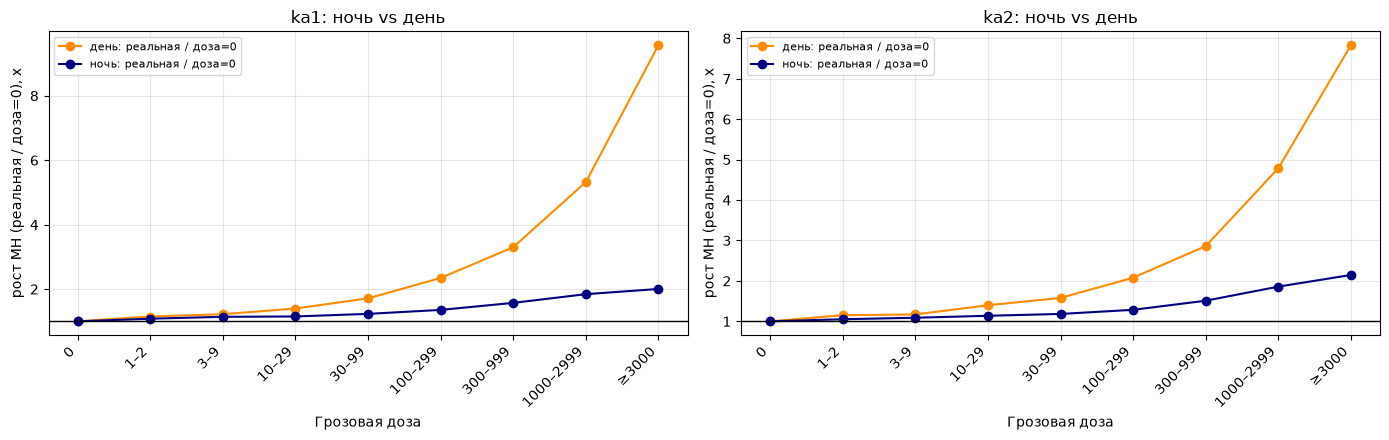

CPU times: user 962 ms, sys: 54.5 ms, total: 1.02 s
Wall time: 1.07 s


In [8]:
%%time
import numpy as np
import matplotlib.pyplot as plt

NIGHT_STYLE = {0: dict(color='darkorange', label='день: реальная / доза=0'),
               1: dict(color='navy', label='ночь: реальная / доза=0')}

SHOW_BIN_3000 = True  # False — не рисовать последний (открытый, ненадёжный) бин «≥3000»
dose_sl = slice(None) if SHOW_BIN_3000 else slice(None, -1)

x = np.arange(len(DOSE_LABELS[dose_sl]))
fig, axes = plt.subplots(1, len(DOSE_SC), figsize=(7 * len(DOSE_SC), 4.5), squeeze=False)
for si, sc in enumerate(DOSE_SC):
    ax = axes[0, si]
    for night_val in (0, 1):
        r = dp.analyze(accum_fp_consistent, sc=si, night=night_val, n_boot=N_BOOT,
                       ref_bin=REF_BIN, min_strat_exp=MIN_STRAT_EXP)
        style = NIGHT_STYLE[night_val]
        ax.plot(x, r['rr_t'][dose_sl], 'o-', color=style['color'], label=style['label'])
    ax.axhline(1.0, color='k', lw=1)
    ax.set_xticks(x)
    ax.set_xticklabels(DOSE_LABELS[dose_sl], rotation=45, ha='right')
    ax.set_xlabel('Грозовая доза')
    ax.set_ylabel('рост MH (реальная / доза=0), x')
    ax.set_title(f'{sc}: ночь vs день')
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)
fig.tight_layout()
plt.show()
plt.close(fig)

### Ночь vs день — абсолютный уровень (не отношение)

Продолжение вопроса выше: `rr_t` на предыдущем графике — MH-отношение к
СВОЕМУ ЖЕ P(доза=0) внутри каждой группы (ночь/день отдельно), поэтому
высоту двух линий друг с другом сравнивать нельзя — у них может быть
разный базовый уровень, и одинаковый/разный рост не говорит ничего об
абсолютном уровне. Здесь тот же `accum_fp_consistent`, но `pk_t` (сам
P(verdict=1) на бине, не отношение) для ночи и дня на одной оси — так
видно, отличается ли действительно абсолютный уровень между режимами.

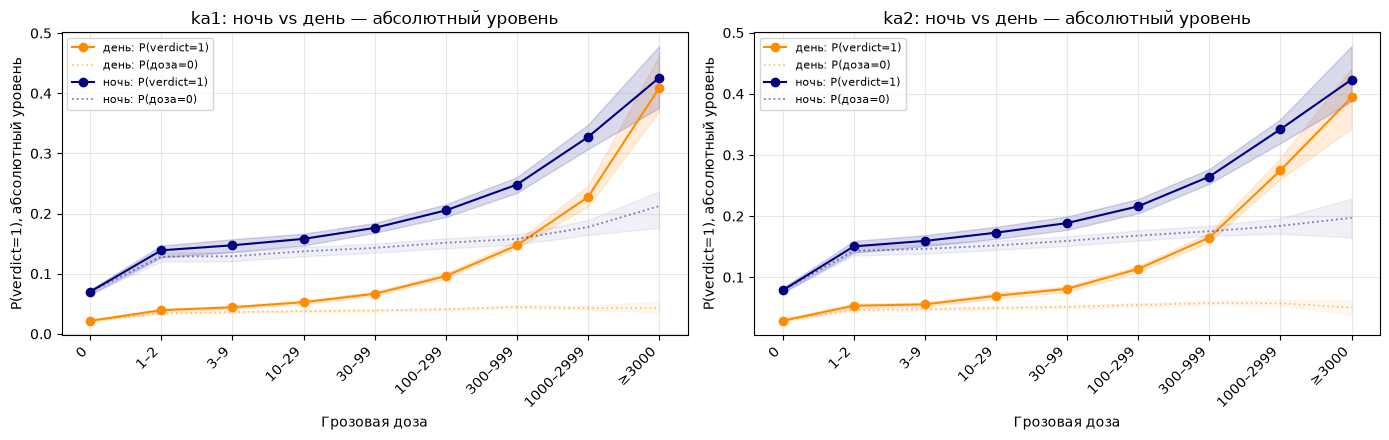

Здесь высоту линий ночь/день сравнивать МОЖНО — обе на одной шкале P(verdict=1), без нормировки на собственный p0. Сплошная линия — P(verdict=1) на бине, пунктир — P(доза=0) для той же группы (может чуть отличаться от левой точки сплошной линии: p0_t на бине k пересчитан по стратам, где есть носитель И на бине 0, И на бине k — MH-условие общего носителя). Если день выше ночи уже на пунктире — это фоновая разница режимов, не эффект дозы; смотреть нужно на разницу в приросте над своим пунктиром (наклон), а не только на абсолютную высоту в правой части графика.
CPU times: user 1.04 s, sys: 58.5 ms, total: 1.1 s
Wall time: 1.19 s


In [9]:
%%time
import numpy as np
import matplotlib.pyplot as plt

NIGHT_STYLE_ABS = {0: dict(color='darkorange', label='день: P(verdict=1)'),
                    1: dict(color='navy', label='ночь: P(verdict=1)')}

SHOW_BIN_3000 = True  # False — не рисовать последний (открытый, ненадёжный) бин «≥3000»
dose_sl = slice(None) if SHOW_BIN_3000 else slice(None, -1)

x = np.arange(len(DOSE_LABELS[dose_sl]))
fig, axes = plt.subplots(1, len(DOSE_SC), figsize=(7 * len(DOSE_SC), 4.5), squeeze=False)
for si, sc in enumerate(DOSE_SC):
    ax = axes[0, si]
    for night_val in (0, 1):
        r = dp.analyze(accum_fp_consistent, sc=si, night=night_val, n_boot=N_BOOT,
                       ref_bin=REF_BIN, min_strat_exp=MIN_STRAT_EXP)
        style = NIGHT_STYLE_ABS[night_val]
        ax.plot(x, r['pk_t'][dose_sl], 'o-', color=style['color'], label=style['label'])
        ax.fill_between(x, r['ci_pk_t'][0, dose_sl], r['ci_pk_t'][1, dose_sl], color=style['color'], alpha=0.15)
        ax.plot(x, r['p0_t'][dose_sl], ':', color=style['color'], alpha=0.5, lw=1.3,
                label=style['label'].replace('P(verdict=1)', 'P(доза=0)'))
        ax.fill_between(x, r['ci_p0_t'][0, dose_sl], r['ci_p0_t'][1, dose_sl], color=style['color'], alpha=0.06)
    ax.set_xticks(x)
    ax.set_xticklabels(DOSE_LABELS[dose_sl], rotation=45, ha='right')
    ax.set_xlabel('Грозовая доза')
    ax.set_ylabel('P(verdict=1), абсолютный уровень')
    ax.set_title(f'{sc}: ночь vs день — абсолютный уровень')
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)
fig.tight_layout()
plt.show()
plt.close(fig)

print('Здесь высоту линий ночь/день сравнивать МОЖНО — обе на одной шкале P(verdict=1), '
      'без нормировки на собственный p0. Сплошная линия — P(verdict=1) на бине, пунктир — '
      'P(доза=0) для той же группы (может чуть отличаться от левой точки сплошной линии: '
      'p0_t на бине k пересчитан по стратам, где есть носитель И на бине 0, И на бине k — '
      'MH-условие общего носителя). Если день выше ночи уже на пунктире — это фоновая '
      'разница режимов, не эффект дозы; смотреть нужно на разницу в приросте над своим '
      'пунктиром (наклон), а не только на абсолютную высоту в правой части графика.')

### То же самое, по сезонам

Четыре линии: зима, весна, лето, осень (`wc.SEASON_ORDER`). Сезон берётся по полушарию точки наблюдения (`wc.season_index`): в южном полушарии зима и лето сдвинуты на полгода относительно северного календаря. Срез сезона делается так, чтобы не сдвинуть ось ночи, на которую опирается `analyze()`.


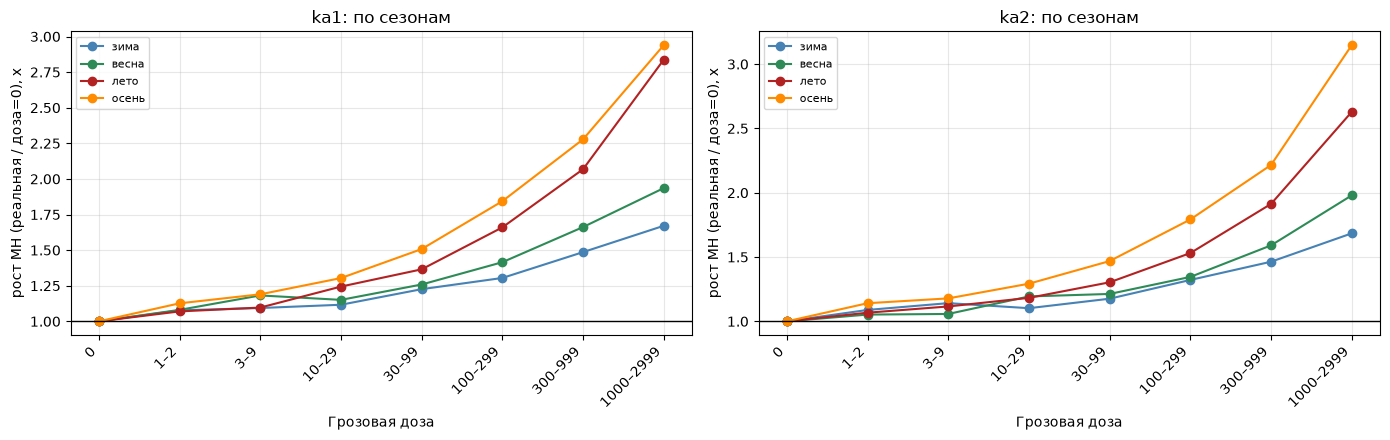

4 сезона делят и так тонкие страты (headline держится на ~24-27) ещё в 4 раза — на крайних бинах кривые отдельных сезонов могут быть шумными/без CI. Смотреть как ориентир, не как точную оценку по каждому сезону отдельно.
CPU times: user 1.32 s, sys: 112 ms, total: 1.43 s
Wall time: 1.55 s


In [17]:
%%time
import numpy as np
import matplotlib.pyplot as plt

SEASON_COLORS = {'зима': 'steelblue', 'весна': 'seagreen', 'лето': 'firebrick', 'осень': 'darkorange'}


def accum_for_season(accum, season_idx):
    """Схлопывает ось сезона до одного значения (срез, не int-индекс — иначе
    съедется позиция оси ночь, на которую опирается select_strata/analyze)."""
    a2 = dict(accum)
    sl = (slice(None), slice(None), slice(None), slice(None), slice(season_idx, season_idx + 1))
    for key in ('exp_true_d', 'pos_true_d', 'prb_true_d', 'exp_null_d', 'pos_null_d', 'prb_null_d'):
        a2[key] = accum[key][sl]
    return a2


SHOW_BIN_3000 = False  # False — не рисовать последний (открытый, ненадёжный) бин «≥3000»
dose_sl = slice(None) if SHOW_BIN_3000 else slice(None, -1)

x = np.arange(len(DOSE_LABELS[dose_sl]))
fig, axes = plt.subplots(1, len(DOSE_SC), figsize=(7 * len(DOSE_SC), 4.5), squeeze=False)
for si, sc in enumerate(DOSE_SC):
    ax = axes[0, si]
    for season_idx, season_name in enumerate(wc.SEASON_ORDER):
        accum_season = accum_for_season(accum_fp_consistent, season_idx)
        r = dp.analyze(accum_season, sc=si, n_boot=N_BOOT, ref_bin=REF_BIN,
                       min_strat_exp=MIN_STRAT_EXP)
        color = SEASON_COLORS[season_name]
        ax.plot(x, r['rr_t'][dose_sl], 'o-', color=color, label=season_name)
    ax.axhline(1.0, color='k', lw=1)
    ax.set_xticks(x)
    ax.set_xticklabels(DOSE_LABELS[dose_sl], rotation=45, ha='right')
    ax.set_xlabel('Грозовая доза')
    ax.set_ylabel('рост MH (реальная / доза=0), x')
    ax.set_title(f'{sc}: по сезонам')
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)
fig.tight_layout()
plt.show()
plt.close(fig)

print('4 сезона делят и так тонкие страты (headline держится на ~24-27) ещё в 4 раза — '
      'на крайних бинах кривые отдельных сезонов могут быть шумными/без CI. Смотреть как '
      'ориентир, не как точную оценку по каждому сезону отдельно.')

### Диагностика: почему «лето» на графике выше меняется местами между ka1/ka2

У ka1 "лето" близко к "осени" (обе высокие), у ka2 "лето" близко к "весне"
(обе ниже) — на бине "1000-2999". Проверка №1: не шум ли это разреженного
хвоста (сезон делит и так тонкий headline-бин ещё в 4 раза).

In [18]:
import numpy as np
import pandas as pd


def accum_for_season(accum, season_idx):
    a2 = dict(accum)
    sl = (slice(None), slice(None), slice(None), slice(None), slice(season_idx, season_idx + 1))
    for key in ('exp_true_d', 'pos_true_d', 'prb_true_d', 'exp_null_d', 'pos_null_d', 'prb_null_d'):
        a2[key] = accum[key][sl]
    return a2


k_check = len(DOSE_LABELS) - 2  # «1000-2999» — последняя точка на графике сезонов (SHOW_BIN_3000=False там)
rows = []
for si, sc in enumerate(DOSE_SC):
    for season_idx, season_name in enumerate(wc.SEASON_ORDER):
        accum_season = accum_for_season(accum_fp_consistent, season_idx)
        r = dp.analyze(accum_season, sc=si, n_boot=N_BOOT, ref_bin=REF_BIN, min_strat_exp=MIN_STRAT_EXP)
        rows.append({
            'КА': sc, 'сезон': season_name, 'бин': DOSE_LABELS[k_check],
            'рост MH': round(r['rr_t'][k_check], 3) if np.isfinite(r['rr_t'][k_check]) else np.nan,
            'CI': (f"{r['ci_t'][0, k_check]:.2f}–{r['ci_t'][1, k_check]:.2f}"
                  if np.isfinite(r['ci_t'][0, k_check]) else '—'),
            'страт': int(r['nst'][k_check]), 'носитель бина': int(r['expo'][k_check]),
        })
season_support = pd.DataFrame(rows)
display(season_support)
print('Если у "лето" CI широкие и пересекаются между ka1/ka2 (и вообще с соседними '
      'сезонами) — скорее всего шум на малом носителе, а не системная разница. Если '
      'CI узкие и не пересекаются — идём дальше проверять регион/дни покрытия.')

,КА,сезон,бин,рост MH,CI,страт,носитель бина
0,ka1,зима,1000–2999,1.671,1.45–2.18,40,40385
1,ka1,весна,1000–2999,1.936,1.78–2.07,44,102893
2,ka1,лето,1000–2999,2.837,2.49–3.17,53,102103
3,ka1,осень,1000–2999,2.939,2.66–3.32,57,131673
4,ka2,зима,1000–2999,1.684,1.43–2.14,39,42996
5,ka2,весна,1000–2999,1.980,1.80–2.21,50,104506
6,ka2,лето,1000–2999,2.629,2.33–2.88,47,112143
7,ka2,осень,1000–2999,3.148,2.83–3.52,56,115468


Если у "лето" CI широкие и пересекаются между ka1/ka2 (и вообще с соседними сезонами) — скорее всего шум на малом носителе, а не системная разница. Если CI узкие и не пересекаются — идём дальше проверять регион/дни покрытия.


### По каждому сезону: ka1 vs ka2 с доверительными интервалами, 2 графика в ряду

Прямое сравнение — оба спутника на одних осях по каждому сезону отдельно
(2 графика в строке), с CI-полосой, чтобы визуально увидеть перекрытие.

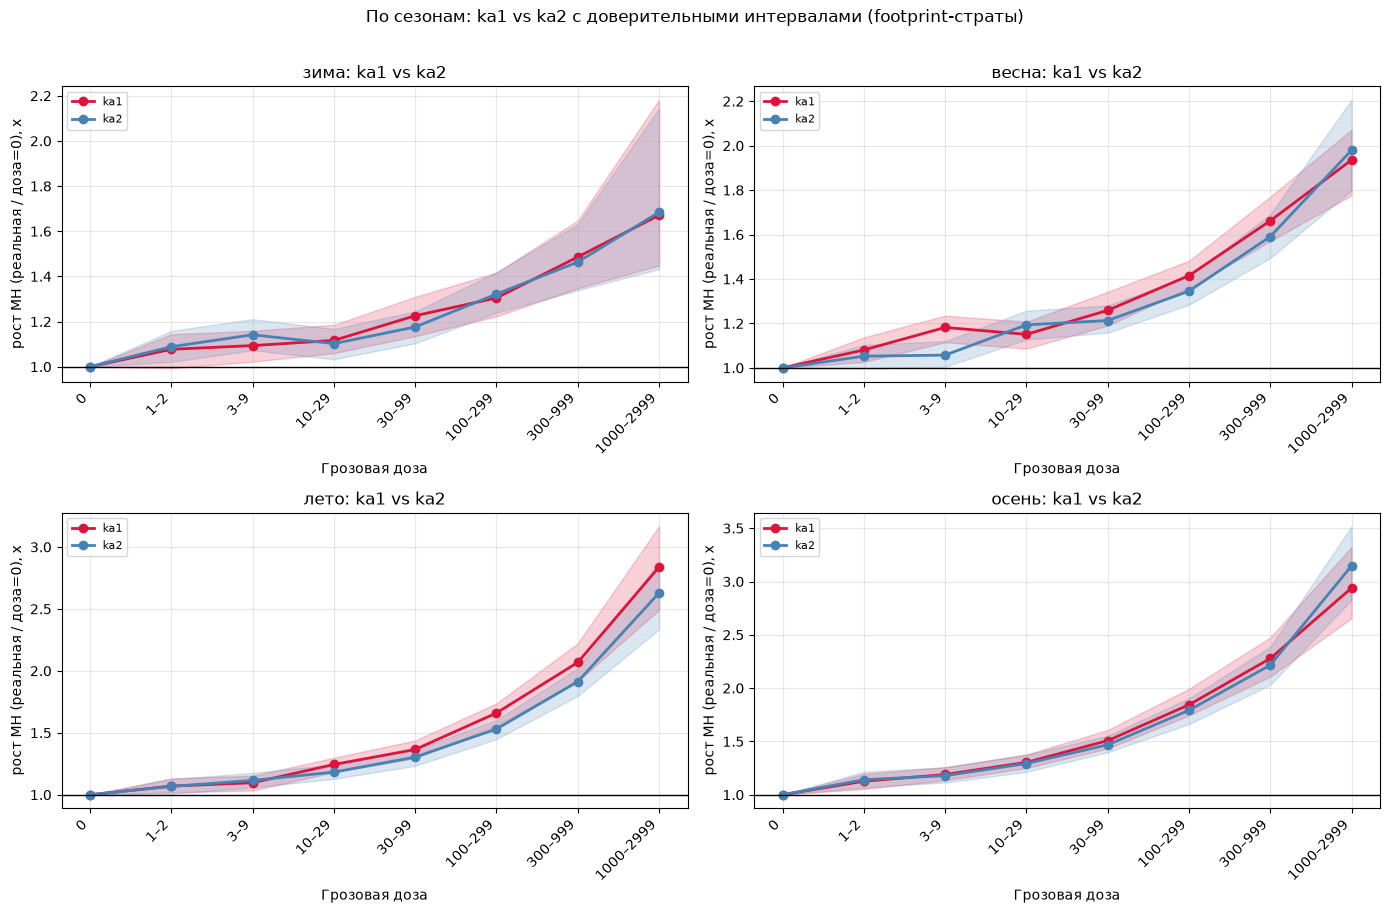

In [23]:
import numpy as np
import matplotlib.pyplot as plt


def accum_for_season(accum, season_idx):
    a2 = dict(accum)
    sl = (slice(None), slice(None), slice(None), slice(None), slice(season_idx, season_idx + 1))
    for key in ('exp_true_d', 'pos_true_d', 'prb_true_d', 'exp_null_d', 'pos_null_d', 'prb_null_d'):
        a2[key] = accum[key][sl]
    return a2


SC_COLORS = {'ka1': 'crimson', 'ka2': 'steelblue'}

SHOW_BIN_3000 = False  # False — не рисовать последний (открытый, ненадёжный) бин «≥3000»
dose_sl = slice(None) if SHOW_BIN_3000 else slice(None, -1)
x = np.arange(len(DOSE_LABELS[dose_sl]))

n_seasons = len(wc.SEASON_ORDER)
n_cols = 2
n_rows = -(-n_seasons // n_cols)  # ceil
fig, axes = plt.subplots(n_rows, n_cols, figsize=(7 * n_cols, 4.5 * n_rows), squeeze=False)
for season_idx, season_name in enumerate(wc.SEASON_ORDER):
    ax = axes[season_idx // n_cols, season_idx % n_cols]
    accum_season = accum_for_season(accum_fp_consistent, season_idx)
    for si, sc in enumerate(DOSE_SC):
        r = dp.analyze(accum_season, sc=si, n_boot=N_BOOT, ref_bin=REF_BIN, min_strat_exp=MIN_STRAT_EXP)
        color = SC_COLORS[sc]
        ax.plot(x, r['rr_t'][dose_sl], 'o-', color=color, lw=2, label=sc)
        ax.fill_between(x, r['ci_t'][0, dose_sl], r['ci_t'][1, dose_sl], color=color, alpha=0.2)
    ax.axhline(1.0, color='k', lw=1)
    ax.set_xticks(x)
    ax.set_xticklabels(DOSE_LABELS[dose_sl], rotation=45, ha='right')
    ax.set_xlabel('Грозовая доза')
    ax.set_ylabel('рост MH (реальная / доза=0), x')
    ax.set_title(f'{season_name}: ka1 vs ka2')
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)
for j in range(n_seasons, n_rows * n_cols):
    axes[j // n_cols, j % n_cols].axis('off')
fig.suptitle('По сезонам: ka1 vs ka2 с доверительными интервалами (footprint-страты)', y=1.01)
fig.tight_layout()
plt.show()
plt.close(fig)

### По сезонам — абсолютный уровень (не отношение)

Аналогично предыдущему: `rr_t` по сезонам выше нормирован на P(доза=0)
каждого сезона отдельно, сравнивать высоту сезонных линий друг с другом
напрямую нельзя. Здесь — `pk_t` (абсолютный P(verdict=1)) по тем же 4
сезонам, на одной шкале.

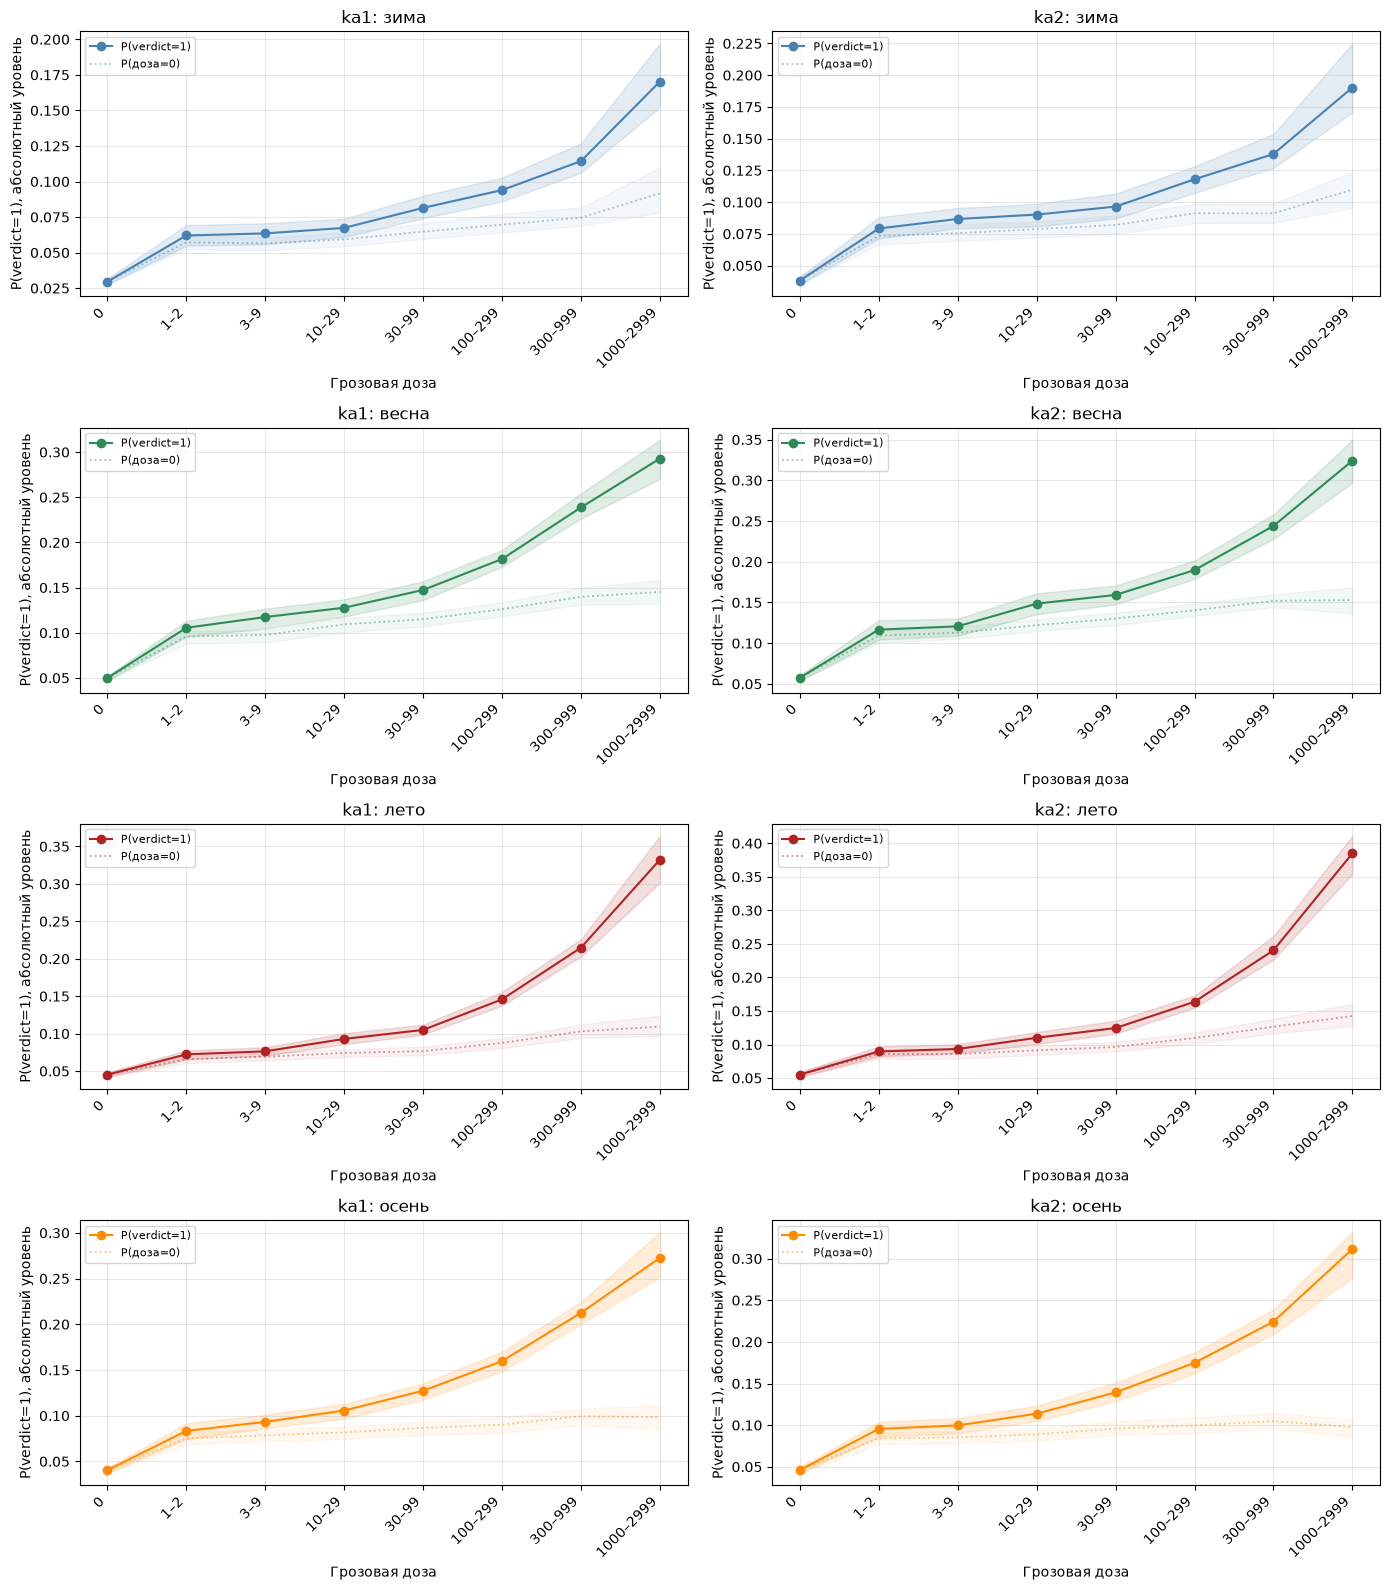

Как и с ночью/днём: сплошная линия — P(verdict=1) на бине, пунктир — P(доза=0) для того же сезона (та же MH-логика общего носителя, см. пояснение к ночь/день). 4 сезона делят страты в 4 раза мельче headline — на крайних бинах ожидаемо шире CI/меньше носителя, смотреть как ориентир.
CPU times: user 1.35 s, sys: 71.6 ms, total: 1.42 s
Wall time: 1.61 s


In [11]:
%%time
import numpy as np
import matplotlib.pyplot as plt

SHOW_BIN_3000 = False  # False — не рисовать последний (открытый, ненадёжный) бин «≥3000»
dose_sl = slice(None) if SHOW_BIN_3000 else slice(None, -1)

x = np.arange(len(DOSE_LABELS[dose_sl]))
n_seasons = len(wc.SEASON_ORDER)
fig, axes = plt.subplots(n_seasons, len(DOSE_SC),
                          figsize=(7 * len(DOSE_SC), 4 * n_seasons), squeeze=False)
for season_idx, season_name in enumerate(wc.SEASON_ORDER):
    accum_season = accum_for_season(accum_fp_consistent, season_idx)
    color = SEASON_COLORS[season_name]
    for si, sc in enumerate(DOSE_SC):
        r = dp.analyze(accum_season, sc=si, n_boot=N_BOOT, ref_bin=REF_BIN,
                       min_strat_exp=MIN_STRAT_EXP)
        ax = axes[season_idx, si]
        ax.plot(x, r['pk_t'][dose_sl], 'o-', color=color, label='P(verdict=1)')
        ax.fill_between(x, r['ci_pk_t'][0, dose_sl], r['ci_pk_t'][1, dose_sl], color=color, alpha=0.15)
        ax.plot(x, r['p0_t'][dose_sl], ':', color=color, alpha=0.5, lw=1.3, label='P(доза=0)')
        ax.fill_between(x, r['ci_p0_t'][0, dose_sl], r['ci_p0_t'][1, dose_sl], color=color, alpha=0.06)
        ax.set_xticks(x)
        ax.set_xticklabels(DOSE_LABELS[dose_sl], rotation=45, ha='right')
        ax.set_xlabel('Грозовая доза')
        ax.set_ylabel('P(verdict=1), абсолютный уровень')
        ax.set_title(f'{sc}: {season_name}')
        ax.grid(alpha=0.3)
        ax.legend(fontsize=8)
fig.tight_layout()
plt.show()
plt.close(fig)

print('Как и с ночью/днём: сплошная линия — P(verdict=1) на бине, пунктир — P(доза=0) '
      'для того же сезона (та же MH-логика общего носителя, см. пояснение к ночь/день). '
      '4 сезона делят страты в 4 раза мельче headline — на крайних бинах ожидаемо шире '
      'CI/меньше носителя, смотреть как ориентир.')

### По месяцам внутри локального сезона (с поправкой на полушарие)

Не календарный месяц, а «позиция внутри локального сезона»: «зима-1»/«зима-2»/
«зима-3» → «весна-1»...«осень-3» — 12 позиций. Для северных широт «зима-1» =
декабрь, для южных широт «зима-1» = июнь (см. `wc._SEA_N`/`wc._SEA_S` — те же
таблицы, что использует `wc.season_index`, только тут берём позицию месяца
ВНУТРИ сезона, а не сам сезон). Пересчёт `run_accumulation` не нужен — ось
суток уже есть в накопителе, полушарие страты определяется по знаку широты
её центра; следующая ячейка использует это, чтобы для каждой из 12 позиций
собрать нужное подмножество (сутки × широтная страта) прямо из уже готового
`accum_fp_consistent`.

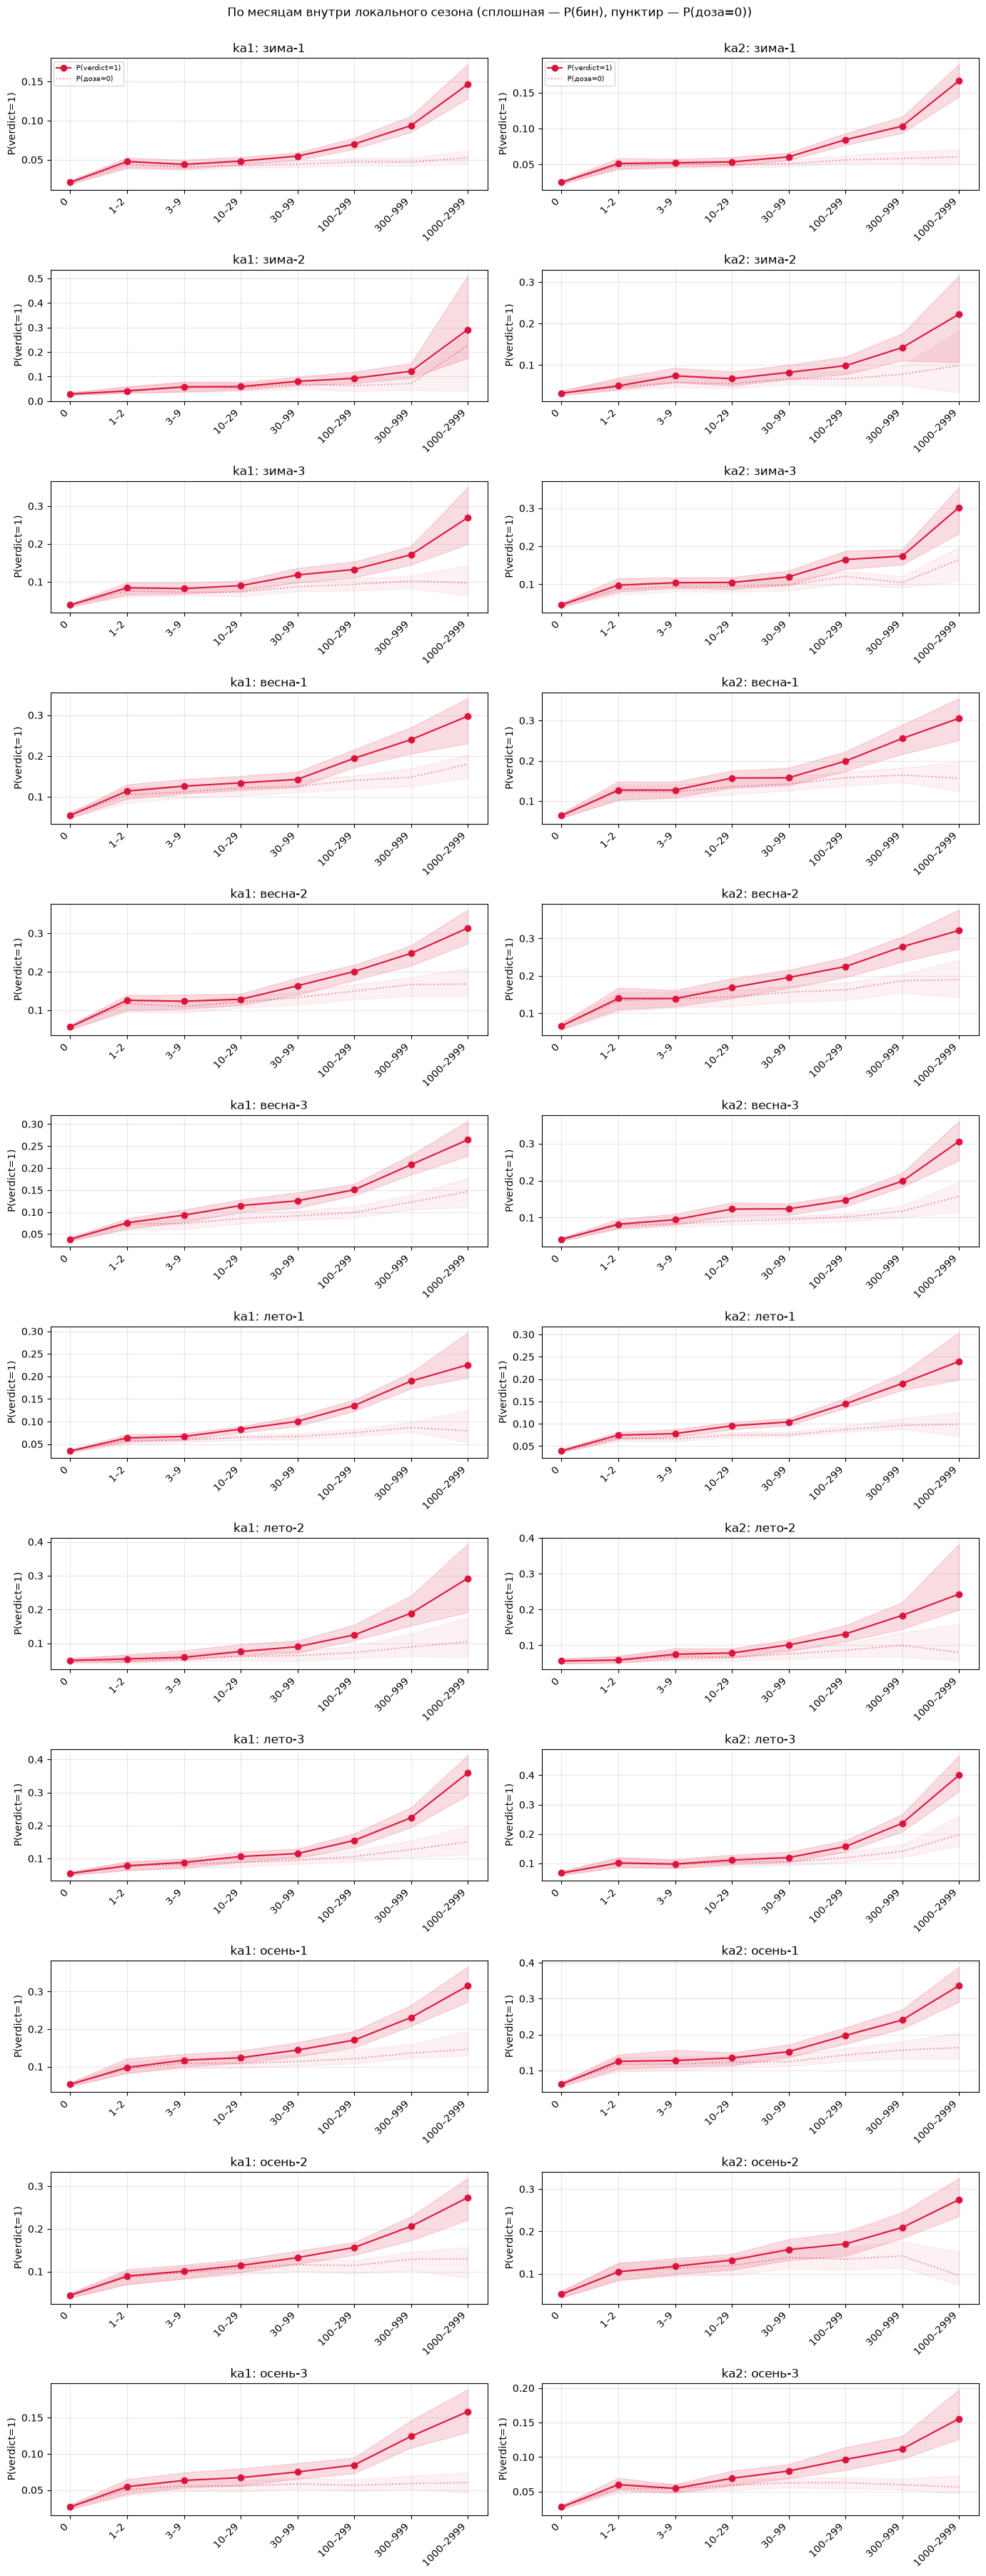

Носитель на месяц ещё в ~3 раза меньше, чем на сезон (и так уже тонкий) — ожидайте широкие/шумные CI на крайних бинах дозы у многих месяцев. results закэшированы в local_month_results — следующая ячейка (анимация) их переиспользует, не пересчитывает.


In [31]:
import numpy as np
import matplotlib.pyplot as plt


def accum_for_local_month(accum, pos):
    """pos: 0..11 — позиция внутри локального сезона (0=зима-1, ..., 11=осень-3),
    см. markdown выше. Возвращает accum-подобный dict с осью сезона схлопнутой
    в размер 1 и обнулённой экспозицией везде, кроме нужного (сутки×широта)
    подмножества — как accum_for_season, но по месяцу, а не по всему сезону."""
    n_days_a = accum['exp_true_d'].shape[0]
    n_latb_a = accum['n_latb']
    w_lat_a = 180.0 / n_latb_a
    lat_centers_a = -90 + w_lat_a * (np.arange(n_latb_a) + 0.5)
    is_north_bin = lat_centers_a >= 0

    day_months = np.array([int(str(np.datetime64(d, 'D'))[5:7]) for d in acc_days])
    sea_n = wc._SEA_N[day_months]
    sea_s = wc._SEA_S[day_months]
    mis = (day_months - 3) % 3  # позиция месяца внутри сезона — не зависит от полушария
    day_is_n = (sea_n * 3 + mis) == pos
    day_is_s = (sea_s * 3 + mis) == pos
    lat_mask = np.where(is_north_bin[None, :], day_is_n[:, None], day_is_s[:, None])  # (сутки, широта)
    mask7 = lat_mask.reshape(n_days_a, 1, n_latb_a, 1, 1, 1, 1)

    a2 = dict(accum)
    for key in ('exp_true_d', 'pos_true_d', 'prb_true_d', 'exp_null_d', 'pos_null_d', 'prb_null_d'):
        collapsed = accum[key].sum(axis=4, keepdims=True)  # схлопнуть ось сезона (season)
        a2[key] = collapsed * mask7
    return a2


LOCAL_MONTH_LABELS = [f'{s}-{i + 1}' for s in wc.SEASON_ORDER for i in range(3)]

SHOW_BIN_3000 = False  # False — не рисовать последний (открытый, ненадёжный) бин «≥3000»
dose_sl = slice(None) if SHOW_BIN_3000 else slice(None, -1)
x = np.arange(len(DOSE_LABELS[dose_sl]))

local_month_results = {}
for pos in range(12):
    accum_lm = accum_for_local_month(accum_fp_consistent, pos)
    for si, sc in enumerate(DOSE_SC):
        local_month_results[(pos, si)] = dp.analyze(
            accum_lm, sc=si, n_boot=N_BOOT, ref_bin=REF_BIN, min_strat_exp=MIN_STRAT_EXP)

fig, axes = plt.subplots(12, len(DOSE_SC), figsize=(7 * len(DOSE_SC), 3 * 12), squeeze=False)
for pos in range(12):
    for si, sc in enumerate(DOSE_SC):
        r = local_month_results[(pos, si)]
        ax = axes[pos, si]
        ax.plot(x, r['pk_t'][dose_sl], 'o-', color='crimson', label='P(verdict=1)')
        ax.fill_between(x, r['ci_pk_t'][0, dose_sl], r['ci_pk_t'][1, dose_sl], color='crimson', alpha=0.15)
        ax.plot(x, r['p0_t'][dose_sl], ':', color='crimson', alpha=0.5, lw=1.3, label='P(доза=0)')
        ax.fill_between(x, r['ci_p0_t'][0, dose_sl], r['ci_p0_t'][1, dose_sl], color='crimson', alpha=0.06)
        ax.set_xticks(x)
        ax.set_xticklabels(DOSE_LABELS[dose_sl], rotation=45, ha='right')
        ax.set_ylabel('P(verdict=1)')
        ax.set_title(f'{sc}: {LOCAL_MONTH_LABELS[pos]}')
        ax.grid(alpha=0.3)
        if pos == 0:
            ax.legend(fontsize=7)
fig.suptitle('По месяцам внутри локального сезона (сплошная — P(бин), пунктир — P(доза=0))', y=1.001)
fig.tight_layout()
plt.show()
plt.close(fig)

print('Носитель на месяц ещё в ~3 раза меньше, чем на сезон (и так уже тонкий) — ожидайте '
      'широкие/шумные CI на крайних бинах дозы у многих месяцев. results закэшированы в '
      'local_month_results — следующая ячейка (анимация) их переиспользует, не пересчитывает.')

### То же самое, анимацией по 12 месяцам

Переиспользует `local_month_results` из ячейки выше (не пересчитывает).
Фиксированная ось Y — иначе масштаб «прыгал» бы между кадрами.

In [32]:
import matplotlib.pyplot as plt
import matplotlib.animation as animation
from IPython.display import HTML

y_max = 0.0
for (pos, si), r in local_month_results.items():
    upper = r['ci_pk_t'][1, dose_sl]
    upper = upper[np.isfinite(upper)]
    if upper.size:
        y_max = max(y_max, upper.max())
y_max *= 1.1

fig_a, axes_a = plt.subplots(1, len(DOSE_SC), figsize=(7 * len(DOSE_SC), 4.5), squeeze=False)
axes_a = axes_a[0]


def update(pos):
    for si, sc in enumerate(DOSE_SC):
        ax = axes_a[si]
        ax.clear()
        r = local_month_results[(pos, si)]
        ax.plot(x, r['pk_t'][dose_sl], 'o-', color='crimson', label='P(verdict=1)')
        ax.fill_between(x, r['ci_pk_t'][0, dose_sl], r['ci_pk_t'][1, dose_sl], color='crimson', alpha=0.15)
        ax.plot(x, r['p0_t'][dose_sl], ':', color='crimson', alpha=0.5, lw=1.3, label='P(доза=0)')
        ax.fill_between(x, r['ci_p0_t'][0, dose_sl], r['ci_p0_t'][1, dose_sl], color='crimson', alpha=0.06)
        ax.set_xticks(x)
        ax.set_xticklabels(DOSE_LABELS[dose_sl], rotation=45, ha='right')
        ax.set_ylim(0, y_max)
        ax.set_ylabel('P(verdict=1)')
        ax.set_title(sc)
        ax.grid(alpha=0.3)
        ax.legend(fontsize=8, loc='upper left')
    fig_a.suptitle(f'Месяц внутри сезона: {LOCAL_MONTH_LABELS[pos]}  ({pos + 1}/12)', fontsize=13)
    return []


anim = animation.FuncAnimation(fig_a, update, frames=12, interval=900, blit=False, repeat=True)
plt.close(fig_a)
HTML(anim.to_jshtml())

### Анимация по 4 сезонам

Тот же приём, что у 12 локальных месяцев выше, на обычных сезонах (`accum_for_season`). Свой кэш `season_results`.


In [33]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.animation as animation
from IPython.display import HTML


def accum_for_season(accum, season_idx):
    a2 = dict(accum)
    sl = (slice(None), slice(None), slice(None), slice(None), slice(season_idx, season_idx + 1))
    for key in ('exp_true_d', 'pos_true_d', 'prb_true_d', 'exp_null_d', 'pos_null_d', 'prb_null_d'):
        a2[key] = accum[key][sl]
    return a2


SHOW_BIN_3000 = False  # False — не рисовать последний (открытый, ненадёжный) бин «≥3000»
dose_sl = slice(None) if SHOW_BIN_3000 else slice(None, -1)
x = np.arange(len(DOSE_LABELS[dose_sl]))

season_results = {}
for season_idx, season_name in enumerate(wc.SEASON_ORDER):
    accum_season = accum_for_season(accum_fp_consistent, season_idx)
    for si, sc in enumerate(DOSE_SC):
        season_results[(season_idx, si)] = dp.analyze(
            accum_season, sc=si, n_boot=N_BOOT, ref_bin=REF_BIN, min_strat_exp=MIN_STRAT_EXP)

y_max_s = 0.0
for (season_idx, si), r in season_results.items():
    upper = r['ci_pk_t'][1, dose_sl]
    upper = upper[np.isfinite(upper)]
    if upper.size:
        y_max_s = max(y_max_s, upper.max())
y_max_s *= 1.1

fig_s, axes_s = plt.subplots(1, len(DOSE_SC), figsize=(7 * len(DOSE_SC), 4.5), squeeze=False)
axes_s = axes_s[0]


def update_season(season_idx):
    for si, sc in enumerate(DOSE_SC):
        ax = axes_s[si]
        ax.clear()
        r = season_results[(season_idx, si)]
        ax.plot(x, r['pk_t'][dose_sl], 'o-', color='crimson', label='P(verdict=1)')
        ax.fill_between(x, r['ci_pk_t'][0, dose_sl], r['ci_pk_t'][1, dose_sl], color='crimson', alpha=0.15)
        ax.plot(x, r['p0_t'][dose_sl], ':', color='crimson', alpha=0.5, lw=1.3, label='P(доза=0)')
        ax.fill_between(x, r['ci_p0_t'][0, dose_sl], r['ci_p0_t'][1, dose_sl], color='crimson', alpha=0.06)
        ax.set_xticks(x)
        ax.set_xticklabels(DOSE_LABELS[dose_sl], rotation=45, ha='right')
        ax.set_ylim(0, y_max_s)
        ax.set_ylabel('P(verdict=1)')
        ax.set_title(sc)
        ax.grid(alpha=0.3)
        ax.legend(fontsize=8, loc='upper left')
    fig_s.suptitle(f'Сезон: {wc.SEASON_ORDER[season_idx]}  ({season_idx + 1}/4)', fontsize=13)
    return []


anim_s = animation.FuncAnimation(fig_s, update_season, frames=len(wc.SEASON_ORDER),
                                 interval=1200, blit=False, repeat=True)
plt.close(fig_s)
HTML(anim_s.to_jshtml())

## Энергия молний при фиксированной дозе — медиана, footprint-страты

Тот же вопрос, что в блоке медианы `wwlln_reader_dose.ipynb`: при одном и том же числе молний меняется ли доля свистов, если медианная энергия этих молний выше. Нулевой модели для энергии нет.

Отличия от того блока. Здесь доза, энергия и страты считаются в точке footprint (`geometry='footprint'`, `strata_by_geometry=True`, высота 827 км), страты 12×12, как у baseline этого ноутбука. В ноутбуке дозы медиана считалась у подспутниковой точки, с 8 долготными полосами, на сутках, где есть оба спутника. Функция та же: `dp.run_median_energy_lon`. Терцили те же: 0 / 600 / 1900 Дж, подписи «<0.6 кДж», «0.6–1.9 кДж», «≥1.9 кДж». Гистограмма — 16 тонких бинов до 4000 Дж.

`gdt_min` этой ячейки равен 5, при том что остальной ноутбук на сетке 1 минута. Гистограмма держит 16 сеток в кэше вместо одной суммы, и минутная сетка была бы примерно впятеро тяжелее по памяти. Медиана по-прежнему за окно 30 минут.

Сохранённый прогон: 366 суток сетки, экспозиция 58 149 991 с, около 570 МБ на кэш из 2 суток, wall time 36 мин 33 с. Это тот же масштаб, что у baseline выше, и другой, чем 255 суток основного ноутбука.


In [13]:
%%time
import traceback

import numpy as np
import pandas as pd

# Терцили реального распределения энергии WWLLN (см. wwlln_reader_dose.ipynb) —
# 33-й/66-й перцентили ~592/~1868 Дж, округлено до 600/1900.
E_EDGES_TERTILE = np.array([0.0, 600.0, 1900.0, np.inf])
E_LABELS_TERTILE = ['<0.6 кДж', '0.6–1.9 кДж', '≥1.9 кДж']

accum_lon_median_energy = None
try:
    accum_lon_median_energy = dp.run_median_energy_lon(
        df, df_pred, sc_list=DOSE_SC, acc_days=acc_days,
        dose_r_km=DOSE_R_KM, dose_dt_min=DOSE_DT_MIN,
        glat=GLAT, glon=GLON, gdt_min=5,  # не GDT_MIN=1 — см. markdown выше
        night_sza_deg=NIGHT_SZA_DEG, strata_scheme=STRATA_SCHEME, n_lonb=N_LONB, n_latb=N_LATB,
        dose_edges=DOSE_EDGES, e_edges=E_EDGES_TERTILE,
        n_hist_bins=16, e_hist_max=4000.0,
        geometry='footprint', sat_height_km=SAT_HEIGHT_KM, strata_by_geometry=True,
    )
    print(f"accum_lon_median_energy готов ({accum_lon_median_energy['exp_en_d'].sum():,.0f} сэмплов).")
except Exception:
    print('!!! ОШИБКА в accum_lon_median_energy:')
    traceback.print_exc()

Гистограмма энергии (медиана): 16 тонких бинов (0…4000, +overflow), ~570 МБ на кэш из 2 суток; сетки строим для 366 дней (схема страт='lon')
  ... 20/366 дней
  ... 40/366 дней
  ... 60/366 дней
  ... 80/366 дней
  ... 100/366 дней
  ... 120/366 дней
  ... 140/366 дней
  ... 160/366 дней
  ... 180/366 дней
  ... 200/366 дней
  ... 220/366 дней
  ... 240/366 дней
  ... 260/366 дней
  ... 280/366 дней
  ... 300/366 дней
  ... 320/366 дней
  ... 340/366 дней
  ... 360/366 дней
Готово. Экспозиция: 58,149,991 сэмплов, verdict=1: 4,890,665 (8.41%)
accum_lon_median_energy готов (58,149,992 сэмплов).
CPU times: user 18min 33s, sys: 10min 49s, total: 29min 22s
Wall time: 36min 33s


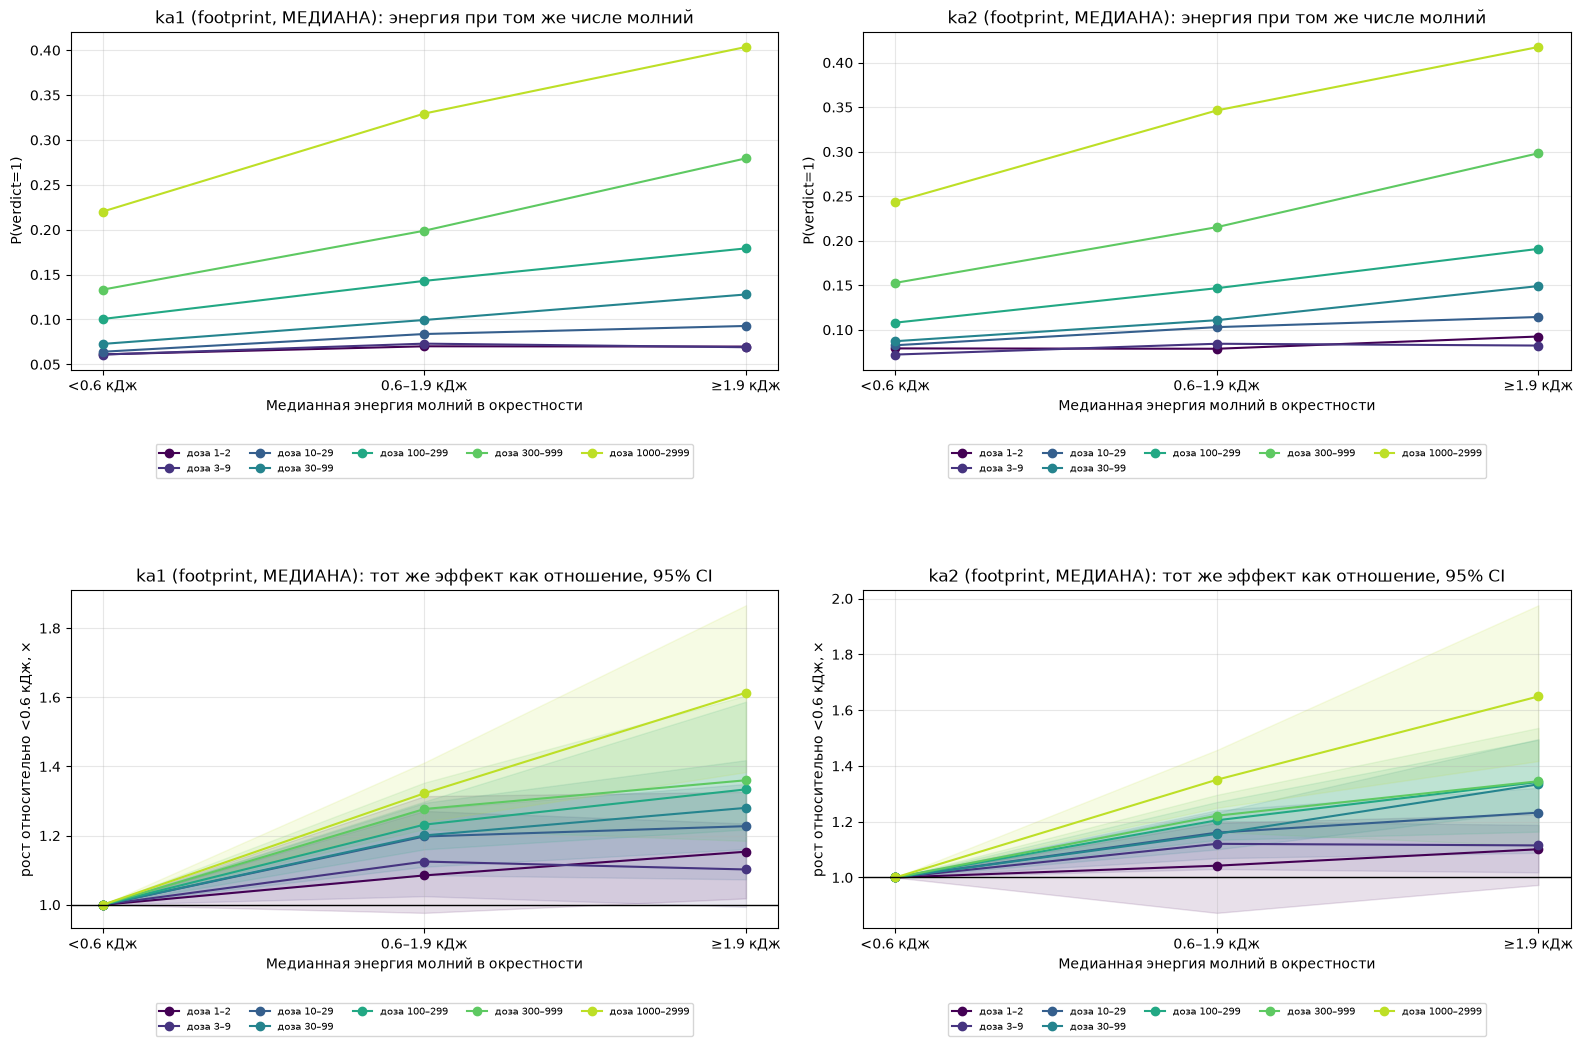

CPU times: user 18.8 s, sys: 2.17 s, total: 21 s
Wall time: 28.8 s


In [14]:
%%time
import numpy as np
import matplotlib.pyplot as plt

SHOW_BIN_3000 = False  # False — не рисовать последний (открытый, ненадёжный) бин «≥3000»

if accum_lon_median_energy is None:
    print('accum_lon_median_energy не посчитан — см. traceback в ячейке выше, график пропущен.')
else:
    n_dose_e = accum_lon_median_energy['n_dose']
    _bin_hi = n_dose_e if SHOW_BIN_3000 else n_dose_e - 1
    show_bins_med = [i for i in range(1, _bin_hi)
                     if accum_lon_median_energy['exp_en_d'][..., i, :].sum() > 50 * MIN_STRAT_EXP]
    if show_bins_med:
        ncol = min(len(show_bins_med), 5)
        fig, axes = plt.subplots(2, len(DOSE_SC), figsize=(8 * len(DOSE_SC), 11.0), squeeze=False)
        for si, sc in enumerate(DOSE_SC):
            ax_a, ax_r = axes[0, si], axes[1, si]
            cmap = plt.cm.viridis(np.linspace(0, 0.9, len(show_bins_med)))
            for ci_i, db in enumerate(show_bins_med):
                rr, ci95, p_k, nst, _ = dp.analyze_energy_lon(
                    accum_lon_median_energy, si, db, n_boot=N_BOOT, min_strat_exp=MIN_STRAT_EXP)
                x = np.arange(accum_lon_median_energy['n_eb'])
                ax_a.plot(x, p_k, 'o-', color=cmap[ci_i], label=f'доза {DOSE_LABELS[db]}')
                ax_r.plot(x, rr, 'o-', color=cmap[ci_i], label=f'доза {DOSE_LABELS[db]}')
                ax_r.fill_between(x, ci95[0], ci95[1], color=cmap[ci_i], alpha=0.12)
            ax_r.axhline(1.0, color='k', lw=1)
            ax_a.set_ylabel('P(verdict=1)')
            ax_r.set_ylabel('рост относительно <0.6 кДж, ×')
            ax_a.set_title(f'{sc} (footprint, МЕДИАНА): энергия при том же числе молний')
            ax_r.set_title(f'{sc} (footprint, МЕДИАНА): тот же эффект как отношение, 95% CI')
            for ax in (ax_a, ax_r):
                ax.set_xticks(np.arange(accum_lon_median_energy['n_eb']))
                ax.set_xticklabels(E_LABELS_TERTILE)
                ax.set_xlabel('Медианная энергия молний в окрестности')
                ax.grid(alpha=0.3)
                ax.legend(fontsize=7, loc='upper center', bbox_to_anchor=(0.5, -0.22),
                          ncol=ncol, borderaxespad=0.)
        fig.tight_layout(rect=[0, 0.03, 1, 1])
        fig.subplots_adjust(hspace=0.65)
        plt.show()
        plt.close(fig)
    else:
        print('Нет ни одного бина дозы с достаточной экспозицией по энергии (медиана) — график не построен.')

### Точные числа CI для эффекта энергии (медиана, footprint) — проверка: не перекрывает ли CI единицу

Та же таблица, что в основном ноутбуке, но на footprint-накопителе выше.


In [15]:
import numpy as np
import pandas as pd

if accum_lon_median_energy is None or not show_bins_med:
    print('accum_lon_median_energy не посчитан или нет бинов с носителем — таблицу построить не из чего.')
else:
    rows = []
    for si, sc in enumerate(DOSE_SC):
        for db in show_bins_med:
            rr, ci95, p_k, nst, expo = dp.analyze_energy_lon(
                accum_lon_median_energy, si, db, n_boot=N_BOOT, min_strat_exp=MIN_STRAT_EXP)
            for eb in range(1, accum_lon_median_energy['n_eb']):
                if not np.isfinite(rr[eb]):
                    continue
                rows.append({
                    'КА': sc,
                    'бин дозы': DOSE_LABELS[db],
                    'энергия': f'{E_LABELS_TERTILE[eb]} vs {E_LABELS_TERTILE[0]}',
                    'рост': rr[eb],
                    'CI низ': ci95[0, eb],
                    'CI верх': ci95[1, eb],
                    'страт': int(nst[eb]),
                    'CI накрывает 1?': 'да' if ci95[0, eb] <= 1.0 <= ci95[1, eb] else 'нет',
                })
    median_energy_lon_ci_table = pd.DataFrame(rows)
    display(median_energy_lon_ci_table.round(3))
    n_total = len(median_energy_lon_ci_table)
    n_covering = (median_energy_lon_ci_table['CI накрывает 1?'] == 'да').sum()
    print(f'CI накрывает 1.0 в {n_covering} из {n_total} строк ({100*n_covering/max(n_total,1):.0f}%).')


,КА,бин дозы,энергия,рост,CI низ,CI верх,страт,CI накрывает 1?
0,ka1,1–2,0.6–1.9 кДж vs <0.6 кДж,1.085,0.977,1.314,103,да
1,ka1,1–2,≥1.9 кДж vs <0.6 кДж,1.153,1.019,1.327,118,нет
2,ka1,3–9,0.6–1.9 кДж vs <0.6 кДж,1.125,1.025,1.271,151,нет
3,ka1,3–9,≥1.9 кДж vs <0.6 кДж,1.102,0.994,1.235,148,да
4,ka1,10–29,0.6–1.9 кДж vs <0.6 кДж,1.197,1.086,1.276,174,нет
5,ka1,10–29,≥1.9 кДж vs <0.6 кДж,1.227,1.073,1.349,132,нет
6,ka1,30–99,0.6–1.9 кДж vs <0.6 кДж,1.201,1.110,1.295,185,нет
7,ka1,30–99,≥1.9 кДж vs <0.6 кДж,1.280,1.161,1.418,111,нет
8,ka1,100–299,0.6–1.9 кДж vs <0.6 кДж,1.232,1.160,1.299,157,нет
9,ka1,100–299,≥1.9 кДж vs <0.6 кДж,1.334,1.218,1.587,54,нет


CI накрывает 1.0 в 4 из 28 строк (14%).


### Сводка: где интервал медианы исключает 1

По уже посчитанной таблице интервалов: для каждого бина дозы — сколько строк энергии исключают 1 и какой там рост. Нового прогона нет.


In [16]:
import pandas as pd

if 'median_energy_lon_ci_table' not in globals() or median_energy_lon_ci_table.empty:
    print('median_energy_lon_ci_table пуста/не посчитана — сводную таблицу построить не из чего.')
else:
    rows = []
    for db in show_bins_med:
        lab = DOSE_LABELS[db]
        sub = median_energy_lon_ci_table[median_energy_lon_ci_table['бин дозы'] == lab]
        if sub.empty:
            continue
        n_total = len(sub)
        sig = sub[sub['CI накрывает 1?'] == 'нет']
        n_sig = len(sig)
        if n_sig == 0:
            znach = 'нет, CI везде накрывает 1'
            comment = 'эффекта энергии (медиана) статистически нет'
        elif n_sig == n_total:
            znach = 'да, везде'
            growth = (sig['рост'] - 1) * 100
            comment = f'рост {growth.min():.0f}–{growth.max():.0f}%'
        else:
            znach = f'да, частично ({n_sig}/{n_total})'
            growth = (sig['рост'] - 1) * 100
            comment = f'рост {growth.min():.0f}–{growth.max():.0f}% там, где значимо'
        nst_min, nst_max = int(sub['страт'].min()), int(sub['страт'].max())
        if nst_max < 10:
            comment += f' — мало страт ({nst_min}–{nst_max}), похоже на нехватку данных'
        rows.append({
            'диапазон дозы': lab,
            'значимость (CI искл. 1)': znach,
            'коммент': comment,
            'страт (мин–макс)': f'{nst_min}–{nst_max}',
        })
    median_energy_slide_table = pd.DataFrame(rows)
    display(median_energy_slide_table)


,диапазон дозы,значимость (CI искл. 1),коммент,страт (мин–макс)
0,1–2,"да, частично (1/4)","рост 15–15% там, где значимо",103–131
1,3–9,"да, частично (3/4)","рост 11–12% там, где значимо",148–159
2,10–29,"да, везде",рост 16–23%,132–175
3,30–99,"да, везде",рост 16–33%,111–199
4,100–299,"да, везде",рост 20–34%,54–170
5,300–999,"да, везде",рост 22–36%,30–134
6,1000–2999,"да, везде",рост 32–65%,8–47


### Состав энергии внутри каждой дозы (footprint) — нормировка по строке

Доля каждого энергобина ВНУТРИ фиксированной дозы (100% по строке, не по
столбцу) — убирает эффект «высокая доза сама по себе редкая». Доза=0 на
графике не показана (там 100% приходится на заглушку median_e=0, не
содержательно), но остаётся в таблице для полноты.


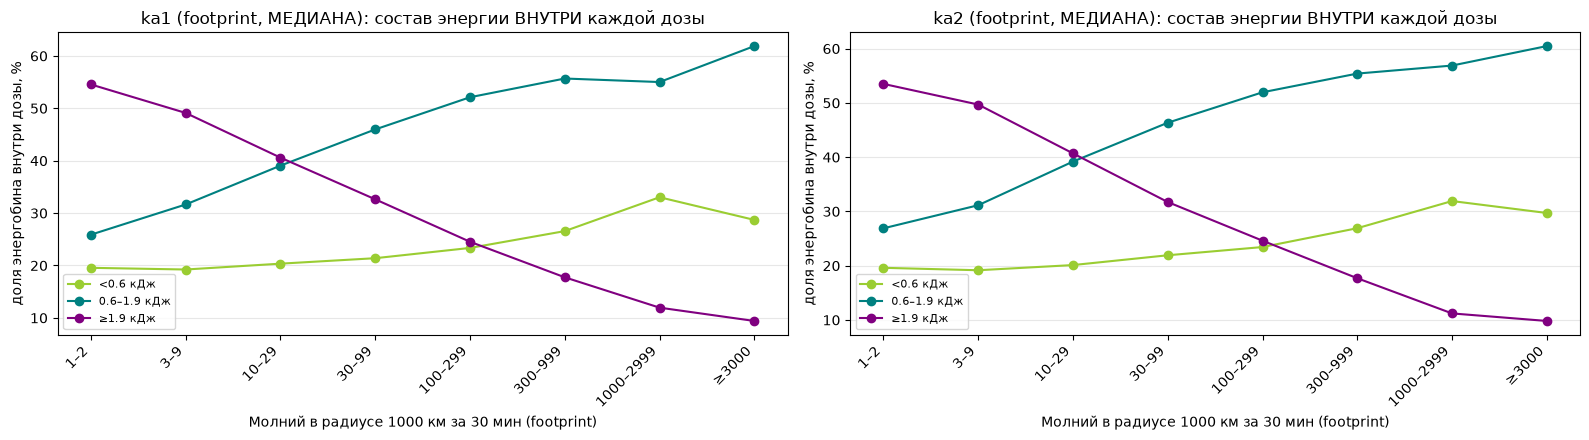

,КА,бин дозы,n (всего),"<0.6 кДж, %","0.6–1.9 кДж, %","≥1.9 кДж, %"
0,ka1,0,18325628,100.00,0.00,0.00
1,ka1,1–2,1023290,19.56,25.88,54.56
2,ka1,3–9,1428794,19.23,31.65,49.12
3,ka1,10–29,1618525,20.35,39.06,40.59
4,ka1,30–99,1991686,21.39,45.97,32.63
5,ka1,100–299,1783796,23.35,52.12,24.53
6,ka1,300–999,1425454,26.56,55.69,17.75
7,ka1,1000–2999,627621,33.03,55.02,11.95
8,ka1,≥3000,153327,28.70,61.88,9.41
9,ka2,0,19248176,100.00,0.00,0.00


Если доля "≥1.9кДж" внутри дозы падает с ростом дозы — это состав, независимый от общей редкости высокой дозы (нормировка убрала этот эффект).


In [17]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

if accum_lon_median_energy is None:
    print('accum_lon_median_energy не посчитан — эта ячейка пропущена.')
else:
    n_dose_e = accum_lon_median_energy['n_dose']
    n_eb = accum_lon_median_energy['n_eb']
    dose_idx = np.arange(1, n_dose_e)  # без дозы=0 — там 100% приходится на заглушку median_e=0
    x = np.arange(len(dose_idx))
    LINE_COLORS = ['yellowgreen', 'teal', 'purple']

    fig, axes = plt.subplots(1, len(DOSE_SC), figsize=(8 * len(DOSE_SC), 4.5), squeeze=False)
    row_norm_rows = []
    for si, sc in enumerate(DOSE_SC):
        exp_e = accum_lon_median_energy['exp_en_d'][:, si].sum(axis=(0, 1, 2, 3, 4)).astype(np.float64)
        row_totals = exp_e.sum(axis=1, keepdims=True)
        pct_row = np.divide(exp_e, row_totals, out=np.zeros_like(exp_e), where=row_totals > 0) * 100

        ax = axes[0, si]
        for eb in range(n_eb):
            color = LINE_COLORS[eb % len(LINE_COLORS)]
            ax.plot(x, pct_row[dose_idx, eb], 'o-', color=color, label=E_LABELS_TERTILE[eb])
        ax.set_xticks(x)
        ax.set_xticklabels([DOSE_LABELS[i] for i in dose_idx], rotation=45, ha='right')
        ax.set_ylabel('доля энергобина внутри дозы, %')
        ax.set_xlabel(f'Молний в радиусе {DOSE_R_KM:.0f} км за {DOSE_DT_MIN} мин (footprint)')
        ax.set_title(f'{sc} (footprint, МЕДИАНА): состав энергии ВНУТРИ каждой дозы')
        ax.grid(alpha=0.3, axis='y')
        ax.legend(fontsize=8)

        for db in range(n_dose_e):
            row = {'КА': sc, 'бин дозы': DOSE_LABELS[db], 'n (всего)': int(row_totals[db, 0])}
            for eb in range(n_eb):
                row[f'{E_LABELS_TERTILE[eb]}, %'] = pct_row[db, eb]
            row_norm_rows.append(row)
    fig.tight_layout()
    plt.show()
    plt.close(fig)

    median_energy_row_norm_table = pd.DataFrame(row_norm_rows)
    display(median_energy_row_norm_table.round(2))
    print('Если доля "≥1.9кДж" внутри дозы падает с ростом дозы — это состав, независимый '
          'от общей редкости высокой дозы (нормировка убрала этот эффект).')


## Энергия молний: почему ночью выше — суточный ход, суша vs океан

После медианы остаётся вопрос. В основном ноутбуке медианная энергия
молний, ассоциированных со свистами, систематически выше ночью. Две конкурирующие
гипотезы:
- **приборная** — WWLLN восстанавливает энергию из амплитуды ОНЧ-сигнала с
  поправкой на затухание в волноводе Земля-ионосфера; ночью затухание в разы
  меньше — известное остаточное смещение сети, не физика молнии;
- **физическая** — ночные грозы чаще океанические мезомасштабные конвективные
  системы (MCS) с более высокими пиковыми токами, чем дневные континентальные.

**Тест**: суточный ход медианной энергии, раздельно суша/океан — по самим
молниям WWLLN (`df`), без всякой привязки к свисту/спутнику/дозе. Если подъём
энергии ночью одинаков и над сушей, и над океаном — вероятно приборный эффект
(затухание в волноводе не зависит от типа поверхности под молнией). Если подъём
заметно сильнее только над океаном — вероятно физический (там, где преобладают
ночные MCS).

**Маска суша/океан** — грубая (1°), растеризована ОДИН РАЗ из полигонов Natural
Earth (`cartopy`, уже закэшированы локально; `shapely` для point-in-polygon),
дальше для всех молний сразу — просто lookup по сетке (векторизовано), без
per-point polygon-теста на миллионах точек. Ни `cartopy`, ни `shapely` не нужно
доустанавливать — оба уже есть в окружении. LST — та же формула, что и в
`dose_pipeline.py` (`mod(utc_час + lon/15, 24)`).

Дёшево — не sweep: ~1-2 минуты на весь период накопления.


Маска суша/океан готова: 33.1% ячеек — суша (Natural Earth 50m, сетка 1°)
Молний всего: 254,128,337 (51.4% над сушей)


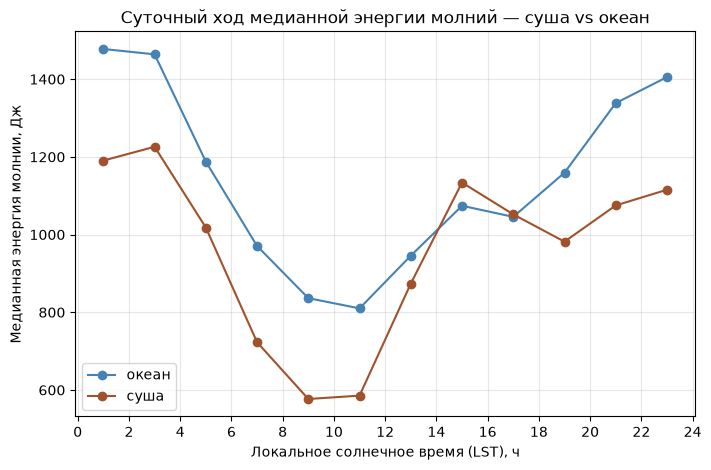

Океан: ночь/день = 1.75 (1441 / 823 Дж)
Суша:  ночь/день = 1.98 (1153 / 581 Дж)
Если отношение похоже над сушей и над океаном — ближе к приборному объяснению (затухание в волноводе не зависит от типа поверхности). Если сильно различается (особенно если рост только над океаном) — ближе к физическому (ночные MCS).
CPU times: user 21.1 s, sys: 32.2 s, total: 53.3 s
Wall time: 1min 41s


In [29]:
%%time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cartopy.io.shapereader as shpreader
import shapely.geometry as sgeom
import shapely.prepared

# --- маска суша/океан, 1°, строится один раз ---
LAND_GRID_DEG = 1.0
_lat_edges = np.arange(-90.0, 90.0 + 1e-9, LAND_GRID_DEG)
_lon_edges = np.arange(-180.0, 180.0 + 1e-9, LAND_GRID_DEG)
_lat_c = 0.5 * (_lat_edges[:-1] + _lat_edges[1:])
_lon_c = 0.5 * (_lon_edges[:-1] + _lon_edges[1:])

_land_shp = shpreader.natural_earth(resolution='50m', category='physical', name='land')
_land_geoms = list(shpreader.Reader(_land_shp).geometries())
_land_union = sgeom.MultiPolygon([g for geom in _land_geoms
                                  for g in (geom.geoms if geom.geom_type == 'MultiPolygon' else [geom])])
_prepared_land = shapely.prepared.prep(_land_union)

land_grid = np.zeros((len(_lat_c), len(_lon_c)), dtype=bool)
for _i, _la in enumerate(_lat_c):
    for _j, _lo in enumerate(_lon_c):
        land_grid[_i, _j] = _prepared_land.contains(sgeom.Point(_lo, _la))
print(f'Маска суша/океан готова: {land_grid.mean() * 100:.1f}% ячеек — суша (Natural Earth 50m, сетка 1°)')

# --- LST и классификация суша/океан для всех молний ---
_lat_r = df['lat'].values.astype(np.float64)
_lon_r = df['lon'].values.astype(np.float64)
_energy_r = df['energy'].values.astype(np.float64)
_dt_r = df['datetime'].values
_utc_hour = ((_dt_r.astype('datetime64[s]') - _dt_r.astype('datetime64[D]'))
             .astype('timedelta64[s]').astype(np.float64) / 3600.0)
lst_r = np.mod(_utc_hour + _lon_r / 15.0, 24.0)

_ii = np.clip(((_lat_r + 90.0) / LAND_GRID_DEG).astype(np.int64), 0, len(_lat_c) - 1)
_jj = np.clip(((_lon_r + 180.0) / LAND_GRID_DEG).astype(np.int64), 0, len(_lon_c) - 1)
is_land_r = land_grid[_ii, _jj]
print(f'Молний всего: {len(_energy_r):,} ({is_land_r.mean() * 100:.1f}% над сушей)')

# --- суточный ход медианы энергии, 12 бинов по 2ч LST, раздельно суша/океан ---
N_LST_BINS = 12
lst_bin_r = np.clip((lst_r // (24 / N_LST_BINS)).astype(np.int64), 0, N_LST_BINS - 1)
_diurnal = pd.DataFrame({'lst_bin': lst_bin_r, 'is_land': is_land_r, 'energy': _energy_r})
diurnal_energy = _diurnal.groupby(['is_land', 'lst_bin'])['energy'].median().unstack(0)
diurnal_energy.columns = ['океан', 'суша']

bin_centers = (np.arange(N_LST_BINS) + 0.5) * (24 / N_LST_BINS)
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(bin_centers, diurnal_energy['океан'], 'o-', color='steelblue', label='океан')
ax.plot(bin_centers, diurnal_energy['суша'], 'o-', color='sienna', label='суша')
ax.set_xlabel('Локальное солнечное время (LST), ч')
ax.set_ylabel('Медианная энергия молнии, Дж')
ax.set_title('Суточный ход медианной энергии молний — суша vs океан')
ax.set_xticks(np.arange(0, 25, 2))
ax.grid(alpha=0.3)
ax.legend()
plt.show()
plt.close(fig)

# --- ночь/день как отношение (ночь ≈ LST 22-02, день ≈ LST 08-12 — минимум хода) ---
night_bins = [11, 0]
day_bins = [4, 5]
night_ocean = diurnal_energy['океан'].iloc[night_bins].mean()
day_ocean = diurnal_energy['океан'].iloc[day_bins].mean()
night_land = diurnal_energy['суша'].iloc[night_bins].mean()
day_land = diurnal_energy['суша'].iloc[day_bins].mean()
print(f'Океан: ночь/день = {night_ocean / day_ocean:.2f} ({night_ocean:.0f} / {day_ocean:.0f} Дж)')
print(f'Суша:  ночь/день = {night_land / day_land:.2f} ({night_land:.0f} / {day_land:.0f} Дж)')
print('Если отношение похоже над сушей и над океаном — ближе к приборному объяснению '
      '(затухание в волноводе не зависит от типа поверхности). Если сильно различается '
      '(особенно если рост только над океаном) — ближе к физическому (ночные MCS).')

## Sweep по R и Δt

Радиусы 500, 1000, 1500, 2000, 3000 км и окна 2, 5, 10, 15, 30, 60 мин. Пороги бинов дозы те же, что калибровались на 30-минутное окно: границы на коротком Δt не растягиваются. На Δt = 2 мин в верхние бины попадает мало молний, и часть сегментов на рисунке пустая. Это нижний край, где доза как признак ещё не набирается.

Полные 30 пар не считаются. Для двух рисунков хватает 10: все пять радиусов при Δt = 30 мин и все шесть окон при R = 1000 км. Общая сетка молний и footprint строится один раз, пары отличаются свёрткой уже готовых бинов.

1500 км — точка этой сетки. Ориентир source-region по следу силовой линии — около 1000–1500 км (Chum et al. 2006, Ann. Geophys., https://doi.org/10.5194/angeo-24-2921-2006). Отдельной линии на 1500 км на рисунке нет.

Величина на рисунке — P(сегмент) − P(доза=0), отдельно день и ночь, по ka1 и ka2. Девять бинов склеены в четыре сегмента плюс опорный «0»: низкий (1–2, 3–9), средний-низкий (10–29, 30–99), средний-высокий (100–299, 300–999), высокий (1000–2999, ≥3000). Склейка — сумма по оси дозы уже посчитанного накопителя.

Сохранённый прогон: 347 суток сетки, экспозиция 56 986 414 с, wall time 1 ч 3 мин. Это короче 363 суток, которые печатает текущая загрузка, и короче 366 суток baseline.


In [46]:
# Радиусы и окна сырого sweep ниже. Полные 5×6 пар не считаются:
# прогон берёт все R при Δt=30 и все Δt при R=1000.
R_LIST = [500.0, 1000.0, 1500.0, 2000.0, 3000.0]
DT_LIST = [2, 5, 10, 15, 30, 60]


### Прогон 10 пар и рисунок сегментов

`dp.sweep_r_dt` без `dose_edges_base_dt`: пороги `DOSE_EDGES` как есть. Результат — `sweep_fp_raw`, сразу склеенный в `sweep_fp_raw_segments`. Следующая ячейка рисует два среза: радиус при фиксированном Δt = 30 мин и окно при фиксированном R = 1000 км.


In [47]:
%%time
import traceback

import numpy as np
import pandas as pd

# Сырой sweep: пороги DOSE_EDGES без растяжения по Δt. 10 пар, не 30.
SEGMENT_GROUPS = [[0], [1, 2], [3, 4], [5, 6], [7, 8]]
SEGMENT_LABELS = ['0\n(опорный)', 'низкий\n(1–2, 3–9)', 'средний-низкий\n(10–29, 30–99)',
                  'средний-высокий\n(100–299, 300–999)', 'высокий\n(1000–2999, ≥3000)']


def merge_dose_bins(accum, groups):
    merged = dict(accum)
    for key in ('exp_true_d', 'pos_true_d', 'prb_true_d', 'exp_null_d', 'pos_null_d', 'prb_null_d'):
        arr = accum[key]
        merged[key] = np.stack([arr[..., idxs].sum(axis=-1) for idxs in groups], axis=-1)
    merged['n_dose'] = len(groups)
    return merged


RAW_PAIRS = sorted(set([(r, 30) for r in R_LIST] + [(1000.0, dt) for dt in DT_LIST]))
print(f'{len(RAW_PAIRS)} уникальных пар: {RAW_PAIRS}')

sweep_fp_raw = None
try:
    sweep_fp_raw = dp.sweep_r_dt(
        df, df_pred, sc_list=DOSE_SC, acc_days=acc_days, r_dt_pairs=RAW_PAIRS,
        glat=GLAT, glon=GLON, gdt_min=GDT_MIN,
        null_lags=NULL_LAGS, null_symmetric=NULL_SYMMETRIC, null_season_safe=NULL_SEASON_SAFE,
        night_sza_deg=NIGHT_SZA_DEG, strata_scheme=STRATA_SCHEME, n_lonb=N_LONB, n_latb=N_LATB,
        geometry='footprint', sat_height_km=SAT_HEIGHT_KM, strata_by_geometry=True,
        dose_edges=DOSE_EDGES,  # dose_edges_base_dt/base_r НЕ заданы — сырые, нескалированные пороги
    )
    print(f'sweep_fp_raw готов ({len(sweep_fp_raw)} пар, БЕЗ масштабирования по Δt/R).')
except Exception:
    print('!!! ОШИБКА в sweep_fp_raw:')
    traceback.print_exc()

if sweep_fp_raw is not None:
    sweep_fp_raw_segments = {pair: merge_dose_bins(sweep_fp_raw[pair], SEGMENT_GROUPS) for pair in RAW_PAIRS}
    print(f'sweep_fp_raw_segments готов: {len(sweep_fp_raw_segments)} пар × {len(SEGMENT_GROUPS)} сегментов.')


10 уникальных пар: [(500.0, 30), (1000.0, 2), (1000.0, 5), (1000.0, 10), (1000.0, 15), (1000.0, 30), (1000.0, 60), (1500.0, 30), (2000.0, 30), (3000.0, 30)]
Sweep R/Δt: 10 пар, накопители ~1637 МБ суммарно; сетки молний/спутника — общие, строятся один раз
  ... 40/347 дней
  ... 80/347 дней
  ... 120/347 дней
  ... 160/347 дней
  ... 200/347 дней
  ... 240/347 дней
  ... 280/347 дней
  ... 320/347 дней
  R=500км Δt=30мин: экспозиция=56,986,414, verdict=1=4,726,867 (8.29%)
  R=1000км Δt=2мин: экспозиция=56,986,414, verdict=1=4,726,867 (8.29%)
  R=1000км Δt=5мин: экспозиция=56,986,414, verdict=1=4,726,867 (8.29%)
  R=1000км Δt=10мин: экспозиция=56,986,414, verdict=1=4,726,867 (8.29%)
  R=1000км Δt=15мин: экспозиция=56,986,414, verdict=1=4,726,867 (8.29%)
  R=1000км Δt=30мин: экспозиция=56,986,414, verdict=1=4,726,867 (8.29%)
  R=1000км Δt=60мин: экспозиция=56,986,414, verdict=1=4,726,867 (8.29%)
  R=1500км Δt=30мин: экспозиция=56,986,414, verdict=1=4,726,867 (8.29%)
  R=2000км Δt=30мин: 

=== График 1 (сырое): фикс. Δt=30 мин, по Y — R ===


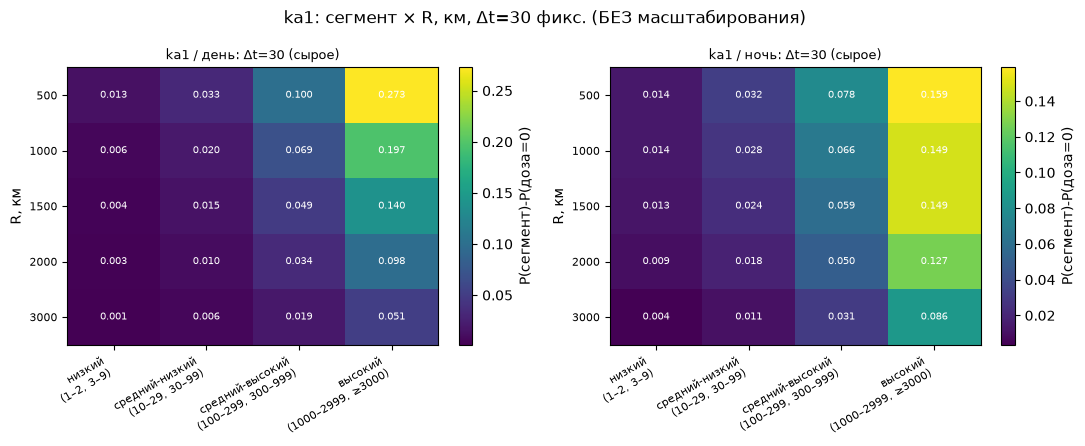

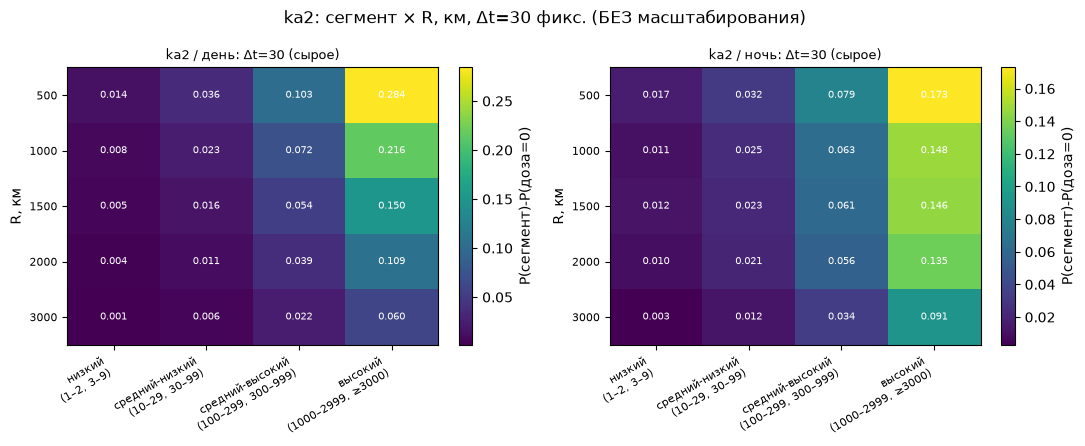


=== График 2 (сырое): фикс. R=1000 км, по Y — Δt ===


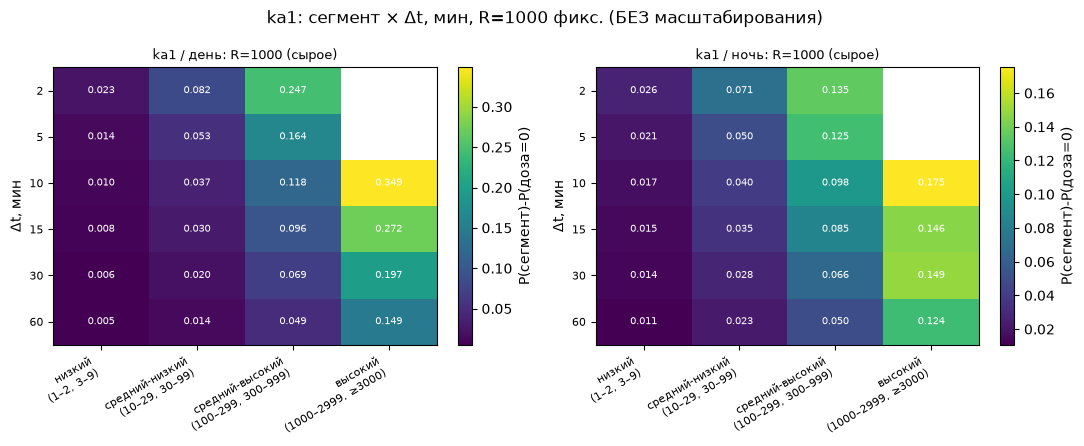

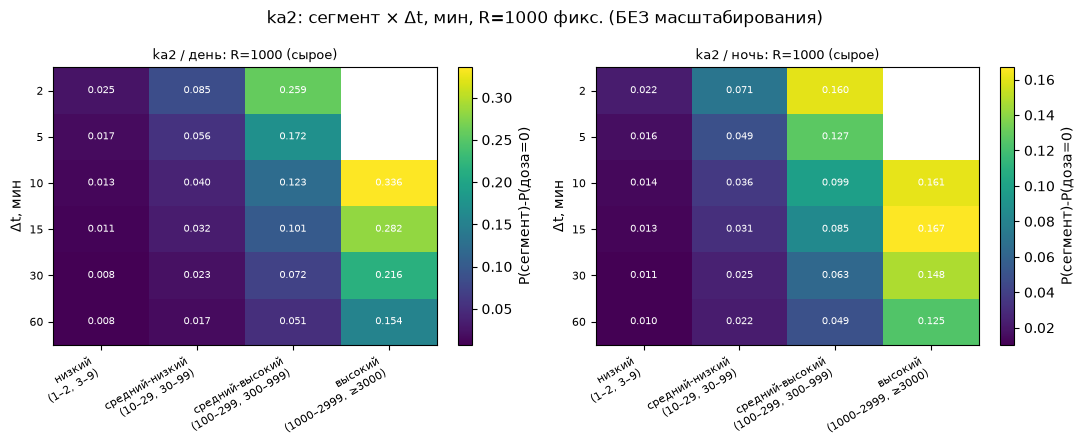


Сравните числа с ячейкой 107 (масштабированный вариант) — если картина по Δt тут уже не такая плоская, значит прежняя плоскостность объяснялась в основном масштабированием, а не отсутствием реальной чувствительности к Δt.


In [54]:
import numpy as np
import matplotlib.pyplot as plt

NIGHT_LABELS = {0: 'день', 1: 'ночь'}
FIX_DT = 30
FIX_R = 1000.0


def _segment_excess_raw(seg_idx, sc_i, night_val, r_km, dt_min):
    accum = sweep_fp_raw_segments[(r_km, dt_min)]
    r = dp.analyze(accum, sc=sc_i, night=night_val, n_boot=30, ref_bin=0, min_strat_exp=MIN_STRAT_EXP)
    ok = (np.isfinite(r['pk_t'][seg_idx]) and r['expo'][seg_idx] >= MIN_REPORT_EXP
          and r['nst'][seg_idx] >= 5)
    return float(r['pk_t'][seg_idx] - r['p0_t'][seg_idx]) if ok else np.nan


def _plot_swapped_raw(fix_label, fix_value, other_list, other_axis_label, get_pair):
    for sc_i, sc in enumerate(DOSE_SC):
        fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
        for col, night_val in enumerate((0, 1)):
            heat = np.full((len(other_list), len(SEGMENT_LABELS) - 1), np.nan)
            for oi, other_val in enumerate(other_list):
                r_km, dt_min = get_pair(other_val)
                for seg_idx in range(1, len(SEGMENT_LABELS)):
                    heat[oi, seg_idx - 1] = _segment_excess_raw(seg_idx, sc_i, night_val, r_km, dt_min)
            ax = axes[col]
            im = ax.imshow(heat, aspect='auto', cmap='viridis')
            ax.set_xticks(range(len(SEGMENT_LABELS) - 1))
            ax.set_xticklabels(SEGMENT_LABELS[1:], rotation=30, ha='right', fontsize=8)
            ax.set_yticks(range(len(other_list)))
            ax.set_yticklabels([f'{v:.0f}' for v in other_list], fontsize=8)
            ax.set_ylabel(other_axis_label)
            ax.set_title(f'{sc} / {NIGHT_LABELS[night_val]}: {fix_label}={fix_value:.0f} (сырое)', fontsize=9)
            for oi in range(len(other_list)):
                for si in range(len(SEGMENT_LABELS) - 1):
                    v = heat[oi, si]
                    if np.isfinite(v):
                        ax.text(si, oi, f'{v:.3f}', ha='center', va='center', color='white', fontsize=7)
            plt.colorbar(im, ax=ax, fraction=0.046, label='P(сегмент)-P(доза=0)')
        fig.suptitle(f'{sc}: сегмент × {other_axis_label}, {fix_label}={fix_value:.0f} фикс. (БЕЗ масштабирования)')
        fig.tight_layout()
        plt.show()
        plt.close(fig)


print(f'=== График 1 (сырое): фикс. Δt={FIX_DT} мин, по Y — R ===')
_plot_swapped_raw('Δt', FIX_DT, R_LIST, 'R, км', lambda r_km: (r_km, FIX_DT))

print(f'\n=== График 2 (сырое): фикс. R={FIX_R:.0f} км, по Y — Δt ===')
_plot_swapped_raw('R', FIX_R, DT_LIST, 'Δt, мин', lambda dt_min: (FIX_R, dt_min))

print('\nОсь цвета — P(сегмент) − P(доза=0). Пороги дозы сырые, без растяжения на Δt/30.')


## Бинарно: «есть доза» (≥1 молния) против «доза = 0»

Градация интенсивности снята: все ненулевые бины склеены в один. Тот же `sweep_fp_raw`, нового прогона нет. Две кривые: разность P(≥1) − P(0) против радиуса при Δt = 30 мин и против окна при R = 1000 км. День и ночь на одних осях.


sweep_fp_binary готов: 10 пар × 2 бина (0 / ≥1 молния).


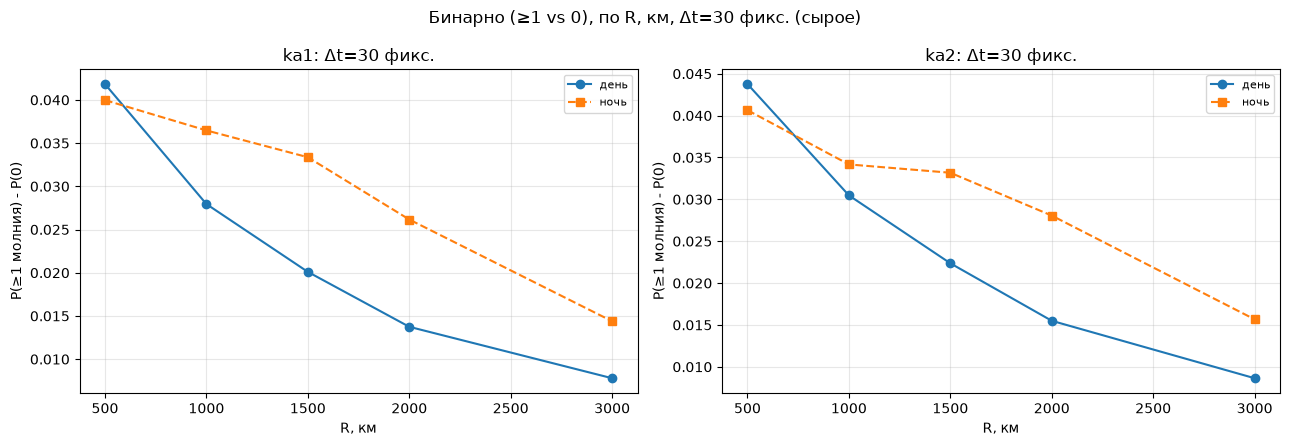

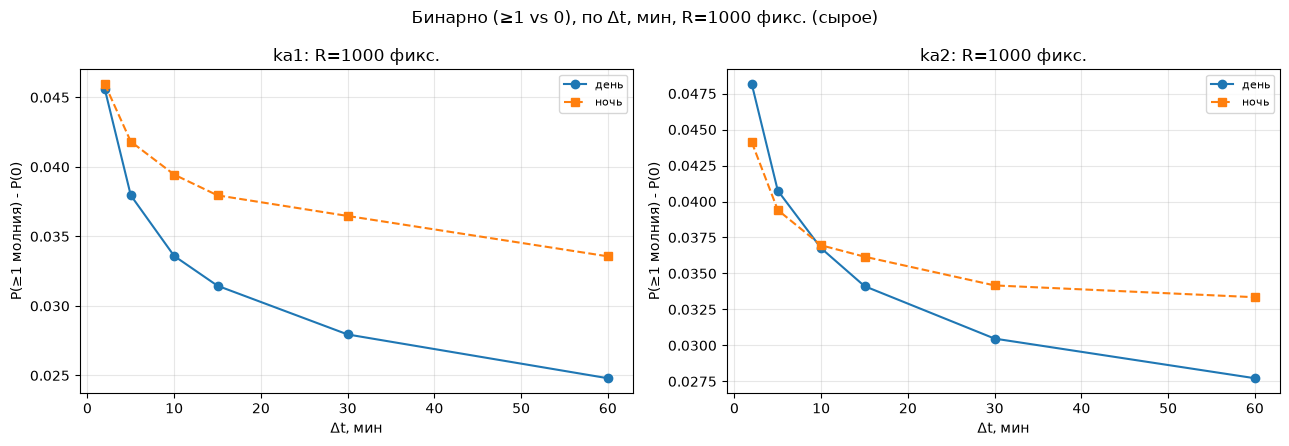

In [55]:
import numpy as np
import matplotlib.pyplot as plt

NIGHT_LABELS = {0: 'день', 1: 'ночь'}
FIX_DT = 30
FIX_R = 1000.0

BINARY_GROUPS = [[0], [1, 2, 3, 4, 5, 6, 7, 8]]
sweep_fp_binary = {pair: merge_dose_bins(sweep_fp_raw[pair], BINARY_GROUPS) for pair in RAW_PAIRS}
print(f'sweep_fp_binary готов: {len(sweep_fp_binary)} пар × 2 бина (0 / ≥1 молния).')


def _binary_excess(sc_i, night_val, r_km, dt_min):
    accum = sweep_fp_binary[(r_km, dt_min)]
    r = dp.analyze(accum, sc=sc_i, night=night_val, n_boot=30, ref_bin=0, min_strat_exp=MIN_STRAT_EXP)
    ok = (np.isfinite(r['pk_t'][1]) and r['expo'][1] >= MIN_REPORT_EXP and r['nst'][1] >= 5)
    return float(r['pk_t'][1] - r['p0_t'][1]) if ok else np.nan


def _plot_binary(fix_label, fix_value, other_list, other_axis_label, get_pair):
    fig, axes = plt.subplots(1, len(DOSE_SC), figsize=(6.5 * len(DOSE_SC), 4.5), squeeze=False)
    for sc_i, sc in enumerate(DOSE_SC):
        ax = axes[0, sc_i]
        for night_val, style in ((0, 'o-'), (1, 's--')):
            vals = [_binary_excess(sc_i, night_val, *get_pair(v)) for v in other_list]
            ax.plot(other_list, vals, style, label=NIGHT_LABELS[night_val])
        ax.set_xlabel(other_axis_label)
        ax.set_ylabel('P(≥1 молния) - P(0)')
        ax.set_title(f'{sc}: {fix_label}={fix_value:.0f} фикс.')
        ax.grid(alpha=0.3)
        ax.legend(fontsize=8)
    fig.suptitle(f'Бинарно (≥1 vs 0), по {other_axis_label}, {fix_label}={fix_value:.0f} фикс. (сырое)')
    fig.tight_layout()
    plt.show()
    plt.close(fig)


_plot_binary('Δt', FIX_DT, R_LIST, 'R, км', lambda r_km: (r_km, FIX_DT))
_plot_binary('R', FIX_R, DT_LIST, 'Δt, мин', lambda dt_min: (FIX_R, dt_min))

## Камчатка

Две оставшиеся картинки. Первая показывает, где малиновая рамка полуострова (`KAM_BOX`, 51…61°N, 156…164°E) лежит на 1° карте внутри грубой страты 45…60°N / 150…180°E. Вторая сравнивает свисты и молнии внутри этой рамки с остальной полосой той же широты, уже без страт Мантеля–Хензеля.

Карта читает `eq_grid` с 1° диагностики и `accum_fp_consistent`.


### Где на карте лежит рамка Камчатки

Зум на грубую страту, в которую попадает якорь (53°N, 158°E): на сетке 12×12 это 45…60°N / 150…180°E. Малиновый контур — `KAM_BOX` (51…61°N, 156…164°E), тот же прямоугольник, что в сравнении с полосой широты ниже.

Сохранённый прогон: в страте 450 из 450 клеток 1° с наблюдениями, 460 937 сэмплов; внутри рамки полуострова 75 809 сэмплов (16.4% страты); севернее 60° рамка выходит из страты, там ещё 7 652 сэмпла.


страта: широта 45…60, долгота 150…180
  1° клеток с наблюдениями: 450 / 450; сэмплов 460,937
  из них в рамке полуострова 51…61°N / 156…164°E: 75,809 сэмплов (16.4% страты)
  север полуострова вне страты (широты ≥ 60°): 7,652 сэмплов


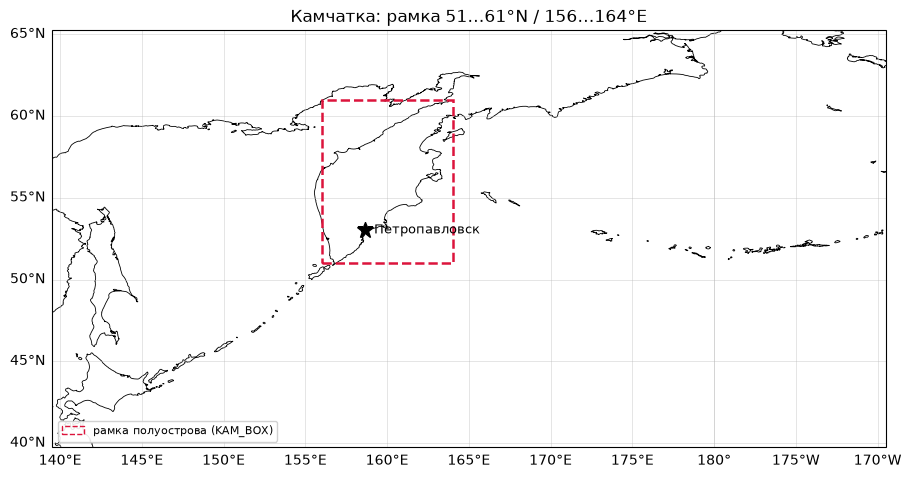

CPU times: user 249 ms, sys: 29.7 ms, total: 279 ms
Wall time: 298 ms


In [7]:
%%time
import numpy as np
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
from matplotlib.patches import Patch, Rectangle

needed = ('eq_grid', '_eq_lat_edges', '_eq_lon_edges', 'accum_fp_consistent')
missing = [n for n in needed if n not in globals() or globals()[n] is None]
if missing:
    raise RuntimeError('Сначала прогоните ячейку с 1°-картой покрытия и накопитель. Нет: '
                       + ', '.join(missing))

KAM_ANCHOR = globals().get('KAM_ANCHOR', (53.0, 158.0))
# контур полуострова (малиновый на карте); тот же KAM_BOX — в сравнении с широтой ниже
KAM_BOX = (51.0, 61.0, 156.0, 164.0)

_le = np.linspace(-90.0, 90.0, accum_fp_consistent['n_latb'] + 1)
_lo = np.linspace(-180.0, 180.0, accum_fp_consistent['n_axis4'] + 1)
_li = int(np.clip(np.searchsorted(_le, KAM_ANCHOR[0], side='right') - 1, 0, len(_le) - 2))
_lj = int(np.clip(np.searchsorted(_lo, KAM_ANCHOR[1], side='right') - 1, 0, len(_lo) - 2))

_eq_lat_c = 0.5 * (_eq_lat_edges[:-1] + _eq_lat_edges[1:])
_eq_lon_c = 0.5 * (_eq_lon_edges[:-1] + _eq_lon_edges[1:])
_in_strat = ((_eq_lat_c[:, None] >= _le[_li]) & (_eq_lat_c[:, None] < _le[_li + 1])
             & (_eq_lon_c[None, :] >= _lo[_lj]) & (_eq_lon_c[None, :] < _lo[_lj + 1]))
_in_kam = ((_eq_lat_c[:, None] >= KAM_BOX[0]) & (_eq_lat_c[:, None] < KAM_BOX[1])
           & (_eq_lon_c[None, :] >= KAM_BOX[2]) & (_eq_lon_c[None, :] < KAM_BOX[3]))

print(f'страта: широта {_le[_li]:.0f}…{_le[_li + 1]:.0f}, '
      f'долгота {_lo[_lj]:.0f}…{_lo[_lj + 1]:.0f}')
print(f'  1° клеток с наблюдениями: {int(np.sum(eq_grid[_in_strat] > 0)):,} / '
      f'{int(_in_strat.sum()):,}; сэмплов {eq_grid[_in_strat].sum():,.0f}')
print(f'  из них в рамке полуострова {KAM_BOX[0]:.0f}…{KAM_BOX[1]:.0f}°N / '
      f'{KAM_BOX[2]:.0f}…{KAM_BOX[3]:.0f}°E: '
      f'{eq_grid[_in_strat & _in_kam].sum():,.0f} сэмплов '
      f'({100.0 * eq_grid[_in_strat & _in_kam].sum() / max(eq_grid[_in_strat].sum(), 1):.1f}% страты)')
print(f'  север полуострова вне страты (широты ≥ {_le[_li + 1]:.0f}°): '
      f'{eq_grid[~_in_strat & _in_kam].sum():,.0f} сэмплов')

# проекцию центрируем на страту: у Камчатки она упирается в 180°, и при
# central_longitude=0 зум за антимеридиан обрезается до всего шара
_clon = 0.5 * (_lo[_lj] + _lo[_lj + 1])
# constrained, не tight_layout: с подписанными gridlines tight_layout ломает
# геометрию рамки GeoAxes (cartopy 0.25 + mpl 3.11, GEOSException на LinearRing)
fig, ax = plt.subplots(figsize=(9, 6), layout='constrained',
                       subplot_kw={'projection': ccrs.PlateCarree(central_longitude=_clon)})
ax.coastlines('10m', linewidth=0.6, color='black')
pc = dict(transform=ccrs.PlateCarree())
ax.add_patch(Rectangle((KAM_BOX[2], KAM_BOX[0]), KAM_BOX[3] - KAM_BOX[2],
                       KAM_BOX[1] - KAM_BOX[0], fill=False, edgecolor='crimson',
                       linewidth=1.8, ls='--', zorder=8, **pc))
ax.plot(158.65, 53.02, marker='*', ms=12, color='black', zorder=9, **pc)
ax.text(159.2, 53.02, 'Петропавловск', fontsize=9, va='center', zorder=9, **pc)
# зум ставим после всех слоёв, рамку кадра держим прежней (клетка 45…60°N / 150…180°E)
_pad_lat, _pad_lon = 0.35 * (_le[1] - _le[0]), 0.35 * (_lo[1] - _lo[0])
ax.set_extent([_lo[_lj] - _pad_lon, _lo[_lj + 1] + _pad_lon,
               max(-90.0, _le[_li] - _pad_lat), min(90.0, _le[_li + 1] + _pad_lat)],
              crs=ccrs.PlateCarree())
gl = ax.gridlines(draw_labels=True, linewidth=0.4, color='0.7', alpha=0.6,
                  xlocs=np.arange(-180.0, 360.1, 5.0), ylocs=np.arange(-90.0, 90.1, 5.0))
gl.top_labels = gl.right_labels = False
# geo_labels=False: иначе cartopy считает позицию заголовка по их bbox и уводит её в inf
gl.geo_labels = False
ax.legend(handles=[
    Patch(facecolor='none', edgecolor='crimson', ls='--', label='рамка полуострова (KAM_BOX)'),
], loc='lower left', fontsize=8, framealpha=0.9)
ax.set_title(f'Камчатка: рамка {KAM_BOX[0]:.0f}…{KAM_BOX[1]:.0f}°N / {KAM_BOX[2]:.0f}…{KAM_BOX[3]:.0f}°E')
plt.show()
plt.close(fig)


### Камчатка vs остальная полоса той же широты (без страт)

Не страта 45…60 / 150…180, а малиновый прямоугольник с карты: `KAM_BOX`
(51…61°N, 156…164°E). Контроль — та же широта, все прочие долготы. Ожидание —
среднее по контролю (то, что было бы, если бы долгота Камчатки не отличалась
от типичной на 51…61°N).

Свисты: сырые `df_pred` (`geo_lat`/`geo_lon`, `verdict`), ночь — `wc.night_mask`
на поверхности в точке сэмпла (`SZA > 98°`), не колонка `is_night` с орбиты.
Молнии: сырой WWLLN (`df`), те же географические рамки. Площадь в полосе
широты пропорциональна Δλ, поэтому доля площади Камчатки = 8°/360°.


регион KAM_BOX: 51…61°N / 156…164°E (без страт, географические координаты)
Свисты: Камчатка vs остальная полоса 51…61°N


,КА,зона,сэмплов,свистов,P(свист),P 95% lo,P 95% hi,доля ночи,P(свист)|день,P(свист)|ночь,ночь/день (P),P / ожидание
0,ka1,Камчатка,"37,652","2,154",0.0572,0.0549,0.0596,0.425,0.0331,0.0897,2.71,1.18
1,ka1,контроль (та же широта),"1,584,567","76,805",0.0485,0.0481,0.0488,0.428,0.0256,0.0791,3.09,1.00
2,ka2,Камчатка,"38,910","2,512",0.0646,0.0621,0.0670,0.427,0.0386,0.0994,2.57,1.19
3,ka2,контроль (та же широта),"1,653,583","89,847",0.0543,0.0540,0.0547,0.434,0.0299,0.0862,2.88,1.00



Молнии WWLLN в полосе 51…61°N. Доля площади Камчатки = 0.0222 (8°/360°).


,зона,молний,молний|день,молний|ночь,доля площади полосы,ожидание (доля площади × полоса),молнии / ожидание,ожидание от контроля,молнии / ожидание контроля,доля ночных разрядов
0,Камчатка,"5,703","5,126",577,0.0222,"88,697",0.06,"90,584",0.06,0.101
1,контроль (та же широта),"3,985,684","3,397,582","588,102",0.9778,"3,902,690",1.02,"3,985,684",1.00,0.148
2,вся полоса 51…61°N,"3,991,387","3,402,708","588,679",1.0000,"3,991,387",1.00,—,—,0.147


ka1 / день: пул-среднее контроля = 0.0256, медиана 2°-бинов вне Камчатки = 0.0214
ka1 / ночь: пул-среднее контроля = 0.0791, медиана 2°-бинов вне Камчатки = 0.0773
ka2 / день: пул-среднее контроля = 0.0299, медиана 2°-бинов вне Камчатки = 0.0256
ka2 / ночь: пул-среднее контроля = 0.0862, медиана 2°-бинов вне Камчатки = 0.0836


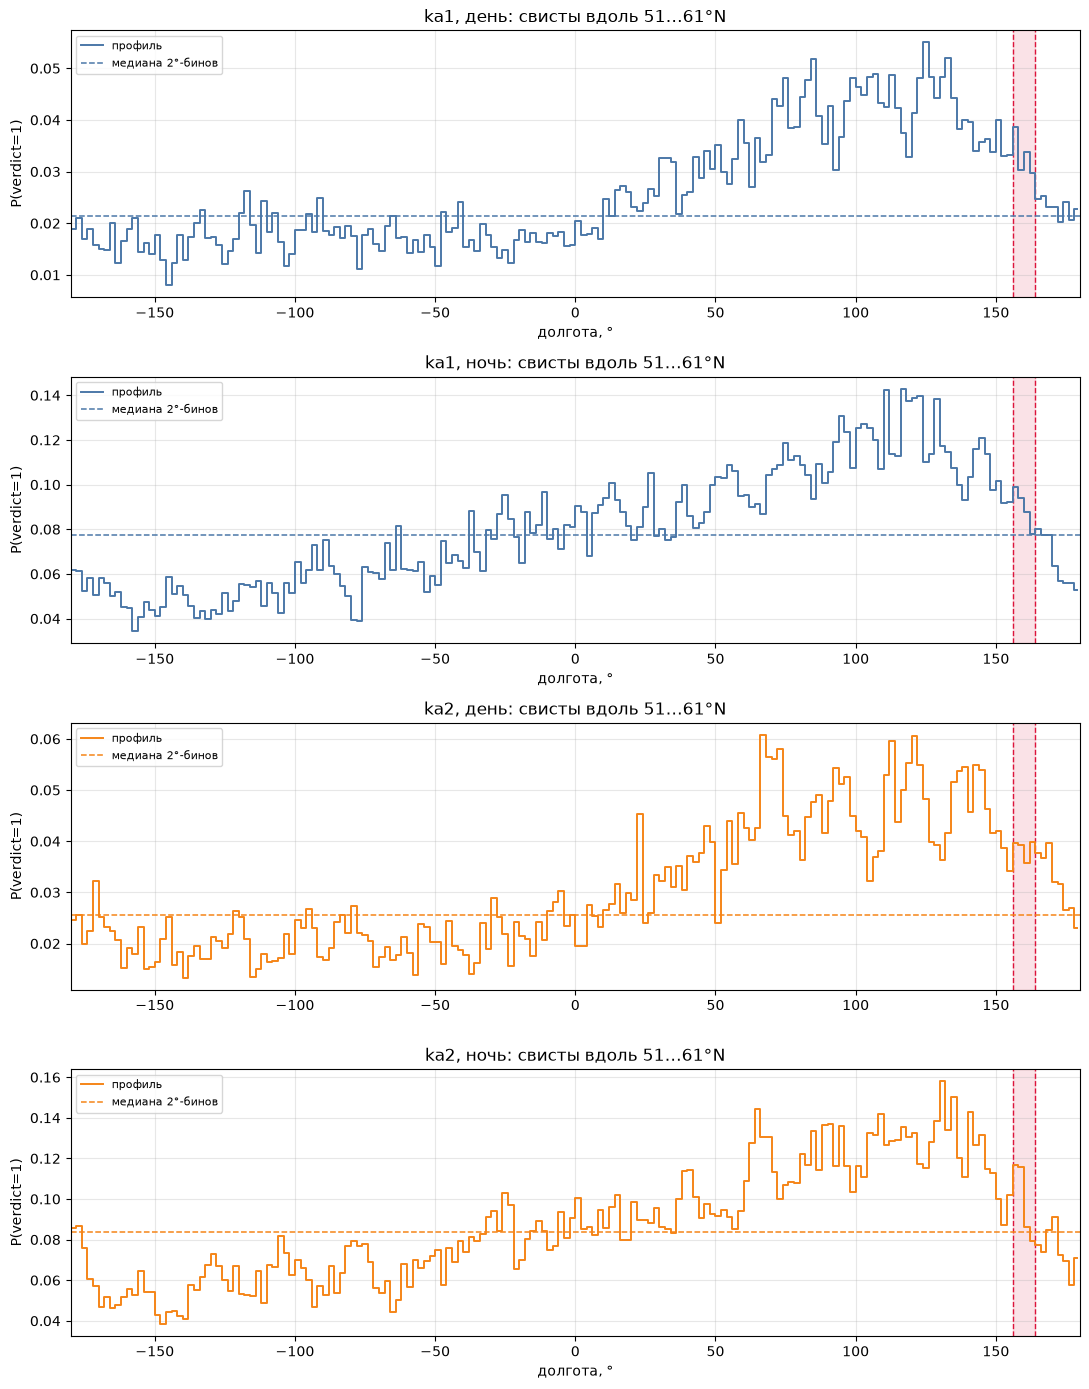

молнии / день: медиана 2°-бинов вне Камчатки = 8,620
молнии / ночь: медиана 2°-бинов вне Камчатки = 1,658


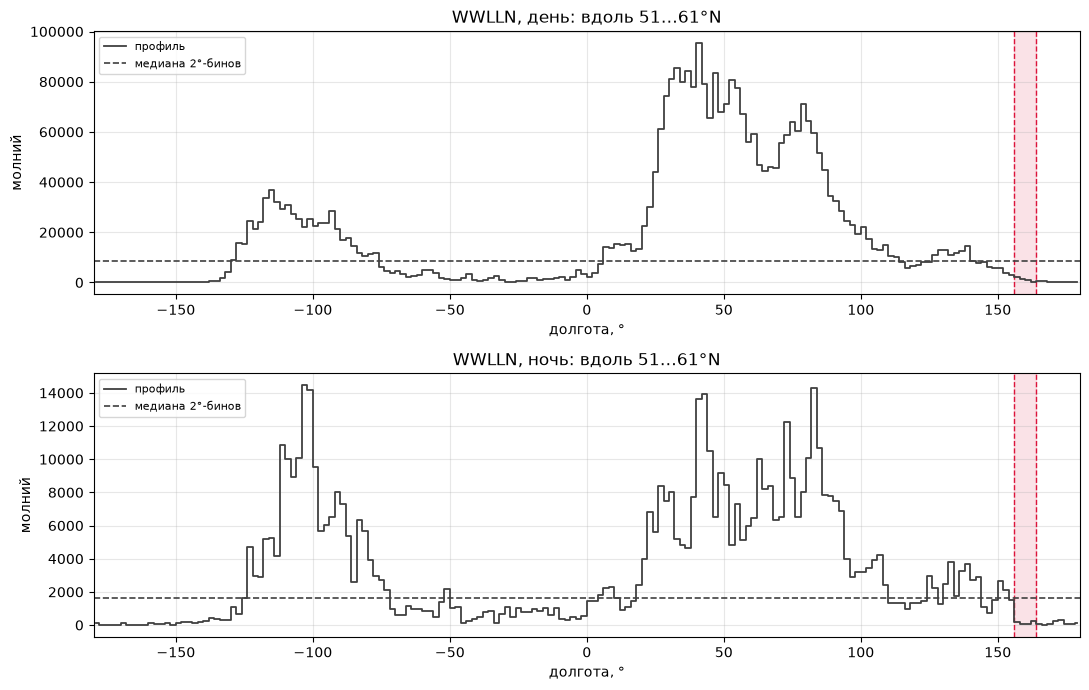

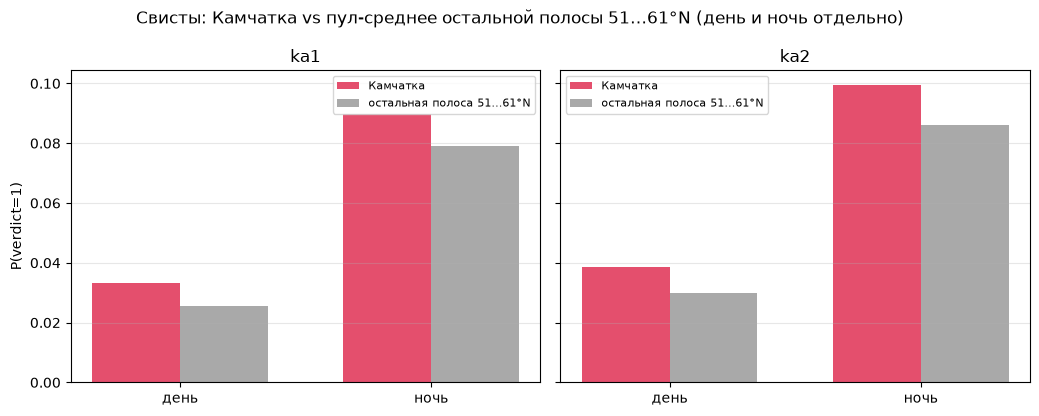


Штрих на профилях — медиана 2°-бинов вне Камчатки. На столбиках серое — пул-среднее P(verdict=1) в контроле, день и ночь отдельно.
CPU times: user 14.5 s, sys: 11.7 s, total: 26.2 s
Wall time: 39.1 s


In [8]:
%%time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

needed = ('df_pred', 'df', 'DOSE_SC', 'NIGHT_SZA_DEG')
missing = [n for n in needed if n not in globals()]
if missing:
    raise RuntimeError('Нет: ' + ', '.join(missing) + ' — прогоните ячейку загрузки')

KAM_BOX = globals().get('KAM_BOX', (51.0, 61.0, 156.0, 164.0))
lat0, lat1, lon0, lon1 = KAM_BOX
print(f'регион KAM_BOX: {lat0:.0f}…{lat1:.0f}°N / {lon0:.0f}…{lon1:.0f}°E '
      f'(без страт, географические координаты)')

f_area = (lon1 - lon0) / 360.0  # доля площади полосы широты


def _lon180(lon):
    return np.mod(np.asarray(lon, dtype=np.float64) + 180.0, 360.0) - 180.0


def _masks(lat, lon):
    lat = np.asarray(lat, dtype=np.float64)
    lon = _lon180(lon)
    in_band = (lat >= lat0) & (lat < lat1)
    in_kam = in_band & (lon >= lon0) & (lon < lon1)
    in_ctrl = in_band & ~in_kam
    return in_band, in_kam, in_ctrl


def _rate_ci(k, n):
    if n <= 0:
        return np.nan, np.nan, np.nan
    p = k / n
    se = np.sqrt(p * (1.0 - p) / n)
    return float(p), float(p - 1.96 * se), float(p + 1.96 * se)


# ----- свисты (подспутниковая точка) -----
p_lat = df_pred['geo_lat'].to_numpy()
p_lon = df_pred['geo_lon'].to_numpy()
p_ver = df_pred['verdict'].to_numpy().astype(np.int8)
p_sc = df_pred['sc'].to_numpy()
p_t = df_pred['timestamp'].to_numpy()
band, kam, ctrl = _masks(p_lat, p_lon)

idx_band = np.flatnonzero(band)
night_band = np.empty(len(p_lat), dtype=np.int8)
night_band[idx_band] = wc.night_mask(
    p_t[idx_band], p_lat[idx_band], _lon180(p_lon[idx_band]), sza_deg=NIGHT_SZA_DEG)

rows = []
for sc in DOSE_SC:
    msc = p_sc == sc
    for name, m in (('Камчатка', kam & msc), ('контроль (та же широта)', ctrl & msc)):
        n = int(m.sum())
        k = int(p_ver[m].sum())
        p, lo, hi = _rate_ci(k, n)
        nd = int((m & (night_band == 0)).sum())
        nn = int((m & (night_band == 1)).sum())
        kd = int(p_ver[m & (night_band == 0)].sum())
        kn = int(p_ver[m & (night_band == 1)].sum())
        pd_, _, _ = _rate_ci(kd, nd)
        pn, _, _ = _rate_ci(kn, nn)
        rows.append({
            'КА': sc, 'зона': name, 'сэмплов': n, 'свистов': k,
            'P(свист)': p, 'P 95% lo': lo, 'P 95% hi': hi,
            'доля ночи': (nn / n if n else np.nan),
            'P(свист)|день': pd_, 'P(свист)|ночь': pn,
            'ночь/день (P)': (pn / pd_ if (pd_ and pd_ > 0) else np.nan),
        })

pred_tbl = pd.DataFrame(rows)
# отношение к ожиданию = контроль той же широты
for sc in DOSE_SC:
    i_k = pred_tbl.index[(pred_tbl['КА'] == sc) & (pred_tbl['зона'] == 'Камчатка')][0]
    i_c = pred_tbl.index[(pred_tbl['КА'] == sc) & (pred_tbl['зона'].str.startswith('контроль'))][0]
    pred_tbl.loc[i_k, 'P / ожидание'] = pred_tbl.loc[i_k, 'P(свист)'] / pred_tbl.loc[i_c, 'P(свист)']
    pred_tbl.loc[i_c, 'P / ожидание'] = 1.0

print('Свисты: Камчатка vs остальная полоса 51…61°N')
_pred_view = pred_tbl.copy()
for _c in ('сэмплов', 'свистов'):
    _pred_view[_c] = _pred_view[_c].map(lambda v: f'{v:,.0f}')
for _c in ('P(свист)', 'P 95% lo', 'P 95% hi', 'P(свист)|день', 'P(свист)|ночь'):
    _pred_view[_c] = _pred_view[_c].map(lambda v: '—' if not np.isfinite(v) else f'{v:.4f}')
for _c in ('доля ночи',):
    _pred_view[_c] = _pred_view[_c].map(lambda v: '—' if not np.isfinite(v) else f'{v:.3f}')
for _c in ('ночь/день (P)', 'P / ожидание'):
    _pred_view[_c] = _pred_view[_c].map(lambda v: '—' if not np.isfinite(v) else f'{v:.2f}')
display(_pred_view)

# ----- молнии -----
a_lat = df['lat'].to_numpy()
a_lon = df['lon'].to_numpy()
a_band, a_kam, a_ctrl = _masks(a_lat, a_lon)
n_k = int(a_kam.sum())
n_c = int(a_ctrl.sum())
n_b = int(a_band.sum())
exp_k = f_area * n_b  # если плотность как в среднем по полосе, включая саму Камчатку
exp_k_ctrl = (lon1 - lon0) / (360.0 - (lon1 - lon0)) * n_c

a_t = df['datetime'].to_numpy()
idx_ab = np.flatnonzero(a_band)
# ночь у молнии — в точке разряда; считаем только в полосе
a_night = np.zeros(len(a_lat), dtype=np.int8)
CHUNK = 2_000_000
ngt_ab = np.empty(idx_ab.size, dtype=np.int8)
for s in range(0, idx_ab.size, CHUNK):
    sl = idx_ab[s:s + CHUNK]
    ngt_ab[s:s + sl.size] = wc.night_mask(
        a_t[sl], a_lat[sl], _lon180(a_lon[sl]), sza_deg=NIGHT_SZA_DEG)
a_night[idx_ab] = ngt_ab

def _ltn_dn(mask):
    nd = int((mask & (a_night == 0)).sum())
    nn = int((mask & (a_night == 1)).sum())
    n = int(mask.sum())
    return nd, nn, (nn / n if n else np.nan)

nd_k, nn_k, frac_night_k = _ltn_dn(a_kam)
nd_c, nn_c, frac_night_c = _ltn_dn(a_ctrl)
nd_b, nn_b, frac_night_b = _ltn_dn(a_band)

ltn = pd.DataFrame([
    {'зона': 'Камчатка', 'молний': n_k, 'молний|день': nd_k, 'молний|ночь': nn_k,
     'доля площади полосы': f_area,
     'ожидание (доля площади × полоса)': exp_k,
     'молнии / ожидание': n_k / exp_k if exp_k else np.nan,
     'ожидание от контроля': exp_k_ctrl,
     'молнии / ожидание контроля': n_k / exp_k_ctrl if exp_k_ctrl else np.nan,
     'доля ночных разрядов': frac_night_k},
    {'зона': 'контроль (та же широта)', 'молний': n_c,
     'молний|день': nd_c, 'молний|ночь': nn_c,
     'доля площади полосы': 1.0 - f_area,
     'ожидание (доля площади × полоса)': (1.0 - f_area) * n_b,
     'молнии / ожидание': n_c / ((1.0 - f_area) * n_b) if n_b else np.nan,
     'ожидание от контроля': n_c,
     'молнии / ожидание контроля': 1.0,
     'доля ночных разрядов': frac_night_c},
    {'зона': 'вся полоса 51…61°N', 'молний': n_b,
     'молний|день': nd_b, 'молний|ночь': nn_b,
     'доля площади полосы': 1.0,
     'ожидание (доля площади × полоса)': n_b, 'молнии / ожидание': 1.0,
     'ожидание от контроля': np.nan, 'молнии / ожидание контроля': np.nan,
     'доля ночных разрядов': frac_night_b},
])
print(f'\nМолнии WWLLN в полосе {lat0:.0f}…{lat1:.0f}°N. '
      f'Доля площади Камчатки = {f_area:.4f} ({lon1 - lon0:.0f}°/360°).')
_ltn_view = ltn.copy()
for _c in ('молний', 'молний|день', 'молний|ночь',
           'ожидание (доля площади × полоса)', 'ожидание от контроля'):
    _ltn_view[_c] = _ltn_view[_c].map(lambda v: '—' if not np.isfinite(v) else f'{v:,.0f}')
for _c in ('доля площади полосы', 'доля ночных разрядов'):
    _ltn_view[_c] = _ltn_view[_c].map(lambda v: '—' if not np.isfinite(v) else f'{v:.4f}' if _c == 'доля площади полосы' else f'{v:.3f}')
for _c in ('молнии / ожидание', 'молнии / ожидание контроля'):
    _ltn_view[_c] = _ltn_view[_c].map(lambda v: '—' if not np.isfinite(v) else f'{v:.2f}')
display(_ltn_view)

# ----- профиль по долготе: наблюдение vs среднее по полосе -----
DLON = 2.0
lon_edges = np.arange(-180.0, 180.0 + 0.5 * DLON, DLON)
lon_c = 0.5 * (lon_edges[:-1] + lon_edges[1:])
p_lon180 = _lon180(p_lon)
a_lon180 = _lon180(a_lon)

def _mark_kam(ax):
    ax.axvspan(lon0, lon1, color='crimson', alpha=0.12, zorder=0)
    ax.axvline(lon0, color='crimson', lw=1.0, ls='--')
    ax.axvline(lon1, color='crimson', lw=1.0, ls='--')


# бины, не пересекающиеся с KAM_BOX — для медианы/среднего профиля без самой Камчатки
_out_kam = ~((lon_edges[:-1] < lon1) & (lon_edges[1:] > lon0))

# свисты: КА × день/ночь, панель не меньше прежней (~3.5")
_sc_colors = ('#4c78a8', '#f58518')
_dn = ((0, 'день', 'P(свист)|день'), (1, 'ночь', 'P(свист)|ночь'))
fig, axes = plt.subplots(len(DOSE_SC) * 2, 1, figsize=(11, 3.5 * len(DOSE_SC) * 2),
                         sharex=True, squeeze=False)
row = 0
for sc, col in zip(DOSE_SC, _sc_colors):
    rec_c = pred_tbl[(pred_tbl['КА'] == sc) & (pred_tbl['зона'].str.startswith('контроль'))].iloc[0]
    for ngt, dn_name, pcol in _dn:
        ax = axes[row, 0]
        row += 1
        _mark_kam(ax)
        m = band & (p_sc == sc) & (night_band == ngt)
        jj = np.clip(((p_lon180[m] + 180.0) / DLON).astype(np.int64), 0, len(lon_c) - 1)
        n_bin = np.bincount(jj, minlength=len(lon_c)).astype(np.float64)
        k_bin = np.bincount(jj, weights=p_ver[m].astype(np.float64), minlength=len(lon_c))
        p_bin = np.divide(k_bin, n_bin, out=np.full(len(lon_c), np.nan), where=n_bin > 0)
        ax.plot(lon_c, p_bin, drawstyle='steps-mid', color=col, lw=1.4, label='профиль')
        p_mean = float(rec_c[pcol])
        p_med = float(np.nanmedian(p_bin[_out_kam]))
        ax.axhline(p_med, color=col, ls='--', lw=1.1, label='медиана 2°-бинов')
        print(f'{sc} / {dn_name}: пул-среднее контроля = {p_mean:.4f}, '
              f'медиана 2°-бинов вне Камчатки = {p_med:.4f}')
        ax.set_ylabel('P(verdict=1)')
        ax.set_title(f'{sc}, {dn_name}: свисты вдоль 51…61°N')
        ax.legend(loc='upper left', fontsize=8)
        ax.grid(alpha=0.3)
        ax.set_xlim(-180, 180)
        ax.tick_params(axis='x', labelbottom=True)
        if row <= 2:  # ka1 день и ka1 ночь
            ax.set_xlabel('долгота, °')
axes[-1, 0].set_xlabel('долгота, °')
fig.tight_layout()
plt.show()
plt.close(fig)

# молнии: день/ночь, панель того же размера, что у свистов
fig, axes = plt.subplots(2, 1, figsize=(11, 3.5 * 2), sharex=True, squeeze=False)
for row, (ngt, dn_name) in enumerate(((0, 'день'), (1, 'ночь'))):
    ax = axes[row, 0]
    _mark_kam(ax)
    m = a_band & (a_night == ngt)
    jj = np.clip(((a_lon180[m] + 180.0) / DLON).astype(np.int64), 0, len(lon_c) - 1)
    n_lon = np.bincount(jj, minlength=len(lon_c)).astype(np.float64)
    n_med = float(np.nanmedian(n_lon[_out_kam]))
    ax.plot(lon_c, n_lon, drawstyle='steps-mid', color='0.25', lw=1.3, label='профиль')
    ax.axhline(n_med, color='0.25', ls='--', lw=1.2, label='медиана 2°-бинов')
    print(f'молнии / {dn_name}: медиана 2°-бинов вне Камчатки = {n_med:,.0f}')
    ax.set_ylabel('молний')
    ax.set_title(f'WWLLN, {dn_name}: вдоль 51…61°N')
    ax.legend(loc='upper left', fontsize=8)
    ax.grid(alpha=0.3)
    ax.set_xlim(-180, 180)
    ax.tick_params(axis='x', labelbottom=True)
    ax.set_xlabel('долгота, °')
axes[-1, 0].set_xlabel('долгота, °')
fig.tight_layout()
plt.show()
plt.close(fig)

# ----- бары: день/ночь, регион vs ожидание -----
fig, axes = plt.subplots(1, len(DOSE_SC), figsize=(10.5, 4.2), sharey=True)
x = np.arange(2)
w = 0.35
for ax, sc in zip(np.atleast_1d(axes), DOSE_SC):
    rec_k = pred_tbl[(pred_tbl['КА'] == sc) & (pred_tbl['зона'] == 'Камчатка')].iloc[0]
    rec_c = pred_tbl[(pred_tbl['КА'] == sc) & (pred_tbl['зона'].str.startswith('контроль'))].iloc[0]
    ax.bar(x - w / 2, [rec_k['P(свист)|день'], rec_k['P(свист)|ночь']], w,
           color='crimson', alpha=0.75, label='Камчатка')
    ax.bar(x + w / 2, [rec_c['P(свист)|день'], rec_c['P(свист)|ночь']], w,
           color='0.55', alpha=0.75, label='остальная полоса 51…61°N')
    ax.set_xticks(x)
    ax.set_xticklabels(['день', 'ночь'])
    ax.set_title(sc)
    ax.grid(axis='y', alpha=0.3)
    ax.legend(fontsize=8)
axes[0].set_ylabel('P(verdict=1)')
fig.suptitle('Свисты: Камчатка vs пул-среднее остальной полосы 51…61°N (день и ночь отдельно)',
             fontsize=12)
fig.tight_layout()
plt.show()
plt.close(fig)

print('\nШтрих на профилях — медиана 2°-бинов вне Камчатки. '
      'На столбиках серое — пул-среднее P(verdict=1) в контроле, день и ночь отдельно.')
